In [83]:
from matplotlib import pyplot as plt
from matplotlib import colors
import numpy as np
from matplotlib.patches import Path, PathPatch
from matplotlib.patches import Patch
import pandas as pd
from shapely.geometry import Point, shape, Polygon
from shapely.ops import unary_union, cascaded_union
from geopandas.tools import sjoin
import geopandas as gpd
from netCDF4 import Dataset
from cartopy import crs as ccrs
from cartopy.io.shapereader import Reader
from sklearn.metrics import mean_squared_error
import scipy.stats as st
from sklearn.linear_model import LinearRegression
from matplotlib.lines import Line2D
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from matplotlib.ticker import FormatStrFormatter
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs

<h1> Load Data

In [2]:
# CMAQ lat/lon datafile
d03 = Dataset('C:/Users/x12la/Desktop/latlon_ChicagoLADCO_d03.nc')
cmaq_lon,cmaq_lat = np.array(d03['lon']),np.array(d03['lat'])
cmaq_llat,cmaq_ulat,cmaq_llon,cmaq_ulon=cmaq_lat.min(), cmaq_lat.max(), cmaq_lon.min(), cmaq_lon.max()

In [3]:
#CMAP 7 counties surrounding Chicago/Cook County
cmap_cty = gpd.read_file('C:/Users/x12la/Desktop/Scripts/CMAP_cty.shp')
cmap_cty = cmap_cty.to_crs('EPSG:4326')

#primary roads
primary_roads = gpd.read_file('C:/Users/x12la/Desktop/Scripts/tl_2016_us_primaryroads.shp')
primary_roads = primary_roads.to_crs('EPSG:4326')

In [4]:
base_aconc = gpd.read_file("../EmissionMod_CTMComp/COMBINE_ACONC_LOCUSIdling_HDVSpatial_2023_annual_censustracts.shp").to_crs("EPSG:4326")
base_o3    = gpd.read_file("../EmissionMod_CTMComp/dailymaxozone_LOCUSIdling_HDVSpatial_2023_annual_censustracts.shp").to_crs("EPSG:4326")

In [5]:
renewal_aconc = gpd.read_file("COMBINE_ACONC_Renewal_Annualized_average_censustracts.shp").to_crs("EPSG:4326")
renewal_o3    = gpd.read_file("MDA8O3_Annualized_Renewal_Average_censustracts.shp").to_crs("EPSG:4326")

In [6]:
zeropre2010s_aconc = gpd.read_file("COMBINE_ACONC_ZeroPre2010s_Annual2023_average_censustracts.shp").to_crs("EPSG:4326")
zeropre2010s_o3    = gpd.read_file("MDA8O3_Annual2023_ZeroPre2010s_Average_censustracts.shp").to_crs("EPSG:4326")

In [7]:
cmap_domain = cmap_cty.geometry.unary_union
cmap_roads = gpd.clip(primary_roads.to_crs("EPSG:4326"), cmap_domain)
cmap_base  = gpd.clip(base_aconc, cmap_domain)
cmap_base_o3     = gpd.clip(base_o3, cmap_domain)
cmap_zeropre2010s = gpd.clip(zeropre2010s_aconc, cmap_domain)
cmap_zeropre2010s_o3    = gpd.clip(zeropre2010s_o3, cmap_domain)
cmap_renewal = gpd.clip(renewal_aconc, cmap_domain)
cmap_renewal_o3    = gpd.clip(renewal_o3, cmap_domain)

In [8]:
# # # Load in NHGIS of the 2019-2023 ACS
demo_data = pd.read_csv('../demographic/nhgis0011_ds267_20235_tract.csv')

census_tracts = gpd.read_file('../demographic/cmap_census_tracts2018.shp')
census_tracts = census_tracts.to_crs('EPSG:4326')

demo_joined = census_tracts.merge(demo_data, on='GISJOIN')
domain_tracts = gpd.clip(census_tracts, cmap_cty.to_crs('EPSG:4326'))
domain_demo   = gpd.clip(demo_joined,  cmap_cty.to_crs('EPSG:4326'))

In [9]:
benmap_df = pd.read_csv("../EmissionMod_CTMComp/BenMAP_Ready_USALEEP_AllCauseRates_OriginalYears.csv")
#benmap_df = pd.read_csv("../demographic/BenMAP_Ready_Tract_Incidence_CountyRatio_Edited.csv")

In [10]:
benmap_df.head()

,Endpoint Group,Endpoint,Race,Gender,Ethnicity,Start Age,End Age,TractFIPS,StateCountyFIPS,Type,Value
0,Mortality,"Mortality, All Cause",NaN,NaN,NaN,0,0,20100,1001,Incidence,0.020097
1,Mortality,"Mortality, All Cause",NaN,NaN,NaN,1,4,20100,1001,Incidence,0.002231
2,Mortality,"Mortality, All Cause",NaN,NaN,NaN,5,14,20100,1001,Incidence,0.000619
3,Mortality,"Mortality, All Cause",NaN,NaN,NaN,15,24,20100,1001,Incidence,0.000865
4,Mortality,"Mortality, All Cause",NaN,NaN,NaN,25,34,20100,1001,Incidence,0.002421


<h1> Data formatting 

In [59]:
# format the county and tract FIPS codes with leading zeros
benmap_df["StateCountyFIPS_v1"] = benmap_df["StateCountyFIPS"].astype(str).str.zfill(5)
benmap_df["TractFIPS_v1"] = benmap_df["TractFIPS"].astype(str).str.zfill(6)

# combine the county and tract codes to create the 11-digit census tract GEOID
benmap_df["GEOID"] = benmap_df["StateCountyFIPS_v1"] + benmap_df["TractFIPS_v1"]

# add this prefix instead if the demographic GEOIDs are formatted as "14000US..."
# benmap_df["GEOID"] = "14000US" + benmap_df["GEOID"]

# match the BenMAP age groups to the corresponding BMR columns
bmr_age_bins = {
    "0-0": "BMR_0_0",
    "1-4": "BMR_1_4",
    "5-14": "BMR_5_14",
    "15-24": "BMR_15_24",
    "25-34": "BMR_25_34",
    "35-44": "BMR_35_44",
    "45-54": "BMR_45_54",
    "55-64": "BMR_55_64",
    "65-74": "BMR_65_74",
    "75-84": "BMR_75_84",
    "85-99": "BMR_85_99",
}

# create the age-bin labels and assign each row to its BMR column
benmap_df["AgeBin"] = benmap_df["Start Age"].astype(str) + "-" + benmap_df["End Age"].astype(str)
benmap_df["BMR_Column"] = benmap_df["AgeBin"].map(bmr_age_bins)

# remove age groups that are not included in the BMR bins
benmap_df = benmap_df.dropna(subset=["BMR_Column"])

# reshape the data so each census tract has one column per BMR age group
bmr_wide_df = benmap_df.pivot_table(
    index="GEOID",
    columns="BMR_Column",
    values="Value",
    aggfunc="first",
).reset_index()

# keep GEOID first and sort the BMR columns by name
bmr_cols = sorted(bmr_wide_df.columns.drop("GEOID"))
bmr_wide_df = bmr_wide_df[["GEOID", *bmr_cols]]

In [60]:
pollutants = ["NO2", "PM25_EC", "PM25_TOT"]

# pull the selected pollutants and add the scenario name to each column
def prep_scenario(df, scenario, columns):
    return df.set_index("GEOID")[columns].add_prefix(f"{scenario}_")


# combine the non-ozone and ozone concentrations for each scenario
aq_scenarios = pd.concat(
    [
        prep_scenario(cmap_base, "base", pollutants),
        prep_scenario(cmap_renewal, "renewal", pollutants),
        prep_scenario(cmap_zeropre2010s, "zeropre2010s", pollutants),
        prep_scenario(cmap_base_o3, "base", ["O3"]),
        prep_scenario(cmap_renewal_o3, "renewal", ["O3"]),
        prep_scenario(cmap_zeropre2010s_o3, "zeropre2010s", ["O3"]),
    ],
    axis=1,
    join="inner",
).reset_index()

# merge the air-quality, demographic, and baseline mortality-rate data by census tract
full_merged = (
    domain_demo
    .merge(aq_scenarios, on="GEOID", how="inner")
    .merge(bmr_wide_df, on="GEOID", how="inner")
)

full_merged

,GISJOIN,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,...,BMR_15_24,BMR_1_4,BMR_25_34,BMR_35_44,BMR_45_54,BMR_55_64,BMR_5_14,BMR_65_74,BMR_75_84,BMR_85_99
0,G1700910010900,17,091,010900,17091010900,109,Census Tract 109,G5020,S,189425605.0,...,0.000923,0.000226,0.001784,0.001916,0.007119,0.010016,0.000125,0.016647,0.042583,0.124401
1,G1800890043401,18,089,043401,18089043401,434.01,Census Tract 434.01,G5020,S,160485773.0,...,0.000397,0.000227,0.000988,0.001073,0.002360,0.009373,0.000123,0.019890,0.062501,0.191983
2,G1701970883902,17,197,883902,17197883902,8839.02,Census Tract 8839.02,G5020,S,116132140.0,...,0.001283,0.000211,0.000929,0.000853,0.002451,0.007468,0.000203,0.017051,0.054653,0.144738
3,G1701970883808,17,197,883808,17197883808,8838.08,Census Tract 8838.08,G5020,S,30930415.0,...,0.000491,0.000135,0.000789,0.000873,0.002193,0.006267,0.000135,0.016378,0.047602,0.145780
4,G1701970883811,17,197,883811,17197883811,8838.11,Census Tract 8838.11,G5020,S,23262854.0,...,0.001339,0.000162,0.001200,0.000531,0.003081,0.007070,0.000088,0.018483,0.085030,0.252770
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1932,G1700970861012,17,097,861012,17097861012,8610.12,Census Tract 8610.12,G5020,S,14845555.0,...,0.000369,0.000134,0.000574,0.001724,0.002265,0.006222,0.000078,0.015847,0.048374,0.172071
1933,G1700970860809,17,097,860809,17097860809,8608.09,Census Tract 8608.09,G5020,S,8400459.0,...,0.000606,0.000129,0.000964,0.000870,0.002465,0.003091,0.000076,0.007860,0.039473,0.179613
1934,G1700970860811,17,097,860811,17097860811,8608.11,Census Tract 8608.11,G5020,S,17538320.0,...,0.000920,0.000143,0.001710,0.000240,0.002647,0.005310,0.000088,0.014616,0.049938,0.392590
1935,G1700970860806,17,097,860806,17097860806,8608.06,Census Tract 8608.06,G5020,S,5128895.0,...,0.000260,0.000141,0.001236,0.000699,0.002935,0.006124,0.000076,0.023256,0.049618,0.219332


In [61]:
# population data 
male_population_columns = {
    "Under 5 years": "ASNQE003",
    "5 to 9 years": "ASNQE004",
    "10 to 14 years": "ASNQE005",
    "15 to 17 years": "ASNQE006",
    "18 and 19 years": "ASNQE007",
    "20 years": "ASNQE008",
    "21 years": "ASNQE009",
    "22 to 24 years": "ASNQE010",
    "25 to 29 years": "ASNQE011",
    "30 to 34 years": "ASNQE012",
    "35 to 39 years": "ASNQE013",
    "40 to 44 years": "ASNQE014",
    "45 to 49 years": "ASNQE015",
    "50 to 54 years": "ASNQE016",
    "55 to 59 years": "ASNQE017",
    "60 and 61 years": "ASNQE018",
    "62 to 64 years": "ASNQE019",
    "65 and 66 years": "ASNQE020",
    "67 to 69 years": "ASNQE021",
    "70 to 74 years": "ASNQE022",
    "75 to 79 years": "ASNQE023",
    "80 to 84 years": "ASNQE024",
    "85 years and over": "ASNQE025"}

female_population_columns = {
    "Under 5 years": "ASNQE027",
    "5 to 9 years": "ASNQE028",
    "10 to 14 years": "ASNQE029",
    "15 to 17 years": "ASNQE030",
    "18 and 19 years": "ASNQE031",
    "20 years": "ASNQE032",
    "21 years": "ASNQE033",
    "22 to 24 years": "ASNQE034",
    "25 to 29 years": "ASNQE035",
    "30 to 34 years": "ASNQE036",
    "35 to 39 years": "ASNQE037",
    "40 to 44 years": "ASNQE038",
    "45 to 49 years": "ASNQE039",
    "50 to 54 years": "ASNQE040",
    "55 to 59 years": "ASNQE041",
    "60 and 61 years": "ASNQE042",
    "62 to 64 years": "ASNQE043",
    "65 and 66 years": "ASNQE044",
    "67 to 69 years": "ASNQE045",
    "70 to 74 years": "ASNQE046",
    "75 to 79 years": "ASNQE047",
    "80 to 84 years": "ASNQE048",
    "85 years and over": "ASNQE049"}

In [62]:
# 1. Calculate baseline mortality over age 30
# ============================================================

age_mapping = {
    "0-0": ["Under 5 years"],
    "1-4": ["Under 5 years"],
    "5-14": ["5 to 9 years", "10 to 14 years"],
    "15-24": ["15 to 17 years", "18 and 19 years", "20 years", "21 years", "22 to 24 years"],
    "25-34": ["25 to 29 years", "30 to 34 years"],
    "35-44": ["35 to 39 years", "40 to 44 years"],
    "45-54": ["45 to 49 years", "50 to 54 years"],
    "55-64": ["55 to 59 years", "60 and 61 years", "62 to 64 years"],
    "65-74": ["65 and 66 years", "67 to 69 years", "70 to 74 years"],
    "75-84": ["75 to 79 years", "80 to 84 years"],
    "85-99": ["85 years and over"]
}

for bmr_age_group, pop_age_groups in age_mapping.items():
    age_label = bmr_age_group.replace("-", "_")
    bmr_col = f"BMR_{age_label}"

    full_merged[f"BM_M_{age_label}"] = 0
    full_merged[f"BM_F_{age_label}"] = 0

    for pop_age_group in pop_age_groups:
        # Pop CT  * BMR CT 
        male_col = male_population_columns.get(pop_age_group)
        female_col = female_population_columns.get(pop_age_group)

        if male_col:
            full_merged[f"BM_M_{age_label}"] += full_merged[bmr_col] * full_merged[male_col]

        if female_col:
            full_merged[f"BM_F_{age_label}"] += full_merged[bmr_col] * full_merged[female_col]


# Only sum BMR groups where the age bin starts at 30+
over30_age_labels = ["35_44", "45_54", "55_64", "65_74", "75_84", "85_99"]

bm_male_cols = [f"BM_M_{age}" for age in over30_age_labels]
bm_female_cols = [f"BM_F_{age}" for age in over30_age_labels]

full_merged["BM_Male_Over30"] = full_merged[bm_male_cols].sum(axis=1)
full_merged["BM_Female_Over30"] = full_merged[bm_female_cols].sum(axis=1)
full_merged["BM_Total_Over30"] = (
    full_merged["BM_Male_Over30"] + full_merged["BM_Female_Over30"])

In [63]:
full_merged["BM_Total_Over30"]

0       37.931616
1       75.458082
2       68.189390
3       32.226805
4       69.845686
          ...    
1932    39.571359
1933    21.098213
1934    41.780773
1935    37.047315
1936    35.057270
Name: BM_Total_Over30, Length: 1937, dtype: float64

In [64]:
over30_groups = [
    "30 to 34 years",
    "35 to 39 years",
    "40 to 44 years",
    "45 to 49 years",
    "50 to 54 years",
    "55 to 59 years",
    "60 and 61 years",
    "62 to 64 years",
    "65 and 66 years",
    "67 to 69 years",
    "70 to 74 years",
    "75 to 79 years",
    "80 to 84 years",
    "85 years and over",
]

male_over30_cols = [male_population_columns[age] for age in over30_groups]
female_over30_cols = [female_population_columns[age] for age in over30_groups]

full_merged["Pop_Over30"] = (
    full_merged[male_over30_cols].sum(axis=1)
    + full_merged[female_over30_cols].sum(axis=1)
)

print(f"Total population 30+: {full_merged['Pop_Over30'].sum():,.0f}")

Total population 30+: 4,893,270


<h1> Calculate attributable mortality by scenario

In [65]:
increment_ppb = 10 / 1.88

beta = np.log(1.04) / increment_ppb
lower = np.log(1.01) / increment_ppb
upper = np.log(1.06) / increment_ppb

print(beta, lower, upper)

## use these outputs in the NO2-- converting 10ug/m3 to ppb 

pollutant_betas = {
    "NO2": {
        "col": "NO2",
        "beta": 0.00738,
        "lower": 0.00187,
        "upper": 0.01096,
    },
    "PM25_TOT": {
        "col": "PM25_TOT",
        "beta": 0.00591,
        "lower": 0.00199,
        "upper": 0.00784,
    },
    "PM25_EC": {
        "col": "PM25_EC",
        "beta": 0.0198,
        "lower": 0.0,
        "upper": 0.0392,
    },
    "O3_WHO": {
        "col": "O3",
        "beta": 0.00956,
        "lower": 0.00488,
        "upper": 0.01420,
    },
    "O3_Turner2016": {
        "col": "O3",
        "beta": 0.00198,
        "lower": 0.000995,
        "upper": 0.00392,
    },
}

scenarios = ["base", "renewal","zeropre2010s"]

for pollutant, info in pollutant_betas.items():
    pollutant_col = info["col"]

    for scenario in scenarios:
        conc_col = f"{scenario}_{pollutant_col}"

        af_col = f"AF_{pollutant}_{scenario}"
        af_lower_col = f"AF_{pollutant}_{scenario}_lower"
        af_upper_col = f"AF_{pollutant}_{scenario}_upper"

        crf_col = f"CRF_{pollutant}_{scenario}"
        crf_lower_col = f"CRF_{pollutant}_{scenario}_lower"
        crf_upper_col = f"CRF_{pollutant}_{scenario}_upper"

        full_merged[af_col] = 1 - np.exp(-info["beta"] * full_merged[conc_col])
        full_merged[af_lower_col] = 1 - np.exp(-info["lower"] * full_merged[conc_col])
        full_merged[af_upper_col] = 1 - np.exp(-info["upper"] * full_merged[conc_col])

        full_merged[crf_col] = full_merged["BM_Total_Over30"] * full_merged[af_col]
        full_merged[crf_lower_col] = full_merged["BM_Total_Over30"] * full_merged[af_lower_col]
        full_merged[crf_upper_col] = full_merged["BM_Total_Over30"] * full_merged[af_upper_col]

0.00737349407281689 0.0018706622003956013 0.010954554727307456


<h1> Calculate Zero Pre2010s Scenario minus baseline mortality differences

In [66]:
for pollutant in pollutant_betas.keys():

    full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base"] = (
        full_merged[f"CRF_{pollutant}_zeropre2010s"]
        - full_merged[f"CRF_{pollutant}_base"]
    )

    full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base_lower"] = (
        full_merged[f"CRF_{pollutant}_zeropre2010s_lower"]
        - full_merged[f"CRF_{pollutant}_base_lower"]
    )

    full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base_upper"] = (
        full_merged[f"CRF_{pollutant}_zeropre2010s_upper"]
        - full_merged[f"CRF_{pollutant}_base_upper"]
    )
    
    full_merged[f"CRF_{pollutant}_renewal_minus_base"] = (
        full_merged[f"CRF_{pollutant}_renewal"]
        - full_merged[f"CRF_{pollutant}_base"]
    )

    full_merged[f"CRF_{pollutant}_renewal_minus_base_lower"] = (
        full_merged[f"CRF_{pollutant}_renewal_lower"]
        - full_merged[f"CRF_{pollutant}_base_lower"]
    )

    full_merged[f"CRF_{pollutant}_renewal_minus_base_upper"] = (
        full_merged[f"CRF_{pollutant}_renewal_upper"]
        - full_merged[f"CRF_{pollutant}_base_upper"]
    )

C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consid

In [67]:
summary_rows = []

for pollutant in pollutant_betas.keys():

    for scenario in scenarios:
        summary_rows.append({
            "Pollutant": pollutant,
            "Metric": scenario,
            "Total": full_merged[f"CRF_{pollutant}_{scenario}"].sum(),
            "Lower": full_merged[f"CRF_{pollutant}_{scenario}_lower"].sum(),
            "Upper": full_merged[f"CRF_{pollutant}_{scenario}_upper"].sum(),
        })
        
    summary_rows.append({
        "Pollutant": pollutant,
        "Metric": "renewal_minus_base",
        "Total": full_merged[f"CRF_{pollutant}_renewal_minus_base"].sum(),
        "Lower": full_merged[f"CRF_{pollutant}_renewal_minus_base_lower"].sum(),
        "Upper": full_merged[f"CRF_{pollutant}_renewal_minus_base_upper"].sum(),
        })
  
    summary_rows.append({
        "Pollutant": pollutant,
        "Metric": "zeropre2010s_minus_base",
        "Total": full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base"].sum(),
        "Lower": full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base_lower"].sum(),
        "Upper": full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base_upper"].sum(),
        })

mortality_summary = pd.DataFrame(summary_rows)

mortality_summary["Total"] = mortality_summary["Total"].round(2)
mortality_summary["Lower"] = mortality_summary["Lower"].round(2)
mortality_summary["Upper"] = mortality_summary["Upper"].round(2)

mortality_summary["Total_round10"] = (
    mortality_summary["Total"] / 10
).round() * 10

mortality_summary["Lower_round10"] = (
    mortality_summary["Lower"] / 10
).round() * 10

mortality_summary["Upper_round10"] = (
    mortality_summary["Upper"] / 10
).round() * 10

mortality_summary["Total_round10"] = mortality_summary["Total_round10"].astype(int)
mortality_summary["Lower_round10"] = mortality_summary["Lower_round10"].astype(int)
mortality_summary["Upper_round10"] = mortality_summary["Upper_round10"].astype(int)

mortality_summary

,Pollutant,Metric,Total,Lower,Upper,Total_round10,Lower_round10,Upper_round10
0,NO2,base,4324.77,1126.56,6309.52,4320,1130,6310
1,NO2,renewal,3937.65,1023.22,5753.70,3940,1020,5750
2,NO2,zeropre2010s,3863.90,1003.51,5647.88,3860,1000,5650
3,NO2,renewal_minus_base,-387.11,-103.34,-555.82,-390,-100,-560
4,NO2,zeropre2010s_minus_base,-460.87,-123.05,-661.65,-460,-120,-660
5,PM25_TOT,base,4023.26,1382.93,5283.49,4020,1380,5280
6,PM25_TOT,renewal,3997.13,1373.76,5249.52,4000,1370,5250
7,PM25_TOT,zeropre2010s,3988.98,1370.89,5238.94,3990,1370,5240
8,PM25_TOT,renewal_minus_base,-26.14,-9.17,-33.97,-30,-10,-30
9,PM25_TOT,zeropre2010s_minus_base,-34.28,-12.04,-44.55,-30,-10,-40


<h1> Population Weighted Exposure 
    
    
<h3>
$$
\text{Domain Total Population Weighted Average Concentrations} = \frac{\sum (\text{Concentrations}_{\text{CT}} \times \text{Population Total}_{\text{CT}})}{\sum (\text{Population Total}_{\text{CT}})}
$$

<h3>
$$
\text{Subgroup Population Weighted Average Concentrations} = \frac{\sum (\text{Concentrations}_{\text{CT}} \times \text{Subgroup Population Total}_{\text{CT}})}{\sum (\text{Subgroup Population Total}_{\text{CT}})}
$$    
    

<h3>
$$
\text{Relative Concentrations Disparity} = \frac{(
\frac{\sum (\text{Concentrations}_{\text{CT}} \times \text{Subgroup Population Total}_{\text{CT}})}{\sum (\text{Subgroup Population Total}_{\text{CT}})})
}{
(\frac{\sum (\text{Concentrations}_{\text{CT}} \times \text{Population Total}_{\text{CT}})}{\sum (\text{Population Total}_{\text{CT}})})
}
$$


In [68]:
cmap_base['MDA8O3'] = cmap_base_o3['O3']
cmap_zeropre2010s['MDA8O3'] = cmap_zeropre2010s_o3['O3']
cmap_renewal['MDA8O3'] = cmap_renewal_o3['O3']

In [69]:
base_joined = domain_demo.merge(cmap_base, on='GISJOIN', how='inner')
renewal_joined = domain_demo.merge(cmap_renewal, on='GISJOIN', how='inner')
zeropre2010s_joined = domain_demo.merge(cmap_zeropre2010s, on='GISJOIN', how='inner')

In [70]:
base_joined['OTHER_POP'] = (
    base_joined['ASOAE001'] - (
        base_joined['ASOAE003'] +   # NH White
        base_joined['ASOAE004'] +   # NH Black
        base_joined['ASOAE006'] +   # NH Asian
        base_joined['ASOAE012']     # Hispanic any race
    )
)

renewal_joined['OTHER_POP'] = (
    renewal_joined['ASOAE001'] - (
        renewal_joined['ASOAE003'] +
        renewal_joined['ASOAE004'] +
        renewal_joined['ASOAE006'] +
        renewal_joined['ASOAE012']
    )
)

zeropre2010s_joined['OTHER_POP'] = (
    zeropre2010s_joined['ASOAE001'] - (
        zeropre2010s_joined['ASOAE003'] +
        zeropre2010s_joined['ASOAE004'] +
        zeropre2010s_joined['ASOAE006'] +
        zeropre2010s_joined['ASOAE012']
    )
)

In [71]:
base_joined['PopWeightedNO2'] = (base_joined['NO2'] * base_joined['ASOAE001']).sum() / base_joined['ASOAE001'].sum()
zeropre2010s_joined['PopWeightedNO2'] = (zeropre2010s_joined['NO2'] * zeropre2010s_joined['ASOAE001']).sum() / zeropre2010s_joined['ASOAE001'].sum()
renewal_joined['PopWeightedNO2'] = (renewal_joined['NO2'] * renewal_joined['ASOAE001']).sum() / renewal_joined['ASOAE001'].sum()

# ------------------------------------------------------------
# subgroup population-weighted concentration
# ------------------------------------------------------------
for df in [base_joined,renewal_joined, zeropre2010s_joined]:
    df['White_PopWeightedNO2'] = (df['NO2'] * df['ASOAE003']).sum() / df['ASOAE003'].sum()
    df['Black_PopWeightedNO2'] = (df['NO2'] * df['ASOAE004']).sum() / df['ASOAE004'].sum()
    df['Hispanic_PopWeightedNO2'] = (df['NO2'] * df['ASOAE012']).sum() / df['ASOAE012'].sum()
    df['Asian_PopWeightedNO2'] = (df['NO2'] * df['ASOAE006']).sum() / df['ASOAE006'].sum()
    df['Other_PopWeightedNO2'] = (df['NO2'] * df['OTHER_POP']).sum() / df['OTHER_POP'].sum()

# ------------------------------------------------------------
# relative disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined,zeropre2010s_joined]:
    df['White_RelNO2'] = df['White_PopWeightedNO2'] / df['PopWeightedNO2']
    df['Black_RelNO2'] = df['Black_PopWeightedNO2'] / df['PopWeightedNO2']
    df['Hispanic_RelNO2'] = df['Hispanic_PopWeightedNO2'] / df['PopWeightedNO2']
    df['Asian_RelNO2'] = df['Asian_PopWeightedNO2'] / df['PopWeightedNO2']
    df['Other_RelNO2'] = df['Other_PopWeightedNO2'] / df['PopWeightedNO2']

# ------------------------------------------------------------
# absolute disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined,zeropre2010s_joined]:
    df['White_AbsNO2'] = df['White_PopWeightedNO2'] - df['PopWeightedNO2']
    df['Black_AbsNO2'] = df['Black_PopWeightedNO2'] - df['PopWeightedNO2']
    df['Hispanic_AbsNO2'] = df['Hispanic_PopWeightedNO2'] - df['PopWeightedNO2']
    df['Asian_AbsNO2'] = df['Asian_PopWeightedNO2'] - df['PopWeightedNO2']
    df['Other_AbsNO2'] = df['Other_PopWeightedNO2'] - df['PopWeightedNO2']

# ------------------------------------------------------------
# summary table
# ------------------------------------------------------------
no2_summary = pd.DataFrame({
    'Base_PopWeighted'    : [base_joined['PopWeightedNO2'].iloc[0], base_joined['White_PopWeightedNO2'].iloc[0], base_joined['Black_PopWeightedNO2'].iloc[0], base_joined['Hispanic_PopWeightedNO2'].iloc[0], base_joined['Asian_PopWeightedNO2'].iloc[0], base_joined['Other_PopWeightedNO2'].iloc[0]],
    'Base_Relative'       : [1.0, base_joined['White_RelNO2'].iloc[0], base_joined['Black_RelNO2'].iloc[0], base_joined['Hispanic_RelNO2'].iloc[0], base_joined['Asian_RelNO2'].iloc[0], base_joined['Other_RelNO2'].iloc[0]],
    'Base_Absolute'       : [0.0, base_joined['White_AbsNO2'].iloc[0], base_joined['Black_AbsNO2'].iloc[0], base_joined['Hispanic_AbsNO2'].iloc[0], base_joined['Asian_AbsNO2'].iloc[0], base_joined['Other_AbsNO2'].iloc[0]],

    'Renewal_PopWeighted'  : [renewal_joined['PopWeightedNO2'].iloc[0], renewal_joined['White_PopWeightedNO2'].iloc[0], renewal_joined['Black_PopWeightedNO2'].iloc[0], renewal_joined['Hispanic_PopWeightedNO2'].iloc[0], renewal_joined['Asian_PopWeightedNO2'].iloc[0], renewal_joined['Other_PopWeightedNO2'].iloc[0]],
    'Renewal_Relative'     : [1.0, renewal_joined['White_RelNO2'].iloc[0], renewal_joined['Black_RelNO2'].iloc[0], renewal_joined['Hispanic_RelNO2'].iloc[0], renewal_joined['Asian_RelNO2'].iloc[0], renewal_joined['Other_RelNO2'].iloc[0]],
    'Renewal_Absolute'     : [0.0, renewal_joined['White_AbsNO2'].iloc[0], renewal_joined['Black_AbsNO2'].iloc[0], renewal_joined['Hispanic_AbsNO2'].iloc[0], renewal_joined['Asian_AbsNO2'].iloc[0], renewal_joined['Other_AbsNO2'].iloc[0]],

    'zeropre2010s_PopWeighted'  : [zeropre2010s_joined['PopWeightedNO2'].iloc[0], zeropre2010s_joined['White_PopWeightedNO2'].iloc[0], zeropre2010s_joined['Black_PopWeightedNO2'].iloc[0], zeropre2010s_joined['Hispanic_PopWeightedNO2'].iloc[0], zeropre2010s_joined['Asian_PopWeightedNO2'].iloc[0], zeropre2010s_joined['Other_PopWeightedNO2'].iloc[0]],
    'zeropre2010s_Relative'     : [1.0, zeropre2010s_joined['White_RelNO2'].iloc[0], zeropre2010s_joined['Black_RelNO2'].iloc[0], zeropre2010s_joined['Hispanic_RelNO2'].iloc[0], zeropre2010s_joined['Asian_RelNO2'].iloc[0], zeropre2010s_joined['Other_RelNO2'].iloc[0]],
    'zeropre2010s_Absolute'     : [0.0, zeropre2010s_joined['White_AbsNO2'].iloc[0], zeropre2010s_joined['Black_AbsNO2'].iloc[0], zeropre2010s_joined['Hispanic_AbsNO2'].iloc[0], zeropre2010s_joined['Asian_AbsNO2'].iloc[0], zeropre2010s_joined['Other_AbsNO2'].iloc[0]],

}, index=['Total','White','Black','Hispanic','Asian','Other'])

print("=== NO2 Summary ===")
print(no2_summary.round(6).to_string())

=== NO2 Summary ===
          Base_PopWeighted  Base_Relative  Base_Absolute  Renewal_PopWeighted  Renewal_Relative  Renewal_Absolute  zeropre2010s_PopWeighted  zeropre2010s_Relative  zeropre2010s_Absolute
Total             9.087728       1.000000       0.000000             8.258354          1.000000          0.000000                  8.102405               1.000000               0.000000
White             8.206743       0.903058      -0.880985             7.410547          0.897340         -0.847807                  7.275985               0.898003              -0.826420
Black            10.457266       1.150702       1.369539             9.569176          1.158727          1.310822                  9.368253               1.156231               1.265848
Hispanic          9.899646       1.089342       0.811919             9.062581          1.097384          0.804228                  8.898437               1.098246               0.796032
Asian             9.164934       1.008496       0.

In [72]:
# ------------------------------------------------------------
# overall population-weighted concentration
# ------------------------------------------------------------
base_joined['PopWeightedPM25_TOT'] = (base_joined['PM25_TOT'] * base_joined['ASOAE001']).sum() / base_joined['ASOAE001'].sum()
zeropre2010s_joined['PopWeightedPM25_TOT'] = (zeropre2010s_joined['PM25_TOT'] * zeropre2010s_joined['ASOAE001']).sum() / zeropre2010s_joined['ASOAE001'].sum()
renewal_joined['PopWeightedPM25_TOT'] = (renewal_joined['PM25_TOT'] * renewal_joined['ASOAE001']).sum() / renewal_joined['ASOAE001'].sum()

# ------------------------------------------------------------
# subgroup population-weighted concentration
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['ASOAE003']).sum() / df['ASOAE003'].sum()
    df['Black_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['ASOAE004']).sum() / df['ASOAE004'].sum()
    df['Hispanic_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['ASOAE012']).sum() / df['ASOAE012'].sum()
    df['Asian_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['ASOAE006']).sum() / df['ASOAE006'].sum()
    df['Other_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['OTHER_POP']).sum() / df['OTHER_POP'].sum()

# ------------------------------------------------------------
# relative disparities
# ------------------------------------------------------------
for df in [base_joined,renewal_joined, zeropre2010s_joined]:
    df['White_RelPM25_TOT'] = df['White_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']
    df['Black_RelPM25_TOT'] = df['Black_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']
    df['Hispanic_RelPM25_TOT'] = df['Hispanic_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']
    df['Asian_RelPM25_TOT'] = df['Asian_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']
    df['Other_RelPM25_TOT'] = df['Other_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']

# ------------------------------------------------------------
# absolute disparities
# ------------------------------------------------------------
for df in [base_joined,renewal_joined, zeropre2010s_joined]:
    df['White_AbsPM25_TOT'] = df['White_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']
    df['Black_AbsPM25_TOT'] = df['Black_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']
    df['Hispanic_AbsPM25_TOT'] = df['Hispanic_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']
    df['Asian_AbsPM25_TOT'] = df['Asian_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']
    df['Other_AbsPM25_TOT'] = df['Other_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']

# ------------------------------------------------------------
# summary table
# ------------------------------------------------------------
pm25_tot_summary = pd.DataFrame({
    'Base_PopWeighted'    : [base_joined['PopWeightedPM25_TOT'].iloc[0], base_joined['White_PopWeightedPM25_TOT'].iloc[0], base_joined['Black_PopWeightedPM25_TOT'].iloc[0], base_joined['Hispanic_PopWeightedPM25_TOT'].iloc[0], base_joined['Asian_PopWeightedPM25_TOT'].iloc[0], base_joined['Other_PopWeightedPM25_TOT'].iloc[0]],
    'Base_Relative'       : [1.0, base_joined['White_RelPM25_TOT'].iloc[0], base_joined['Black_RelPM25_TOT'].iloc[0], base_joined['Hispanic_RelPM25_TOT'].iloc[0], base_joined['Asian_RelPM25_TOT'].iloc[0], base_joined['Other_RelPM25_TOT'].iloc[0]],
    'Base_Absolute'       : [0.0, base_joined['White_AbsPM25_TOT'].iloc[0], base_joined['Black_AbsPM25_TOT'].iloc[0], base_joined['Hispanic_AbsPM25_TOT'].iloc[0], base_joined['Asian_AbsPM25_TOT'].iloc[0], base_joined['Other_AbsPM25_TOT'].iloc[0]],

    'Renewal_PopWeighted'  : [renewal_joined['PopWeightedPM25_TOT'].iloc[0], renewal_joined['White_PopWeightedPM25_TOT'].iloc[0], renewal_joined['Black_PopWeightedPM25_TOT'].iloc[0], renewal_joined['Hispanic_PopWeightedPM25_TOT'].iloc[0], renewal_joined['Asian_PopWeightedPM25_TOT'].iloc[0], renewal_joined['Other_PopWeightedPM25_TOT'].iloc[0]],
    'Renewal_Relative'     : [1.0, renewal_joined['White_RelPM25_TOT'].iloc[0], renewal_joined['Black_RelPM25_TOT'].iloc[0], renewal_joined['Hispanic_RelPM25_TOT'].iloc[0], renewal_joined['Asian_RelPM25_TOT'].iloc[0], renewal_joined['Other_RelPM25_TOT'].iloc[0]],
    'Renewal_Absolute'     : [0.0, renewal_joined['White_AbsPM25_TOT'].iloc[0], renewal_joined['Black_AbsPM25_TOT'].iloc[0], renewal_joined['Hispanic_AbsPM25_TOT'].iloc[0], renewal_joined['Asian_AbsPM25_TOT'].iloc[0], renewal_joined['Other_AbsPM25_TOT'].iloc[0]],

    'zeropre2010s_PopWeighted'  : [zeropre2010s_joined['PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['White_PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['Black_PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['Hispanic_PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['Asian_PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['Other_PopWeightedPM25_TOT'].iloc[0]],
    'zeropre2010s_Relative'     : [1.0, zeropre2010s_joined['White_RelPM25_TOT'].iloc[0], zeropre2010s_joined['Black_RelPM25_TOT'].iloc[0], zeropre2010s_joined['Hispanic_RelPM25_TOT'].iloc[0], zeropre2010s_joined['Asian_RelPM25_TOT'].iloc[0], zeropre2010s_joined['Other_RelPM25_TOT'].iloc[0]],
    'zeropre2010s_Absolute'     : [0.0, zeropre2010s_joined['White_AbsPM25_TOT'].iloc[0], zeropre2010s_joined['Black_AbsPM25_TOT'].iloc[0], zeropre2010s_joined['Hispanic_AbsPM25_TOT'].iloc[0], zeropre2010s_joined['Asian_AbsPM25_TOT'].iloc[0], zeropre2010s_joined['Other_AbsPM25_TOT'].iloc[0]],

}, index=['Total','White','Black','Hispanic','Asian','Other'])

print("\n=== PM25_TOT Summary ===")
print(pm25_tot_summary.round(6).to_string())


=== PM25_TOT Summary ===
          Base_PopWeighted  Base_Relative  Base_Absolute  Renewal_PopWeighted  Renewal_Relative  Renewal_Absolute  zeropre2010s_PopWeighted  zeropre2010s_Relative  zeropre2010s_Absolute
Total            10.512787       1.000000       0.000000            10.442088          1.000000          0.000000                 10.419565               1.000000               0.000000
White            10.201635       0.970403      -0.311151            10.131952          0.970299         -0.310136                 10.114235               0.970697              -0.305329
Black            11.025157       1.048738       0.512371            10.957231          1.049333          0.515143                 10.930780               1.049063               0.511215
Hispanic         10.819507       1.029176       0.306720            10.748039          1.029300          0.305952                 10.719756               1.028810               0.300191
Asian            10.409863       0.990210   

In [73]:
# ------------------------------------------------------------
# overall population-weighted concentration
# ------------------------------------------------------------
base_joined['PopWeightedPM25_EC'] = (base_joined['PM25_EC'] * base_joined['ASOAE001']).sum() / base_joined['ASOAE001'].sum()
zeropre2010s_joined['PopWeightedPM25_EC'] = (zeropre2010s_joined['PM25_EC'] * zeropre2010s_joined['ASOAE001']).sum() / zeropre2010s_joined['ASOAE001'].sum()
renewal_joined['PopWeightedPM25_EC'] = (renewal_joined['PM25_EC'] * renewal_joined['ASOAE001']).sum() / renewal_joined['ASOAE001'].sum()

# ------------------------------------------------------------
# subgroup population-weighted concentration
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['ASOAE003']).sum() / df['ASOAE003'].sum()
    df['Black_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['ASOAE004']).sum() / df['ASOAE004'].sum()
    df['Hispanic_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['ASOAE012']).sum() / df['ASOAE012'].sum()
    df['Asian_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['ASOAE006']).sum() / df['ASOAE006'].sum()
    df['Other_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['OTHER_POP']).sum() / df['OTHER_POP'].sum()

# ------------------------------------------------------------
# relative disparities
# ------------------------------------------------------------
for df in [base_joined,renewal_joined,  zeropre2010s_joined]:
    df['White_RelPM25_EC'] = df['White_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']
    df['Black_RelPM25_EC'] = df['Black_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']
    df['Hispanic_RelPM25_EC'] = df['Hispanic_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']
    df['Asian_RelPM25_EC'] = df['Asian_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']
    df['Other_RelPM25_EC'] = df['Other_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']

# ------------------------------------------------------------
# absolute disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_AbsPM25_EC'] = df['White_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']
    df['Black_AbsPM25_EC'] = df['Black_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']
    df['Hispanic_AbsPM25_EC'] = df['Hispanic_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']
    df['Asian_AbsPM25_EC'] = df['Asian_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']
    df['Other_AbsPM25_EC'] = df['Other_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']

# ------------------------------------------------------------
# summary table
# ------------------------------------------------------------
pm25_ec_summary = pd.DataFrame({
    'Base_PopWeighted'    : [base_joined['PopWeightedPM25_EC'].iloc[0], base_joined['White_PopWeightedPM25_EC'].iloc[0], base_joined['Black_PopWeightedPM25_EC'].iloc[0], base_joined['Hispanic_PopWeightedPM25_EC'].iloc[0], base_joined['Asian_PopWeightedPM25_EC'].iloc[0], base_joined['Other_PopWeightedPM25_EC'].iloc[0]],
    'Base_Relative'       : [1.0, base_joined['White_RelPM25_EC'].iloc[0], base_joined['Black_RelPM25_EC'].iloc[0], base_joined['Hispanic_RelPM25_EC'].iloc[0], base_joined['Asian_RelPM25_EC'].iloc[0], base_joined['Other_RelPM25_EC'].iloc[0]],
    'Base_Absolute'       : [0.0, base_joined['White_AbsPM25_EC'].iloc[0], base_joined['Black_AbsPM25_EC'].iloc[0], base_joined['Hispanic_AbsPM25_EC'].iloc[0], base_joined['Asian_AbsPM25_EC'].iloc[0], base_joined['Other_AbsPM25_EC'].iloc[0]],

    'Renewal_PopWeighted'  : [renewal_joined['PopWeightedPM25_EC'].iloc[0], renewal_joined['White_PopWeightedPM25_EC'].iloc[0], renewal_joined['Black_PopWeightedPM25_EC'].iloc[0], renewal_joined['Hispanic_PopWeightedPM25_EC'].iloc[0], renewal_joined['Asian_PopWeightedPM25_EC'].iloc[0], renewal_joined['Other_PopWeightedPM25_EC'].iloc[0]],
    'Renewal_Relative'     : [1.0, renewal_joined['White_RelPM25_EC'].iloc[0], renewal_joined['Black_RelPM25_EC'].iloc[0], renewal_joined['Hispanic_RelPM25_EC'].iloc[0], renewal_joined['Asian_RelPM25_EC'].iloc[0], renewal_joined['Other_RelPM25_EC'].iloc[0]],
    'Renewal_Absolute'     : [0.0, renewal_joined['White_AbsPM25_EC'].iloc[0], renewal_joined['Black_AbsPM25_EC'].iloc[0], renewal_joined['Hispanic_AbsPM25_EC'].iloc[0], renewal_joined['Asian_AbsPM25_EC'].iloc[0], renewal_joined['Other_AbsPM25_EC'].iloc[0]],

    'zeropre2010s_PopWeighted'  : [zeropre2010s_joined['PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['White_PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['Black_PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['Hispanic_PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['Asian_PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['Other_PopWeightedPM25_EC'].iloc[0]],
    'zeropre2010s_Relative'     : [1.0, zeropre2010s_joined['White_RelPM25_EC'].iloc[0], zeropre2010s_joined['Black_RelPM25_EC'].iloc[0], zeropre2010s_joined['Hispanic_RelPM25_EC'].iloc[0], zeropre2010s_joined['Asian_RelPM25_EC'].iloc[0], zeropre2010s_joined['Other_RelPM25_EC'].iloc[0]],
    'zeropre2010s_Absolute'     : [0.0, zeropre2010s_joined['White_AbsPM25_EC'].iloc[0], zeropre2010s_joined['Black_AbsPM25_EC'].iloc[0], zeropre2010s_joined['Hispanic_AbsPM25_EC'].iloc[0], zeropre2010s_joined['Asian_AbsPM25_EC'].iloc[0], zeropre2010s_joined['Other_AbsPM25_EC'].iloc[0]],

}, index=['Total','White','Black','Hispanic','Asian','Other'])

print("\n=== PM25_EC Summary ===")
print(pm25_ec_summary.round(6).to_string())


=== PM25_EC Summary ===
          Base_PopWeighted  Base_Relative  Base_Absolute  Renewal_PopWeighted  Renewal_Relative  Renewal_Absolute  zeropre2010s_PopWeighted  zeropre2010s_Relative  zeropre2010s_Absolute
Total             0.406834       1.000000       0.000000             0.353728          1.000000          0.000000                  0.352008               1.000000               0.000000
White             0.375957       0.924106      -0.030876             0.325957          0.921490         -0.027771                  0.324601               0.922143              -0.027406
Black             0.452270       1.111684       0.045437             0.394074          1.114059          0.040346                  0.391835               1.113144               0.039828
Hispanic          0.437797       1.076108       0.030963             0.383505          1.084181          0.029777                  0.381476               1.083714               0.029468
Asian             0.407357       1.001286    

In [74]:
# ------------------------------------------------------------
# overall population-weighted concentration
# ------------------------------------------------------------
base_joined['PopWeightedO3'] = (base_joined['O3'] * base_joined['ASOAE001']).sum() / base_joined['ASOAE001'].sum()
zeropre2010s_joined['PopWeightedO3'] = (zeropre2010s_joined['O3'] * zeropre2010s_joined['ASOAE001']).sum() / zeropre2010s_joined['ASOAE001'].sum()
renewal_joined['PopWeightedO3'] = (renewal_joined['O3'] * renewal_joined['ASOAE001']).sum() / renewal_joined['ASOAE001'].sum()

# ------------------------------------------------------------
# subgroup population-weighted concentration
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_PopWeightedO3'] = (df['O3'] * df['ASOAE003']).sum() / df['ASOAE003'].sum()
    df['Black_PopWeightedO3'] = (df['O3'] * df['ASOAE004']).sum() / df['ASOAE004'].sum()
    df['Hispanic_PopWeightedO3'] = (df['O3'] * df['ASOAE012']).sum() / df['ASOAE012'].sum()
    df['Asian_PopWeightedO3'] = (df['O3'] * df['ASOAE006']).sum() / df['ASOAE006'].sum()
    df['Other_PopWeightedO3'] = (df['O3'] * df['OTHER_POP']).sum() / df['OTHER_POP'].sum()

# ------------------------------------------------------------
# relative disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_RelO3'] = df['White_PopWeightedO3'] / df['PopWeightedO3']
    df['Black_RelO3'] = df['Black_PopWeightedO3'] / df['PopWeightedO3']
    df['Hispanic_RelO3'] = df['Hispanic_PopWeightedO3'] / df['PopWeightedO3']
    df['Asian_RelO3'] = df['Asian_PopWeightedO3'] / df['PopWeightedO3']
    df['Other_RelO3'] = df['Other_PopWeightedO3'] / df['PopWeightedO3']

# ------------------------------------------------------------
# absolute disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_AbsO3'] = df['White_PopWeightedO3'] - df['PopWeightedO3']
    df['Black_AbsO3'] = df['Black_PopWeightedO3'] - df['PopWeightedO3']
    df['Hispanic_AbsO3'] = df['Hispanic_PopWeightedO3'] - df['PopWeightedO3']
    df['Asian_AbsO3'] = df['Asian_PopWeightedO3'] - df['PopWeightedO3']
    df['Other_AbsO3'] = df['Other_PopWeightedO3'] - df['PopWeightedO3']


# ------------------------------------------------------------
# summary table
# ------------------------------------------------------------
O3_summary = pd.DataFrame({
    'Base_PopWeighted'    : [base_joined['PopWeightedO3'].iloc[0], base_joined['White_PopWeightedO3'].iloc[0], base_joined['Black_PopWeightedO3'].iloc[0], base_joined['Hispanic_PopWeightedO3'].iloc[0], base_joined['Asian_PopWeightedO3'].iloc[0], base_joined['Other_PopWeightedO3'].iloc[0]],
    'Base_Relative'       : [1.0, base_joined['White_RelO3'].iloc[0], base_joined['Black_RelO3'].iloc[0], base_joined['Hispanic_RelO3'].iloc[0], base_joined['Asian_RelO3'].iloc[0], base_joined['Other_RelO3'].iloc[0]],
    'Base_Absolute'       : [0.0, base_joined['White_AbsO3'].iloc[0], base_joined['Black_AbsO3'].iloc[0], base_joined['Hispanic_AbsO3'].iloc[0], base_joined['Asian_AbsO3'].iloc[0], base_joined['Other_AbsO3'].iloc[0]],

    'Renewal_PopWeighted'  : [renewal_joined['PopWeightedO3'].iloc[0], renewal_joined['White_PopWeightedO3'].iloc[0], renewal_joined['Black_PopWeightedO3'].iloc[0], renewal_joined['Hispanic_PopWeightedO3'].iloc[0], renewal_joined['Asian_PopWeightedO3'].iloc[0], renewal_joined['Other_PopWeightedO3'].iloc[0]],
    'Renewal_Relative'     : [1.0, renewal_joined['White_RelO3'].iloc[0], renewal_joined['Black_RelO3'].iloc[0], renewal_joined['Hispanic_RelO3'].iloc[0], renewal_joined['Asian_RelO3'].iloc[0], renewal_joined['Other_RelO3'].iloc[0]],
    'Renewal_Absolute'     : [0.0, renewal_joined['White_AbsO3'].iloc[0], renewal_joined['Black_AbsO3'].iloc[0], renewal_joined['Hispanic_AbsO3'].iloc[0], renewal_joined['Asian_AbsO3'].iloc[0], renewal_joined['Other_AbsO3'].iloc[0]],

    'zeropre2010s_PopWeighted'  : [zeropre2010s_joined['PopWeightedO3'].iloc[0], zeropre2010s_joined['White_PopWeightedO3'].iloc[0], zeropre2010s_joined['Black_PopWeightedO3'].iloc[0], zeropre2010s_joined['Hispanic_PopWeightedO3'].iloc[0], zeropre2010s_joined['Asian_PopWeightedO3'].iloc[0], zeropre2010s_joined['Other_PopWeightedO3'].iloc[0]],
    'zeropre2010s_Relative'     : [1.0, zeropre2010s_joined['White_RelO3'].iloc[0], zeropre2010s_joined['Black_RelO3'].iloc[0], zeropre2010s_joined['Hispanic_RelO3'].iloc[0], zeropre2010s_joined['Asian_RelO3'].iloc[0], zeropre2010s_joined['Other_RelO3'].iloc[0]],
    'zeropre2010s_Absolute'     : [0.0, zeropre2010s_joined['White_AbsO3'].iloc[0], zeropre2010s_joined['Black_AbsO3'].iloc[0], zeropre2010s_joined['Hispanic_AbsO3'].iloc[0], zeropre2010s_joined['Asian_AbsO3'].iloc[0], zeropre2010s_joined['Other_AbsO3'].iloc[0]],

}, index=['Total','White','Black','Hispanic','Asian','Other'])

print("\n=== O3 Summary ===")
print(O3_summary.round(6).to_string())


=== O3 Summary ===
          Base_PopWeighted  Base_Relative  Base_Absolute  Renewal_PopWeighted  Renewal_Relative  Renewal_Absolute  zeropre2010s_PopWeighted  zeropre2010s_Relative  zeropre2010s_Absolute
Total            34.026842       1.000000       0.000000            34.693385          1.000000          0.000000                 34.819785               1.000000               0.000000
White            34.578502       1.016212       0.551660            35.220814          1.015203          0.527429                 35.330191               1.014659               0.510406
Black            33.165102       0.974675      -0.861741            33.874130          0.976386         -0.819254                 34.036839               0.977514              -0.782946
Hispanic         33.464698       0.983479      -0.562144            34.136454          0.983947         -0.556931                 34.270198               0.984216              -0.549587
Asian            34.146534       1.003518       0.

In [75]:
subgroups_for_plot = ["Total", "White", "Black", "Hispanic", "Asian", "Other"]

colors_for_plot = {
    "Total": "#d9d9d9",
    "White": "#32448A",
    "Black": "#9d94ff",
    "Hispanic": "#ff6961",
    "Asian": "#ffb480",
    "Other": "#77dd77"
}

hatches = {
    "Baseline": "",
    "Accelerated Fleet Renewal": "\\",
    "Legacy Truck Removal": "//",

}

scenario_keys = ["Baseline", "Accelerated Fleet Renewal","Legacy Truck Removal"]
scenario_labels = ["Baseline","Accelerated Fleet Renewal", "Legacy Truck Removal"]

# ------------------------------------------------------------
# NO2
# ------------------------------------------------------------
base_no2_total = no2_summary.loc["Total", "Base_PopWeighted"]
base_no2_white = no2_summary.loc["White", "Base_PopWeighted"]
base_no2_black = no2_summary.loc["Black", "Base_PopWeighted"]
base_no2_hisp  = no2_summary.loc["Hispanic", "Base_PopWeighted"]
base_no2_asian = no2_summary.loc["Asian", "Base_PopWeighted"]
base_no2_other = no2_summary.loc["Other", "Base_PopWeighted"]

Renewal_no2_total = no2_summary.loc["Total", "Renewal_PopWeighted"]
Renewal_no2_white = no2_summary.loc["White", "Renewal_PopWeighted"]
Renewal_no2_black = no2_summary.loc["Black", "Renewal_PopWeighted"]
Renewal_no2_hisp  = no2_summary.loc["Hispanic", "Renewal_PopWeighted"]
Renewal_no2_asian = no2_summary.loc["Asian", "Renewal_PopWeighted"]
Renewal_no2_other = no2_summary.loc["Other", "Renewal_PopWeighted"]

zeropre2010sno2_total = no2_summary.loc["Total", "zeropre2010s_PopWeighted"]
zeropre2010sno2_white = no2_summary.loc["White", "zeropre2010s_PopWeighted"]
zeropre2010sno2_black = no2_summary.loc["Black", "zeropre2010s_PopWeighted"]
zeropre2010sno2_hisp  = no2_summary.loc["Hispanic", "zeropre2010s_PopWeighted"]
zeropre2010sno2_asian = no2_summary.loc["Asian", "zeropre2010s_PopWeighted"]
zeropre2010sno2_other = no2_summary.loc["Other", "zeropre2010s_PopWeighted"]

no2_vals = np.array([
    [base_no2_total,    base_no2_white,    base_no2_black,    base_no2_hisp,    base_no2_asian,    base_no2_other],
    [Renewal_no2_total,  Renewal_no2_white,  Renewal_no2_black,  Renewal_no2_hisp,  Renewal_no2_asian,  Renewal_no2_other],
    [zeropre2010sno2_total,  zeropre2010sno2_white,  zeropre2010sno2_black,  zeropre2010sno2_hisp,  zeropre2010sno2_asian,  zeropre2010sno2_other],
    ], dtype=float)

# ------------------------------------------------------------
# PM25 total
# ------------------------------------------------------------
base_pm25tot_total = pm25_tot_summary.loc["Total", "Base_PopWeighted"]
base_pm25tot_white = pm25_tot_summary.loc["White", "Base_PopWeighted"]
base_pm25tot_black = pm25_tot_summary.loc["Black", "Base_PopWeighted"]
base_pm25tot_hisp  = pm25_tot_summary.loc["Hispanic", "Base_PopWeighted"]
base_pm25tot_asian = pm25_tot_summary.loc["Asian", "Base_PopWeighted"]
base_pm25tot_other = pm25_tot_summary.loc["Other", "Base_PopWeighted"]

Renewal_pm25tot_total = pm25_tot_summary.loc["Total", "Renewal_PopWeighted"]
Renewal_pm25tot_white = pm25_tot_summary.loc["White", "Renewal_PopWeighted"]
Renewal_pm25tot_black = pm25_tot_summary.loc["Black", "Renewal_PopWeighted"]
Renewal_pm25tot_hisp  = pm25_tot_summary.loc["Hispanic", "Renewal_PopWeighted"]
Renewal_pm25tot_asian = pm25_tot_summary.loc["Asian", "Renewal_PopWeighted"]
Renewal_pm25tot_other = pm25_tot_summary.loc["Other", "Renewal_PopWeighted"]

zeropre2010spm25tot_total = pm25_tot_summary.loc["Total", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_white = pm25_tot_summary.loc["White", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_black = pm25_tot_summary.loc["Black", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_hisp  = pm25_tot_summary.loc["Hispanic", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_asian = pm25_tot_summary.loc["Asian", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_other = pm25_tot_summary.loc["Other", "zeropre2010s_PopWeighted"]

pm25tot_vals = np.array([
    [base_pm25tot_total,    base_pm25tot_white,    base_pm25tot_black,    base_pm25tot_hisp,    base_pm25tot_asian,    base_pm25tot_other],
    [Renewal_pm25tot_total,  Renewal_pm25tot_white,  Renewal_pm25tot_black,  Renewal_pm25tot_hisp,  Renewal_pm25tot_asian,  Renewal_pm25tot_other], 
    [zeropre2010spm25tot_total,  zeropre2010spm25tot_white,  zeropre2010spm25tot_black,  zeropre2010spm25tot_hisp,  zeropre2010spm25tot_asian,  zeropre2010spm25tot_other]
    ], dtype=float)

# ------------------------------------------------------------
# PM25 EC
# ------------------------------------------------------------
base_pm25ec_total = pm25_ec_summary.loc["Total", "Base_PopWeighted"]
base_pm25ec_white = pm25_ec_summary.loc["White", "Base_PopWeighted"]
base_pm25ec_black = pm25_ec_summary.loc["Black", "Base_PopWeighted"]
base_pm25ec_hisp  = pm25_ec_summary.loc["Hispanic", "Base_PopWeighted"]
base_pm25ec_asian = pm25_ec_summary.loc["Asian", "Base_PopWeighted"]
base_pm25ec_other = pm25_ec_summary.loc["Other", "Base_PopWeighted"]

Renewal_pm25ec_total = pm25_ec_summary.loc["Total", "Renewal_PopWeighted"]
Renewal_pm25ec_white = pm25_ec_summary.loc["White", "Renewal_PopWeighted"]
Renewal_pm25ec_black = pm25_ec_summary.loc["Black", "Renewal_PopWeighted"]
Renewal_pm25ec_hisp  = pm25_ec_summary.loc["Hispanic", "Renewal_PopWeighted"]
Renewal_pm25ec_asian = pm25_ec_summary.loc["Asian", "Renewal_PopWeighted"]
Renewal_pm25ec_other = pm25_ec_summary.loc["Other", "Renewal_PopWeighted"]

zeropre2010spm25ec_total = pm25_ec_summary.loc["Total", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_white = pm25_ec_summary.loc["White", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_black = pm25_ec_summary.loc["Black", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_hisp  = pm25_ec_summary.loc["Hispanic", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_asian = pm25_ec_summary.loc["Asian", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_other = pm25_ec_summary.loc["Other", "zeropre2010s_PopWeighted"]


pm25ec_vals = np.array([
    [base_pm25ec_total,    base_pm25ec_white,    base_pm25ec_black,    base_pm25ec_hisp,    base_pm25ec_asian,    base_pm25ec_other],
    [Renewal_pm25ec_total,  Renewal_pm25ec_white,  Renewal_pm25ec_black,  Renewal_pm25ec_hisp,  Renewal_pm25ec_asian,  Renewal_pm25ec_other],
    [zeropre2010spm25ec_total,  zeropre2010spm25ec_white,  zeropre2010spm25ec_black,  zeropre2010spm25ec_hisp,  zeropre2010spm25ec_asian,  zeropre2010spm25ec_other],
   ], dtype=float)

# ------------------------------------------------------------
# O3
# ------------------------------------------------------------
base_o3_total = O3_summary.loc["Total", "Base_PopWeighted"]
base_o3_white = O3_summary.loc["White", "Base_PopWeighted"]
base_o3_black = O3_summary.loc["Black", "Base_PopWeighted"]
base_o3_hisp  = O3_summary.loc["Hispanic", "Base_PopWeighted"]
base_o3_asian = O3_summary.loc["Asian", "Base_PopWeighted"]
base_o3_other = O3_summary.loc["Other", "Base_PopWeighted"]

Renewal_o3_total = O3_summary.loc["Total", "Renewal_PopWeighted"]
Renewal_o3_white = O3_summary.loc["White", "Renewal_PopWeighted"]
Renewal_o3_black = O3_summary.loc["Black", "Renewal_PopWeighted"]
Renewal_o3_hisp  = O3_summary.loc["Hispanic", "Renewal_PopWeighted"]
Renewal_o3_asian = O3_summary.loc["Asian", "Renewal_PopWeighted"]
Renewal_o3_other = O3_summary.loc["Other", "Renewal_PopWeighted"]

zeropre2010so3_total = O3_summary.loc["Total", "zeropre2010s_PopWeighted"]
zeropre2010so3_white = O3_summary.loc["White", "zeropre2010s_PopWeighted"]
zeropre2010so3_black = O3_summary.loc["Black", "zeropre2010s_PopWeighted"]
zeropre2010so3_hisp  = O3_summary.loc["Hispanic", "zeropre2010s_PopWeighted"]
zeropre2010so3_asian = O3_summary.loc["Asian", "zeropre2010s_PopWeighted"]
zeropre2010so3_other = O3_summary.loc["Other", "zeropre2010s_PopWeighted"]


o3_vals = np.array([
    [base_o3_total,    base_o3_white,    base_o3_black,    base_o3_hisp,    base_o3_asian,    base_o3_other],
    [Renewal_o3_total,  Renewal_o3_white,  Renewal_o3_black,  Renewal_o3_hisp,  Renewal_o3_asian,  Renewal_o3_other],
    [zeropre2010so3_total,  zeropre2010so3_white,  zeropre2010so3_black,  zeropre2010so3_hisp,  zeropre2010so3_asian,  zeropre2010so3_other],
   ], dtype=float)

In [79]:
# race/ethnicity labels, population columns, and plotting colors
race_population_columns = {
    "Hispanic": "ASOAE012",
    "Asian": "ASOAE006",
    "Black": "ASOAE004",
    "White": "ASOAE003",
    "Other": "OTHER_POP",
}

race_labels = list(race_population_columns)

race_colors = [
    "#ff6961",  # Hispanic
    "#ffb480",  # Asian
    "#9d94ff",  # Black
    "#32448A",  # White
    "#77dd77",  # Other
]


# calculate the population not included in the four specified race/ethnicity groups
full_merged["OTHER_POP"] = full_merged["ASOAE001"] - full_merged[
    ["ASOAE003", "ASOAE004", "ASOAE006", "ASOAE012"]
].sum(axis=1)


# separate census tracts into ten groups based on their exposure
def create_exposure_deciles(df, exposure_column):
    result = df.copy()

    # only include tracts with valid exposure and population data
    valid = result[exposure_column].notna() & result["ASOAE001"].notna() & (result["ASOAE001"] > 0)

    result["Exposure"] = result[exposure_column].where(valid)
    result["Exposure_decile"] = np.nan
    result.loc[valid, "Exposure_decile"] = pd.qcut(
        result.loc[valid, exposure_column],
        q=10,
        labels=False,
        duplicates="drop",) + 1

    return result


# calculate the racial/ethnic composition of each exposure decile
def calculate_race_distribution(df):
    population_columns = list(race_population_columns.values())

    # sum the population in each group within each exposure decile
    counts = (
        df.groupby("Exposure_decile")[population_columns]
        .sum()
        .reindex(range(1, 11), fill_value=0)
        .rename(columns={column: race for race, column in race_population_columns.items()}))

    # convert the population counts to percentages within each decile
    return counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100

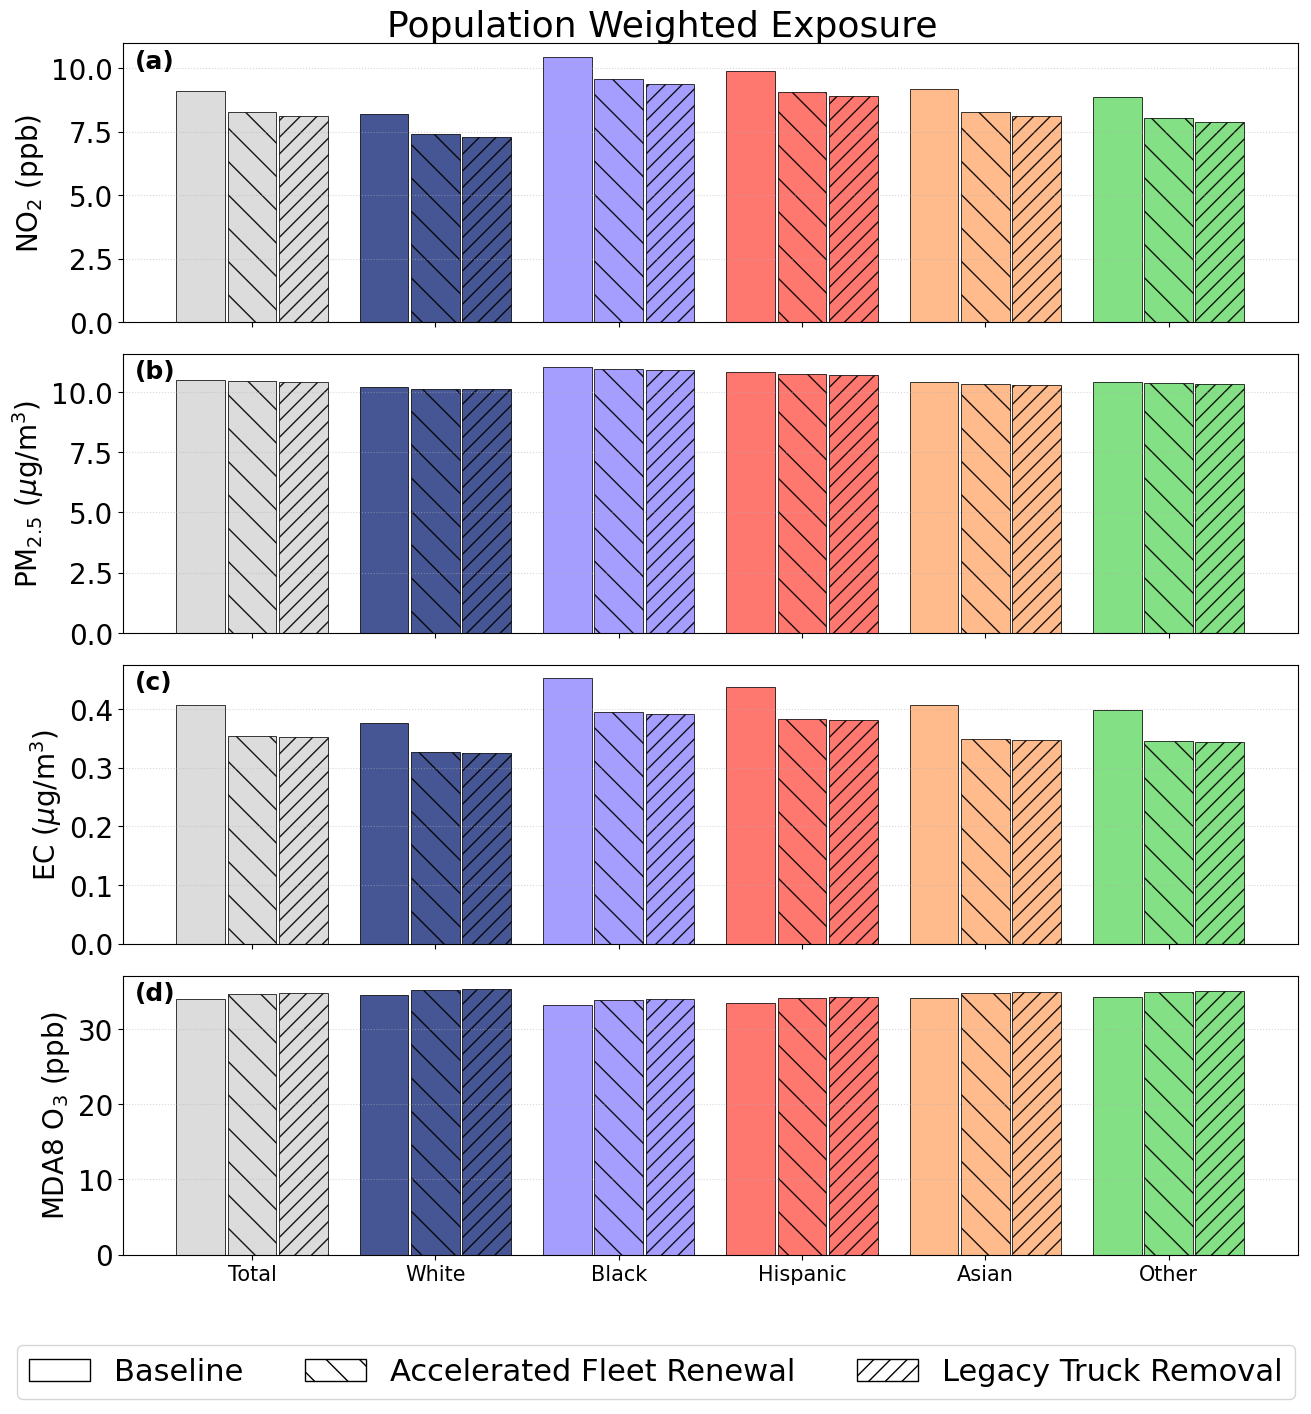

In [77]:
subgroups = ["White", "Black", "Hispanic", "Asian", "Other"]

scenario_labels = {
    "Base": "Baseline",
    "Renewal": "Accelerated Fleet Renewal",
    "zeropre2010s": "Legacy Truck Removal",
}

hatches = {
    "Base": "",
    "Renewal": "\\",
    "zeropre2010s": "//",
}

colors = {
    "White": "#32448A",
    "Black": "#9d94ff",
    "Hispanic": "#ff6961",
    "Asian": "#ffb480",
    "Other": "#77dd77",
}

# define the data and formatting for each pollutant panel
panel_info = [
    (no2_summary, "NO$_2$ (ppb)", "(a)"),
    (pm25_tot_summary, "PM$_{2.5}$ ($\\mu$g/m$^3$)", "(b)"),
    (pm25_ec_summary, "EC ($\\mu$g/m$^3$)", "(c)"),
    (O3_summary, "MDA8 O$_3$ (ppb)", "(d)"),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 16), sharex=True)

x = np.arange(len(subgroups))
bar_width = 0.8 / len(scenario_labels)
offsets = (np.arange(len(scenario_labels)) - 1) * bar_width
bar_colors = [colors[group] for group in subgroups]

# plot the absolute exposure disparities for each pollutant and scenario
for ax, (summary, ylabel, panel_label) in zip(axes, panel_info):
    for offset, scenario in zip(offsets, scenario_labels):
        ax.bar(
            x + offset,
            summary.loc[subgroups, f"{scenario}_Absolute"],
            width=bar_width * 0.95,
            color=bar_colors,
            hatch=hatches[scenario],
            edgecolor="black",
            linewidth=0.6,
        )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.tick_params(axis="y", labelsize=16)
    ax.grid(axis="y", linestyle=":", alpha=0.5)

    # add the panel label in the upper-left corner
    ax.text(
        0.01,
        0.98,
        panel_label,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="top",
        ha="left",
    )

# add the shared race/ethnicity labels to the bottom panel
axes[-1].set_xticks(x)
axes[-1].set_xticklabels(subgroups, fontsize=20)

# use the hatching to identify each emissions scenario
scenario_patches = [
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        hatch=hatches[scenario],
        label=label,
    )
    for scenario, label in scenario_labels.items()
]

fig.suptitle("Absolute Disparities in Exposure", fontsize=26, y=0.99)

fig.legend(
    handles=scenario_patches,
    loc="lower center",
    ncol=3,
    fontsize=22,
    frameon=True,
)

plt.tight_layout(rect=[0, 0.05, 1, 0.98])

# plt.savefig(
#     "AnnualizedEpaDefault_zeropre2010sConcentrationsAbsoluteDisparities.png",
#     dpi=300,
#     bbox_inches="tight",
# )

plt.show()

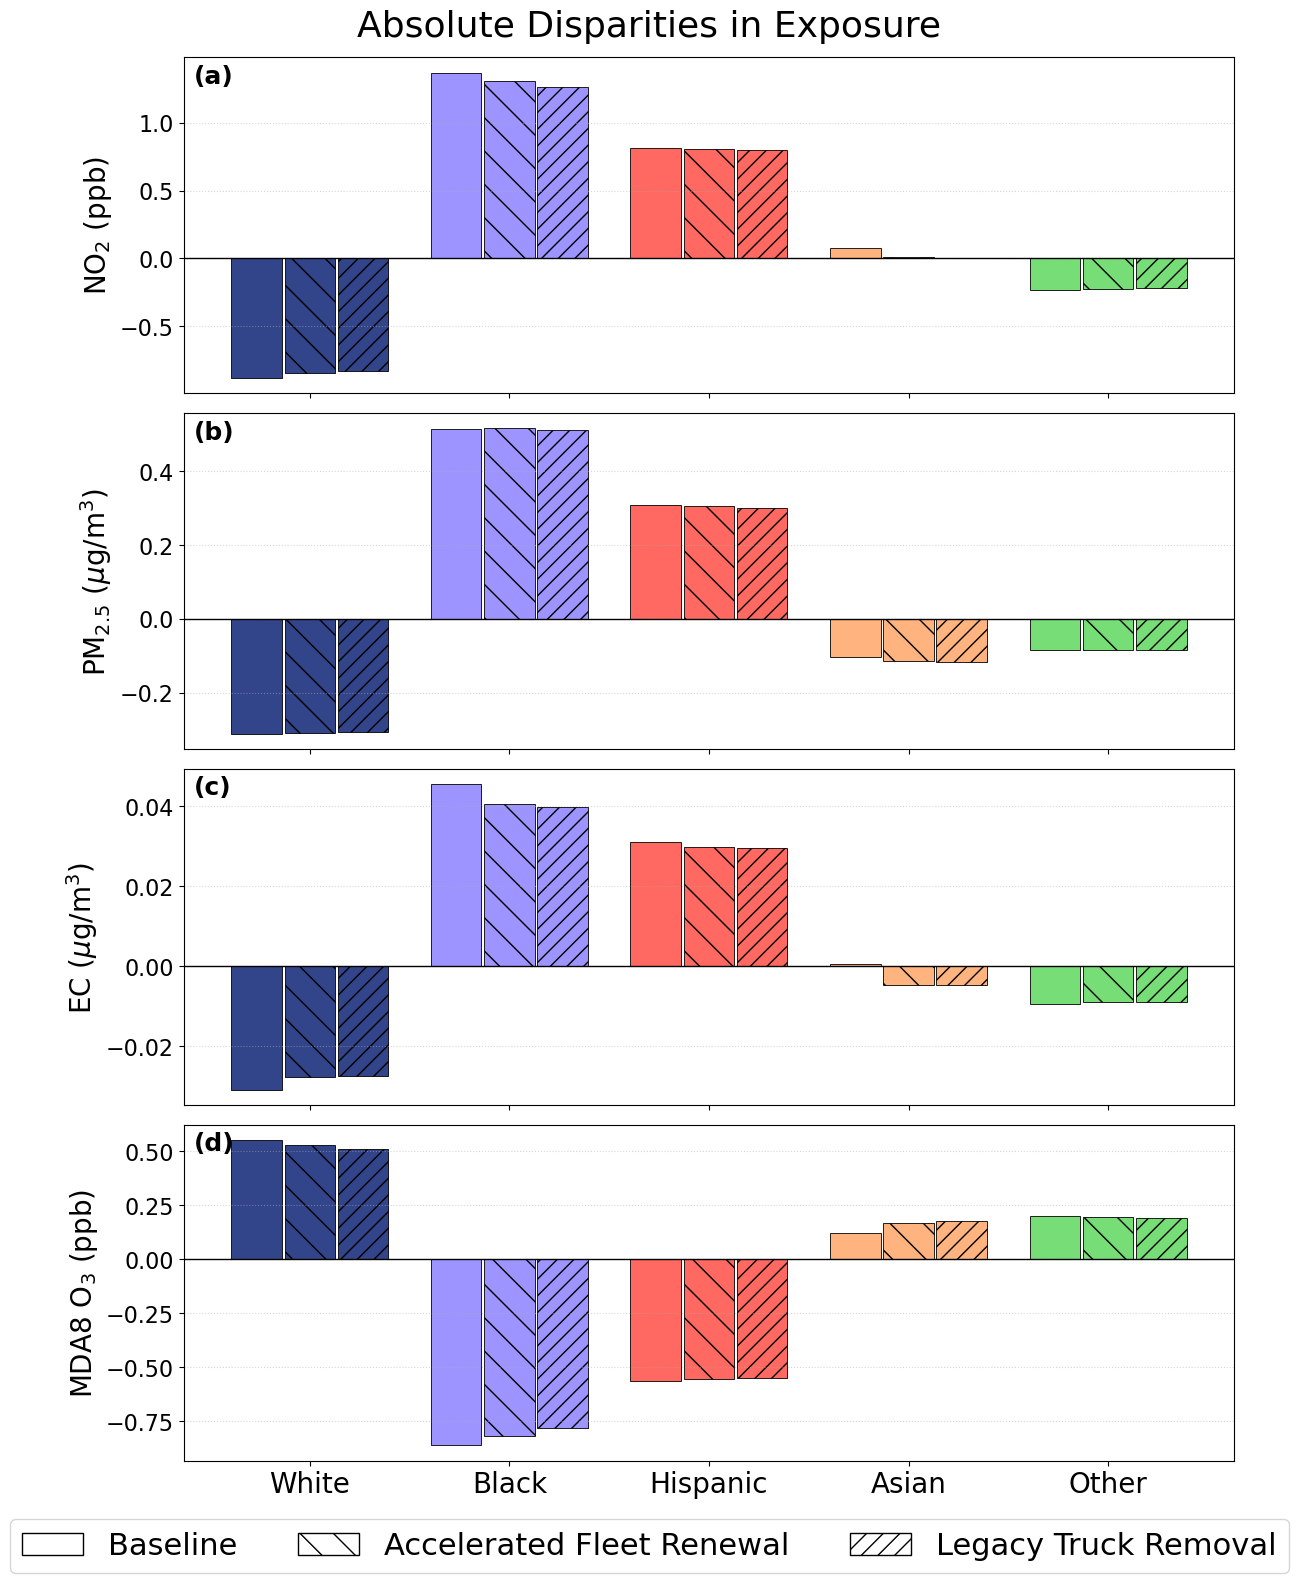

In [81]:
subgroups = ["White", "Black", "Hispanic", "Asian", "Other"]
scenario_keys = ["Base","Renewal", "zeropre2010s"]
scenario_labels = ["Baseline", "Accelerated Fleet Renewal","Legacy Truck Removal"]

hatches = {
    "Base": "",
    "Renewal": "\\",
    "zeropre2010s": "//",
}

colors = {
    "White": "#32448A",
    "Black": "#9d94ff",
    "Hispanic": "#ff6961",
    "Asian": "#ffb480",
    "Other": "#77dd77",
}

fig, axes = plt.subplots(4, 1, figsize=(12, 16), sharex=True)

x = np.arange(len(subgroups))
cluster_w = 0.8
bar_w = cluster_w / len(scenario_keys)
offsets = (np.arange(len(scenario_keys)) - (len(scenario_keys)-1)/2) * bar_w

# ------------------------------------------------------------
# NO2 absolute disparities
# ------------------------------------------------------------
ax = axes[0]

for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups):
        ax.bar(
            x[i] + offsets[s],
            no2_summary.loc[g, f"{key}_Absolute"],
            width=bar_w * 0.95,
            color=colors[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6
        )

ax.axhline(0, color="black", linewidth=1)
#ax.set_title("Absolute NO$_2$ Disparities", fontsize=22)
ax.text(
    0.01, 0.98, labels[0],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.set_ylabel("ppb", fontsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# ------------------------------------------------------------
# PM25_TOT absolute disparities
# ------------------------------------------------------------
ax = axes[1]

for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups):
        ax.bar(
            x[i] + offsets[s],
            pm25_tot_summary.loc[g, f"{key}_Absolute"],
            width=bar_w * 0.95,
            color=colors[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6
        )

ax.axhline(0, color="black", linewidth=1)
#ax.set_title("Absolute PM$_{2.5}$ Disparities", fontsize=22)
ax.set_ylabel(r"$\mu g \, m^{-3}$", fontsize=16)
ax.text(
    0.01, 0.98, labels[1],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.tick_params(axis='y', labelsize=16)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# ------------------------------------------------------------
# PM25_EC absolute disparities
# ------------------------------------------------------------
ax = axes[2]

for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups):
        ax.bar(
            x[i] + offsets[s],
            pm25_ec_summary.loc[g, f"{key}_Absolute"],
            width=bar_w * 0.95,
            color=colors[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6
        )

ax.axhline(0, color="black", linewidth=1)
#ax.set_title("Absolute EC Disparities", fontsize=22)
ax.text(
    0.01, 0.98, labels[2],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.set_ylabel(r"$\mu g \, m^{-3}$", fontsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# ------------------------------------------------------------
# O3 absolute disparities
# ------------------------------------------------------------
ax = axes[3]

for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups):
        ax.bar(
            x[i] + offsets[s],
            O3_summary.loc[g, f"{key}_Absolute"],
            width=bar_w * 0.95,
            color=colors[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6
        )

ax.axhline(0, color="black", linewidth=1)
#ax.set_title("Absolute MDA8 O$_3$ Disparities", fontsize=22)
ax.text(
    0.01, 0.98, labels[3],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.set_ylabel("ppb", fontsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.grid(axis="y", linestyle=":", alpha=0.5)

axes[3].set_xticks(x)
axes[3].set_xticklabels(subgroups, fontsize=20)

scenario_patches = [
    mpatches.Patch(facecolor="white", edgecolor="black", hatch=hatches[k], label=scenario_labels[i])
    for i, k in enumerate(scenario_keys)
]
axes[0].set_ylabel("NO$_2$ (ppb)", fontsize=20)
axes[1].set_ylabel("PM$_{2.5}$ ($\\mu$g/m$^3$)", fontsize=20)
axes[2].set_ylabel("EC ($\\mu$g/m$^3$)", fontsize=20)
axes[3].set_ylabel("MDA8 O$_3$ (ppb)", fontsize=20)

fig.suptitle(
    "Absolute Disparities in Exposure",
    fontsize=26,
    y=0.99,
)
fig.legend(
    handles=scenario_patches,
    fontsize=22,
    loc="lower center",
    ncol=3,
    frameon=True
)
plt.tight_layout(rect=[0, 0.05, 1, 1])
#plt.savefig('AnnualizedEpaDefault_zeropre2010sConcentrationsAbsoluteDisparities.png')
plt.show()

In [84]:
# Total population
total_pop = full_merged["ASOAE001"]

# Population counts
full_merged["Hispanic_pop"] = full_merged["ASOAE012"]
full_merged["Asian_pop"] = full_merged["ASOAE006"]
full_merged["Black_pop"] = full_merged["ASOAE004"]
full_merged["White_pop"] = full_merged["ASOAE003"]
full_merged["Other_pop"] = (total_pop- full_merged["Hispanic_pop"]- full_merged["Asian_pop"] - full_merged["Black_pop"]- full_merged["White_pop"])
full_merged["Other_pop"] = full_merged["Other_pop"].clip(lower=0)

# Convert population counts to tract-level percentages
full_merged["Prc_Hispanic"] = (full_merged["Hispanic_pop"] / total_pop) * 100
full_merged["Prc_Asian"] = (full_merged["Asian_pop"] / total_pop) * 100
full_merged["Prc_Black"] = (full_merged["Black_pop"] / total_pop) * 100
full_merged["Prc_White"] = (full_merged["White_pop"] / total_pop) * 100
full_merged["Prc_Other"] = (full_merged["Other_pop"] / total_pop) * 100

# Remove values from zero-population tracts
race_percent_columns = [
    "Prc_Hispanic",
    "Prc_Asian",
    "Prc_Black",
    "Prc_White",
    "Prc_Other"]

full_merged[race_percent_columns] = (
    full_merged[race_percent_columns]
    .replace([np.inf, -np.inf], np.nan))

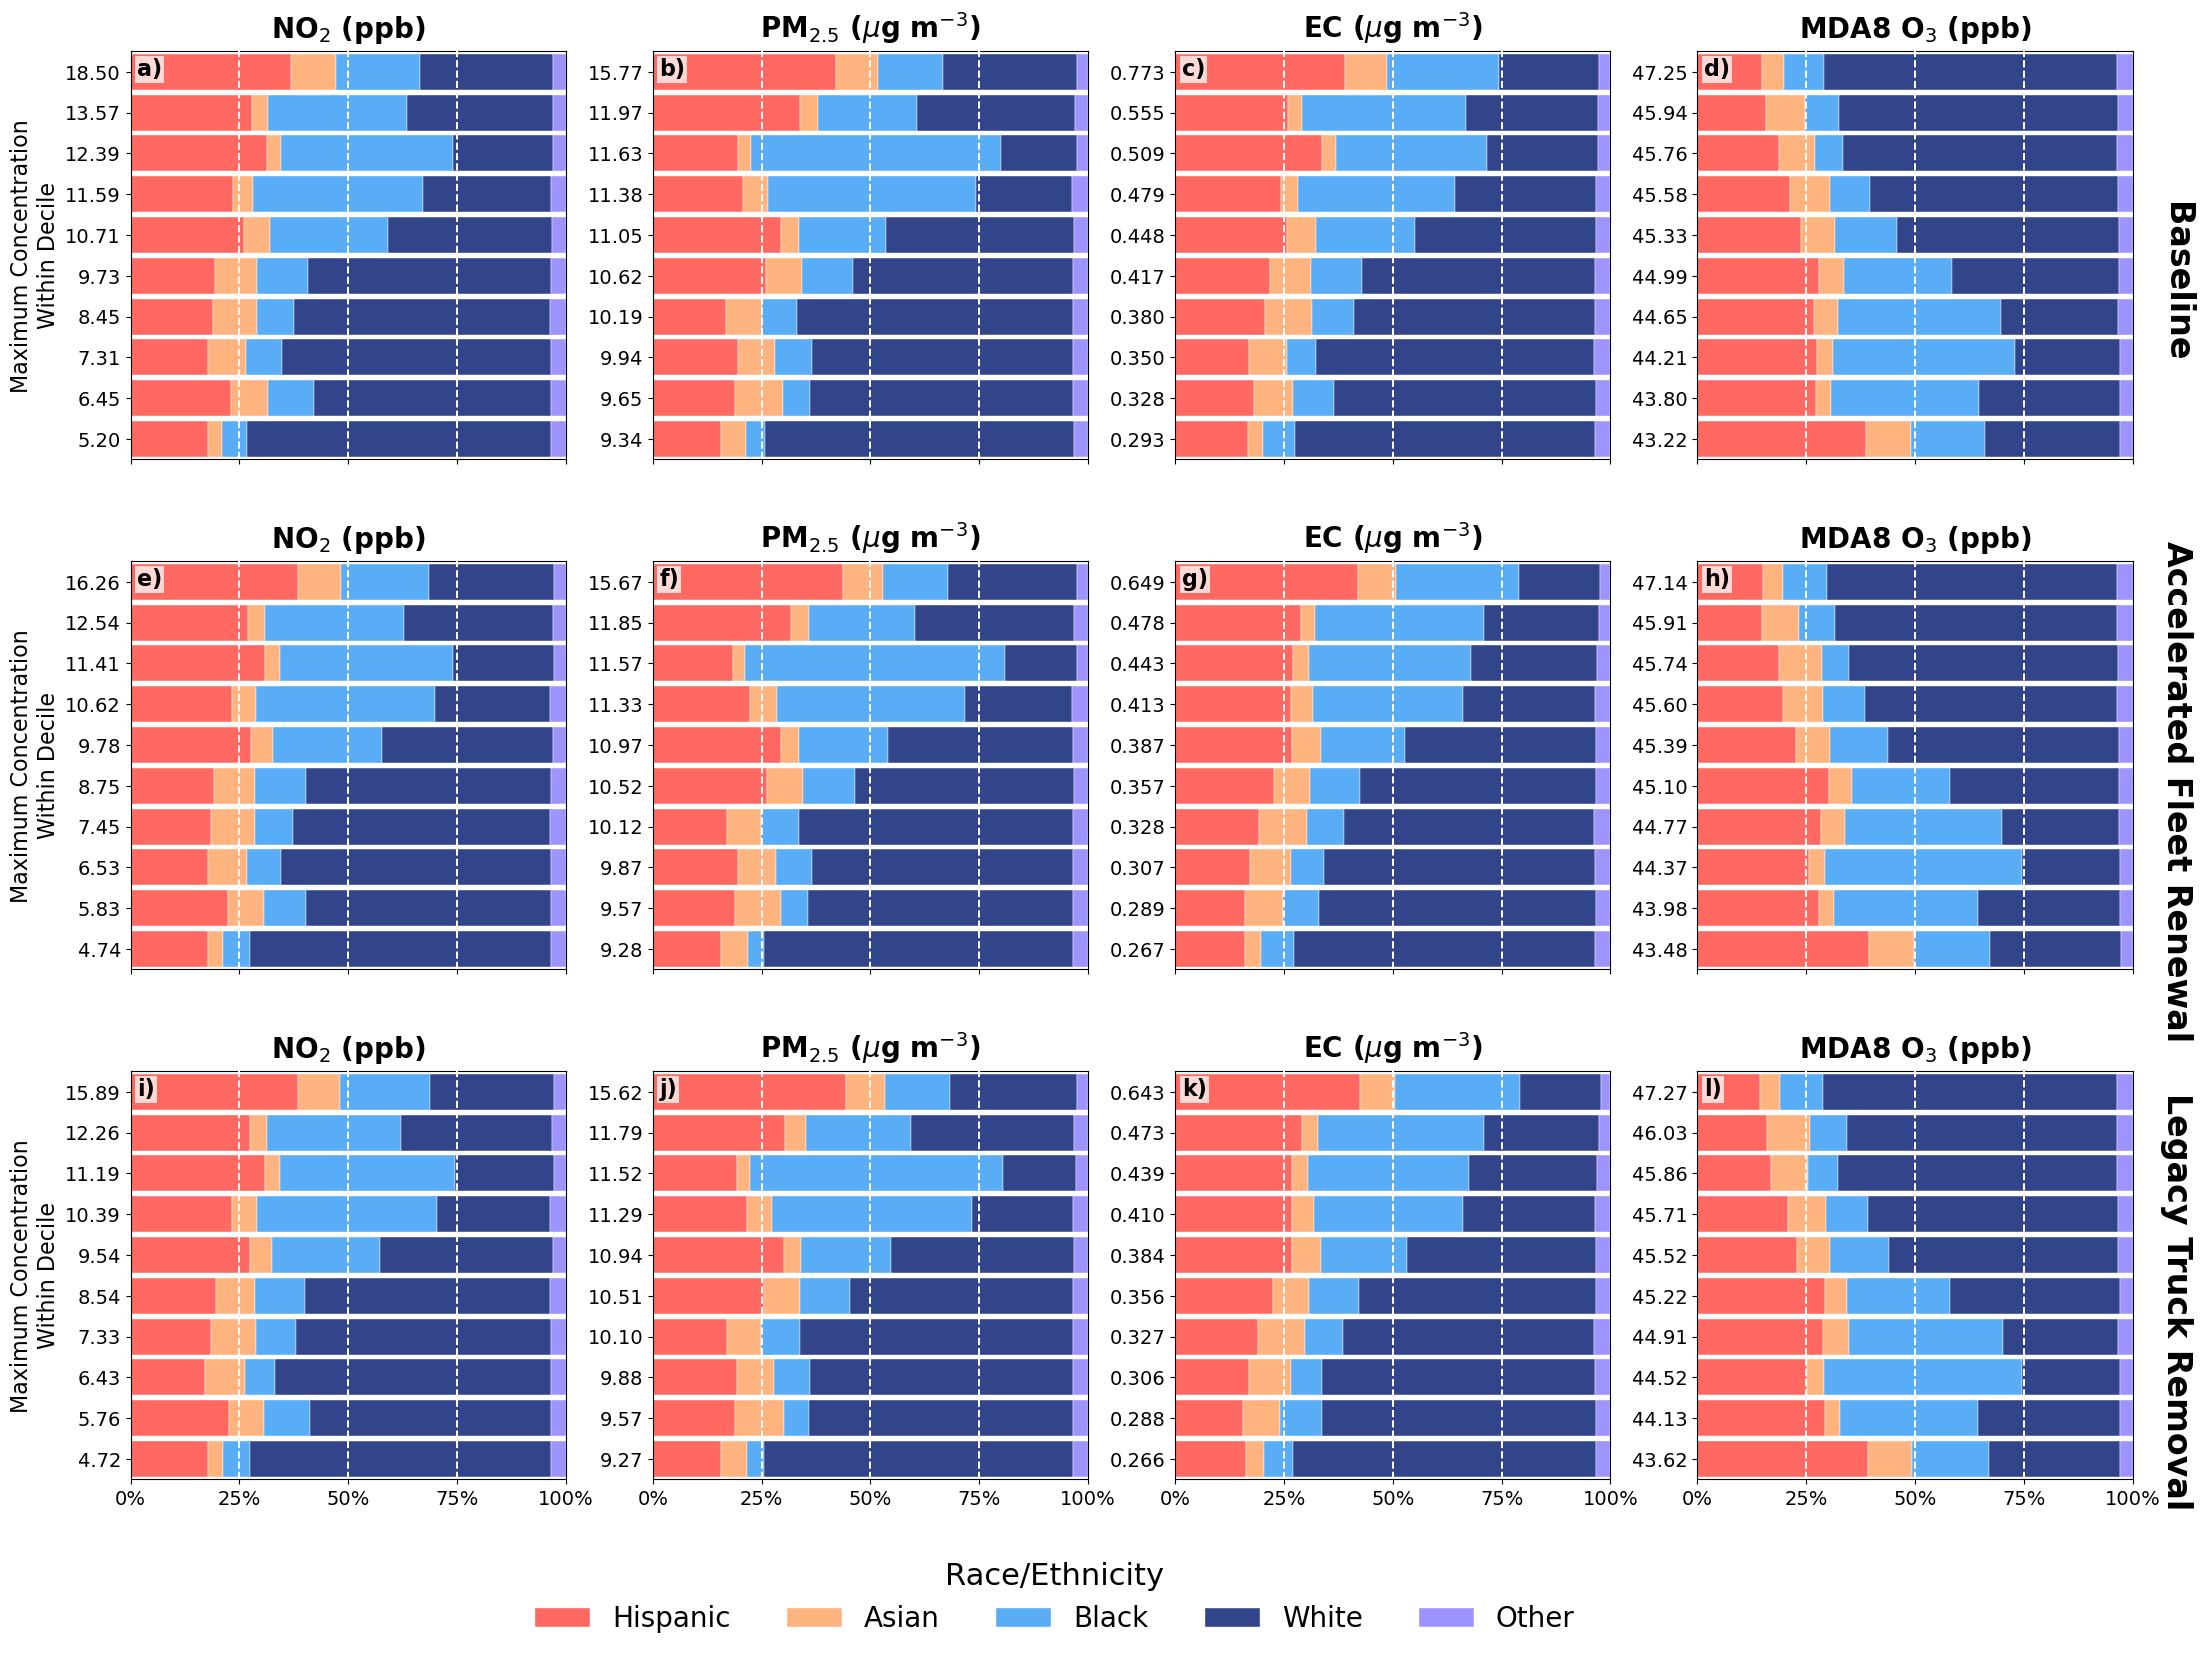

In [85]:
# race/ethnicity percentage columns, labels, and plotting colors
race_info = {
    "Prc_Hispanic": ("Hispanic", "#ff6961"),
    "Prc_Asian": ("Asian", "#ffb480"),
    "Prc_Black": ("Black", "#59adf6"),
    "Prc_White": ("White", "#32448A"),
    "Prc_Other": ("Other", "#9d94ff"),}

race_columns = list(race_info)
race_labels = [label for label, color in race_info.values()]
race_colors = [color for label, color in race_info.values()]

# define the pollutant name, units, and number of decimal places
pollutants = [
    ("NO2", "NO$_2$", "ppb", 2),
    ("PM25_TOT", "PM$_{2.5}$", r"$\mu$g m$^{-3}$", 2),
    ("PM25_EC", "EC", r"$\mu$g m$^{-3}$", 3),
    ("O3", "MDA8 O$_3$", "ppb", 2),]

# define the concentration column prefix and label for each scenario
scenarios = [
    ("base", "Baseline"),
    ("renewal", "Accelerated Fleet Renewal"),
    ("zeropre2010s", "Legacy Truck Removal"),]

# separate census tracts into ten groups based on their exposure
def create_exposure_deciles(df, exposure_column):
    result = df.copy()

    # only include tracts with valid exposure and population data
    valid = result[exposure_column].notna() & result["ASOAE001"].notna() & (result["ASOAE001"] > 0)

    result["Exposure"] = result[exposure_column].where(valid)
    result["Exposure_decile"] = np.nan
    result.loc[valid, "Exposure_decile"] = pd.qcut(
        result.loc[valid, exposure_column],
        q=10,
        labels=False,
        duplicates="drop",) + 1
    return result


# calculate the average racial/ethnic composition of each exposure decile
def calculate_race_distribution(df):
    return df.groupby("Exposure_decile")[race_columns].mean().reindex(range(1, 11))

# plot the racial/ethnic composition of the ten exposure deciles
def plot_decile_panel(ax, df, pollutant_label, units, decimals, show_y_label=False):
    plot_df = df.dropna(subset=["Exposure", "Exposure_decile"]).copy()
    plot_df["Exposure_decile"] = plot_df["Exposure_decile"].astype(int)

    race_distribution = calculate_race_distribution(plot_df)
    y = np.arange(10)
    left = np.zeros(10)

    # create the stacked race/ethnicity bars
    for race_column, color in zip(race_columns, race_colors):
        values = race_distribution[race_column].fillna(0).to_numpy()
        ax.barh(
            y,
            values,
            left=left,
            height=0.88,
            color=color,
            edgecolor="white",
            linewidth=0.3, )
        left += values

    # label each decile using its maximum modeled concentration
    maximum_exposure = plot_df.groupby("Exposure_decile")["Exposure"].max().reindex(range(1, 11))
    concentration_labels = [
        f"{value:.{decimals}f}" if pd.notna(value) else ""
        for value in maximum_exposure]
    ax.set_yticks(y)
    ax.set_yticklabels(concentration_labels, fontsize=14)
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.5, 9.5)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=14)
    ax.set_title(f"{pollutant_label} ({units})", fontsize=20, fontweight="bold", pad=10)
    ax.set_ylabel("Maximum Concentration\nWithin Decile" if show_y_label else "", fontsize=16)
    ax.grid(axis="x", linestyle=":", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)

    # add reference lines over the stacked bars
    for value in [25, 50, 75]:
        ax.axvline(value, color="white", linestyle="--", linewidth=1.4, zorder=5)

# create the three-scenario by four-pollutant figure
fig, axs = plt.subplots(3, 4, figsize=(22, 17), sharex=True, sharey=False)

for row, (scenario, scenario_label) in enumerate(scenarios):
    for column, (pollutant, label, units, decimals) in enumerate(pollutants):
        exposure_df = create_exposure_deciles(full_merged, f"{scenario}_{pollutant}")

        plot_decile_panel(
            axs[row, column],
            exposure_df,
            label,
            units,
            decimals,
            show_y_label=(column == 0),    )

# add the scenario labels along the right side of the figure
row_positions = [0.805, 0.505, 0.205]

for (_, scenario_label), y_position in zip(scenarios, row_positions):
    fig.text(
        1.01,
        y_position,
        scenario_label,
        rotation=270,
        va="center",
        ha="center",
        fontsize=24,
        fontweight="bold", )

# add panel labels from a through l
for i, ax in enumerate(axs.flat):
    ax.text(
        0.015,
        0.985,
        f"{chr(97 + i)})",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=16,
        fontweight="bold",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.75,
            "pad": 1.5,
        },
    )

# create one shared race/ethnicity legend
legend_handles = [
    Patch(facecolor=color, edgecolor="white", label=label)
    for label, color in zip(race_labels, race_colors)]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.005),
    ncol=5,
    title="Race/Ethnicity",
    fontsize=20,
    title_fontsize=22,
    frameon=False,
)

plt.subplots_adjust(
    left=0.08,
    right=0.99,
    top=0.94,
    bottom=0.10,
    wspace=0.20,
    hspace=0.25,
)

plt.savefig(
    "Multipollutant_Exposure_Deciles_RaceEthnicity_3x4.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [42]:
# Population represented in the exposure analysis
pop_cols = {"Total": "ASOAE001", "White": "ASOAE003", "Black": "ASOAE004", "Hispanic": "ASOAE012", "Asian": "ASOAE006", "Other": "OTHER_POP"}

total_pop = base_joined["ASOAE001"].sum()

for group, col in pop_cols.items():
    pop = base_joined[col].sum()
    print(f"{group}: {pop:,.0f} ({pop / total_pop * 100:.1f}%)")

Total: 7,893,946 (100.0%)
White: 3,801,572 (48.2%)
Black: 1,290,733 (16.4%)
Hispanic: 1,965,443 (24.9%)
Asian: 580,367 (7.4%)
Other: 255,831 (3.2%)


In [88]:
groups = ["White", "Black", "Hispanic", "Asian", "Other"]

# calculate the legacy-attributable exposure and the portion removed by renewal
def get_legacy_exposure(summary_df):
    baseline = summary_df.loc[groups, "Base_PopWeighted"]
    renewal = summary_df.loc[groups, "Renewal_PopWeighted"]
    removal = summary_df.loc[groups, "zeropre2010s_PopWeighted"]

    out = pd.DataFrame(index=groups)

    # legacy-attributable pollution is the difference between the baseline and removal scenarios
    out["Legacy attributable"] = baseline - removal

    # calculate how much legacy pollution remains and how much renewal removes
    out["Remaining after renewal"] = renewal - removal
    out["Removed by renewal"] = baseline - renewal

    # calculate the percentage of the legacy-attributable burden eliminated by renewal
    out["Fraction eliminated"] = (
        out["Removed by renewal"]
        .div(out["Legacy attributable"].replace(0, np.nan))
        .mul(100)
    )

    return out


# calculate the exposure changes for each pollutant
no2_legacy = get_legacy_exposure(no2_summary)
pm25_legacy = get_legacy_exposure(pm25_tot_summary)
ec_legacy = get_legacy_exposure(pm25_ec_summary)
o3_legacy = get_legacy_exposure(O3_summary)

In [89]:
print("NO2")
display(no2_legacy)

print("PM2.5")
display(pm25_legacy)

print("EC")
display(ec_legacy)

print("MDA8 O3")
display(o3_legacy)

NO2


,Legacy attributable,Remaining after renewal,Removed by renewal,Fraction eliminated
White,0.930758,0.134562,0.796196,85.542739
Black,1.089014,0.200923,0.888090,81.549969
Hispanic,1.001209,0.164144,0.837065,83.605434
Asian,1.062469,0.169673,0.892797,84.030338
Other,0.975926,0.152742,0.823184,84.348977


PM2.5


,Legacy attributable,Remaining after renewal,Removed by renewal,Fraction eliminated
White,0.087400,0.017717,0.069683,79.728647
Black,0.094378,0.026451,0.067926,71.972834
Hispanic,0.099752,0.028284,0.071468,71.645678
Asian,0.107019,0.026112,0.080907,75.600806
Other,0.092438,0.021725,0.070713,76.497580


EC


,Legacy attributable,Remaining after renewal,Removed by renewal,Fraction eliminated
White,0.051356,0.001356,0.050001,97.360307
Black,0.060435,0.002239,0.058197,96.295800
Hispanic,0.056321,0.002030,0.054292,96.396443
Asian,0.060234,0.001943,0.058291,96.774741
Other,0.054331,0.001651,0.052680,96.961212


MDA8 O3


,Legacy attributable,Remaining after renewal,Removed by renewal,Fraction eliminated
White,-0.751688,-0.109377,-0.642311,85.449113
Black,-0.871737,-0.162709,-0.709029,81.335126
Hispanic,-0.805500,-0.133744,-0.671756,83.396182
Asian,-0.848260,-0.133636,-0.714624,84.245831
Other,-0.786468,-0.123346,-0.663122,84.316419


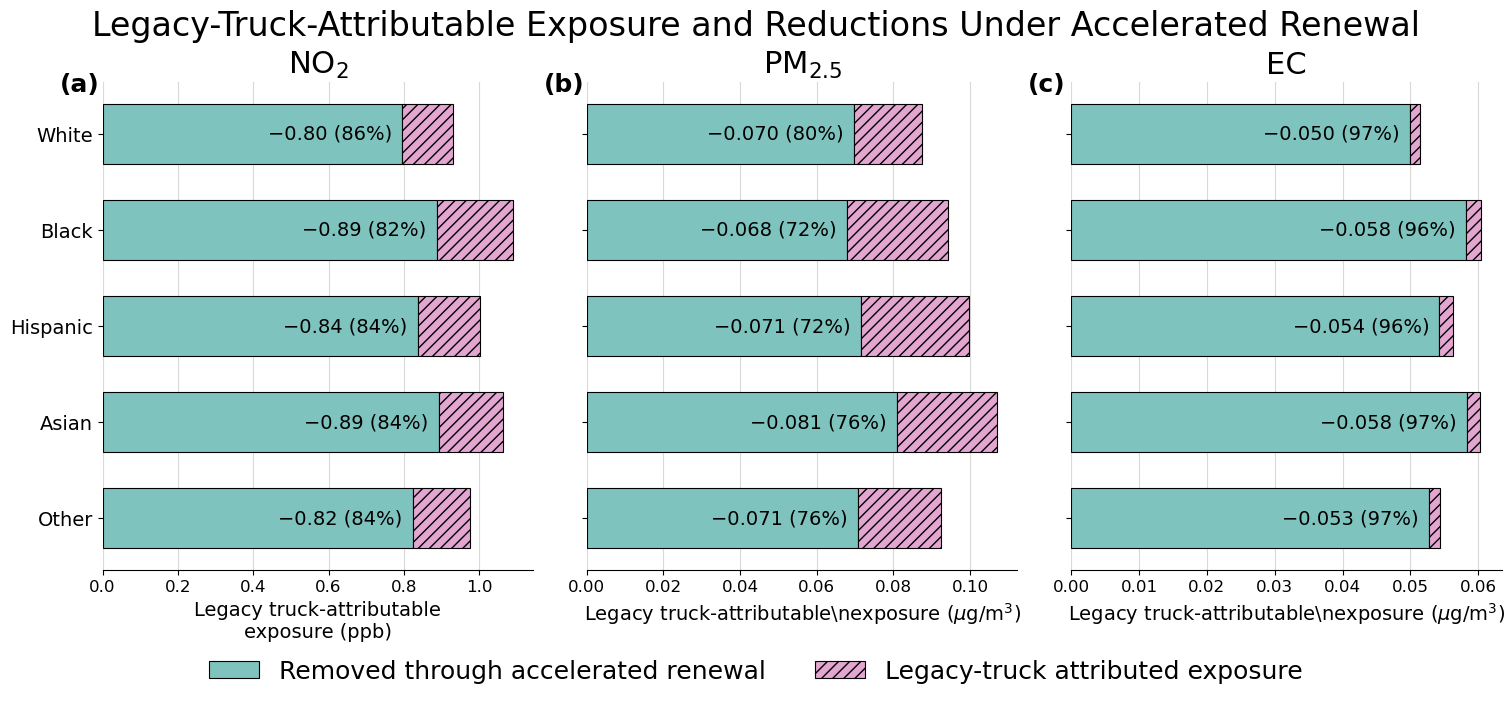

In [39]:
legacy_color = "#C04A9A"       # purple — total legacy-truck burden
removed_color = "#7FC3BE"      # teal — removed through renewal
remaining_color = "#E3A6D0"    # light purple — remaining burden

# ============================================================
# Legacy-attributable exposure and effect of renewal
# ============================================================

fig, axs = plt.subplots(
    1,
    3,
    figsize=(15, 6),
    constrained_layout=True
)

plot_data = [
    (
        no2_legacy,
        r"NO$_2$",
        "Legacy truck-attributable\nexposure (ppb)",
        2
    ),
    (
        pm25_legacy,
        r"PM$_{2.5}$",
        r"Legacy truck-attributable\nexposure ($\mu$g/m$^3$)",
        3
    ),
    (
        ec_legacy,
        "EC",
        r"Legacy truck-attributable\nexposure ($\mu$g/m$^3$)",
        3
    ),
]

y = np.arange(len(groups))

for i, (ax, item) in enumerate(zip(axs, plot_data)):

    df, title, xlabel, decimals = item

    legacy = df["Legacy attributable"].values
    removed = df["Removed by renewal"].values
    remaining = df["Remaining after renewal"].values
    eliminated = df["Fraction eliminated"].values

    # --------------------------------------------------------
    # Exposure removed through accelerated renewal
    # --------------------------------------------------------

    ax.barh(
        y,
        removed,
        height=0.62,
        color=removed_color,
        edgecolor="black",
        linewidth=0.8,
        label="Removed through accelerated renewal"
    )

    # --------------------------------------------------------
    # Legacy-truck-attributable exposure remaining
    # --------------------------------------------------------

    ax.barh(
        y,
        remaining,
        left=removed,
        height=0.62,
        color=remaining_color,
        edgecolor="black",
        linewidth=0.8,
        hatch="///",
        label="Legacy-truck attributed exposure"
    )

    # --------------------------------------------------------
    # Absolute reduction + fraction eliminated
    # --------------------------------------------------------

    for j in range(len(groups)):

        # Number formatting by pollutant
        reduction_text = f"{removed[j]:.{decimals}f}"

        ax.text(
            removed[j] - legacy.max() * 0.025,
            j,
            f"−{reduction_text} ({eliminated[j]:.0f}%)",
            va="center",
            ha="right",
            fontsize=14,
            color="black"
        )

    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=22
    )

    ax.set_xlabel(
        xlabel,
        fontsize=14
    )

    ax.set_yticks(y)

    if i == 0:
        ax.set_yticklabels(
            groups,
            fontsize=14
        )
    else:
        ax.set_yticklabels([])

    ax.invert_yaxis()

    ax.tick_params(
        axis="x",
        labelsize=12
    )

    ax.grid(
        axis="x",
        alpha=0.48,
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    # Panel labels
    ax.text(
        -0.10,
        1.02,
        f"({chr(97+i)})",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=18,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Shared figure title
# ------------------------------------------------------------

fig.suptitle(
    "Legacy-Truck-Attributable Exposure and Reductions Under Accelerated Renewal",
    fontsize=24,
    y=1.06
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

handles, labels = axs[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False,
    fontsize=18
)

plt.show()

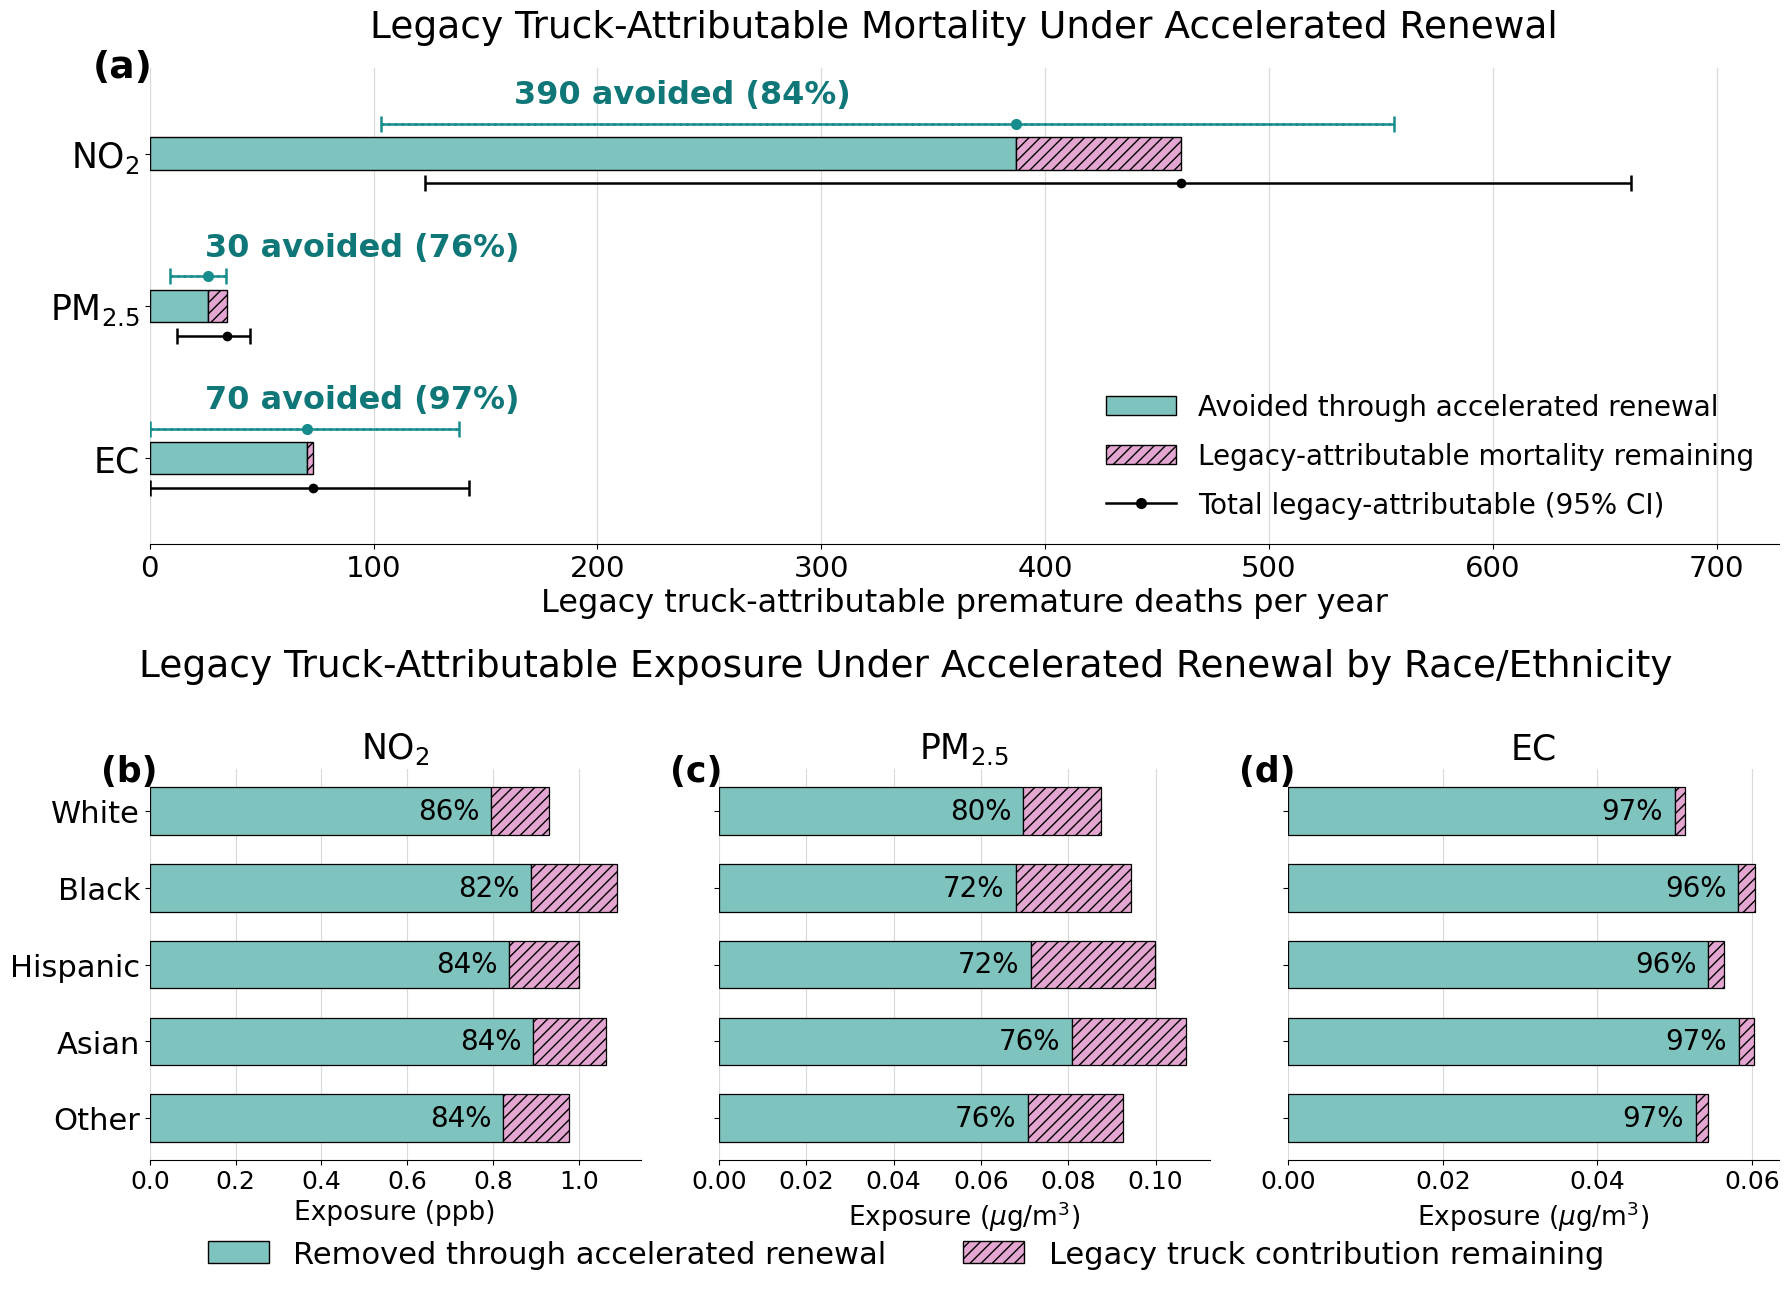

In [67]:
# ============================================================
# COLORS
# ============================================================

renewal_color = "#7FC3BE"
remaining_color = "#E3A6D0"

legacy_ci_color = "black"
renewal_ci_color = "#168C8C"

legacy_text_color = "#B2337A"
renewal_text_color = "#0F7777"

# ============================================================
# HEALTH DATA
# ============================================================

health_order = ["NO2", "PM25_TOT", "PM25_EC"]

health_label_map = {
    "NO2": r"NO$_2$",
    "PM25_TOT": r"PM$_{2.5}$",
    "PM25_EC": "EC",
}

legacy_health = mortality_summary[
    (mortality_summary["Metric"] == "zeropre2010s_minus_base")
    & mortality_summary["Pollutant"].isin(health_order)
].copy()

renewal_health = mortality_summary[
    (mortality_summary["Metric"] == "renewal_minus_base")
    & mortality_summary["Pollutant"].isin(health_order)
].copy()

for df in [legacy_health, renewal_health]:

    df["Pollutant"] = pd.Categorical(
        df["Pollutant"],
        categories=health_order,
        ordered=True
    )

    df.sort_values(
        "Pollutant",
        inplace=True
    )

# ============================================================
# CONVERT TO POSITIVE MORTALITY BURDENS / BENEFITS
#
# Use UNROUNDED values for calculations.
# Only round when displaying labels.
# ============================================================

legacy_health["Legacy attributable"] = (
    -legacy_health["Total"].values
)

legacy_health["Legacy lower"] = np.minimum(
    -legacy_health["Lower"].values,
    -legacy_health["Upper"].values
)

legacy_health["Legacy upper"] = np.maximum(
    -legacy_health["Lower"].values,
    -legacy_health["Upper"].values
)

renewal_health["Avoided through renewal"] = (
    -renewal_health["Total"].values
)

renewal_health["Avoided lower"] = np.minimum(
    -renewal_health["Lower"].values,
    -renewal_health["Upper"].values
)

renewal_health["Avoided upper"] = np.maximum(
    -renewal_health["Lower"].values,
    -renewal_health["Upper"].values
)

# ============================================================
# COMBINE HEALTH DATA
# ============================================================

health_plot = pd.DataFrame({
    "Pollutant": health_order,
    "Legacy attributable": legacy_health["Legacy attributable"].values,
    "Legacy lower": legacy_health["Legacy lower"].values,
    "Legacy upper": legacy_health["Legacy upper"].values,
    "Avoided through renewal": renewal_health["Avoided through renewal"].values,
    "Avoided lower": renewal_health["Avoided lower"].values,
    "Avoided upper": renewal_health["Avoided upper"].values,
})

health_plot["Remaining after renewal"] = (
    health_plot["Legacy attributable"]
    - health_plot["Avoided through renewal"]
)

health_plot["Fraction avoided"] = (
    health_plot["Avoided through renewal"]
    / health_plot["Legacy attributable"]
    * 100
)

health_plot["Label"] = (
    health_plot["Pollutant"]
    .map(health_label_map)
)

# ============================================================
# FIGURE LAYOUT
# ============================================================

fig = plt.figure(
    figsize=(18, 13)
)

gs = fig.add_gridspec(
    2,
    3,
    height_ratios=[1.22, 1.0],
    hspace=0.52,
    wspace=0.16
)

ax_health = fig.add_subplot(
    gs[0, :]
)

axs_exp = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[1, 2]),
]

# ============================================================
# PANEL A — HEALTH IMPACTS
# ============================================================

y_spacing = 1.28

y = (
    np.arange(len(health_plot))
    * y_spacing
)

bar_height = 0.27

# ------------------------------------------------------------
# IMPORTANT:
#
# Avoided = ABOVE bar
# Legacy attributable = BELOW bar
# ------------------------------------------------------------

renewal_ci_offset = -0.25
legacy_ci_offset = 0.25

avoided_text_offset = -0.36
legacy_text_offset = 0.37

annotation_x_shift = 25

# ------------------------------------------------------------
# Stacked mortality bars
# ------------------------------------------------------------

ax_health.barh(
    y,
    health_plot["Avoided through renewal"],
    height=bar_height,
    color=renewal_color,
    edgecolor="black",
    linewidth=1.0,
    label="Avoided through accelerated renewal"
)

ax_health.barh(
    y,
    health_plot["Remaining after renewal"],
    left=health_plot["Avoided through renewal"],
    height=bar_height,
    color=remaining_color,
    edgecolor="black",
    linewidth=1.0,
    hatch="///",
    label="Legacy-attributable mortality remaining"
)

# ============================================================
# PANEL A — CONFIDENCE INTERVALS
# ============================================================

legacy_lower_err = (
    health_plot["Legacy attributable"]
    - health_plot["Legacy lower"]
)

legacy_upper_err = (
    health_plot["Legacy upper"]
    - health_plot["Legacy attributable"]
)

renewal_lower_err = (
    health_plot["Avoided through renewal"]
    - health_plot["Avoided lower"]
)

renewal_upper_err = (
    health_plot["Avoided upper"]
    - health_plot["Avoided through renewal"]
)

# ------------------------------------------------------------
# AVOIDED MORTALITY CI
# Teal dotted CI ABOVE bar
# Paired with "390 avoided", etc.
# ------------------------------------------------------------

ax_health.errorbar(
    health_plot["Avoided through renewal"],
    y + renewal_ci_offset,
    xerr=[
        renewal_lower_err,
        renewal_upper_err
    ],
    fmt="o",
    color=renewal_ci_color,
    ecolor=renewal_ci_color,
    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=7,
    linestyle="none",
    zorder=7
)

for j, row in health_plot.iterrows():

    ax_health.hlines(
        y=y[j] + renewal_ci_offset,
        xmin=row["Avoided lower"],
        xmax=row["Avoided upper"],
        color=renewal_ci_color,
        linewidth=1.8,
        linestyles=":"
    )

# ------------------------------------------------------------
# LEGACY-ATTRIBUTABLE MORTALITY CI
# Black solid CI BELOW bar
# Paired with "460 legacy-attributable", etc.
# ------------------------------------------------------------

ax_health.errorbar(
    health_plot["Legacy attributable"],
    y + legacy_ci_offset,
    xerr=[
        legacy_lower_err,
        legacy_upper_err
    ],
    fmt="o",
    color=legacy_ci_color,
    ecolor=legacy_ci_color,
    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=6,
    linestyle="none",
    zorder=7
)

# ============================================================
# PANEL A — TEXT ANNOTATIONS
# ============================================================

for j, row in health_plot.iterrows():

    avoided = row["Avoided through renewal"]
    total = row["Legacy attributable"]
    pct = row["Fraction avoided"]

    # Round deaths only for display
    avoided_display = round(avoided / 10) * 10
    total_display = round(total / 10) * 10

    # --------------------------------------------------------
    # Avoided mortality annotation
    # ABOVE the bar, paired with teal CI
    # --------------------------------------------------------

    avoided_text_x = max(
        avoided * 0.55 + annotation_x_shift,
        95
    )

    ax_health.text(
        avoided_text_x,
        y[j] + avoided_text_offset,
        f"{avoided_display:.0f} avoided ({pct:.0f}%)",
        ha="center",
        va="bottom",
        fontsize=23,
        fontweight="bold",
        color=renewal_text_color
    )

    # --------------------------------------------------------
    # Legacy-attributable mortality annotation
    # BELOW the bar, paired with black CI
    # --------------------------------------------------------

    legacy_text_x = max(
        total + annotation_x_shift,
        125
    )

#     ax_health.text(
#         legacy_text_x,
#         y[j] + legacy_text_offset,
#         f"{total_display:.0f} legacy-attributable",
#         ha="center",
#         va="top",
#         fontsize=21,
#         fontweight="bold",
#         color=legacy_text_color
#     )

# ============================================================
# PANEL A — AXES
# ============================================================

ax_health.set_yticks(
    y
)

ax_health.set_yticklabels(
    health_plot["Label"],
    fontsize=25
)

ax_health.set_ylim(
    y[-1] + 0.72,
    y[0] - 0.72
)

ax_health.set_xlim(
    0,
    health_plot["Legacy upper"].max() * 1.10
)

ax_health.set_xlabel(
    "Legacy truck-attributable premature deaths per year",
    fontsize=23
)

ax_health.tick_params(
    axis="x",
    labelsize=21
)

ax_health.tick_params(
    axis="y",
    labelsize=25
)

ax_health.grid(
    axis="x",
    alpha=0.46,
    linewidth=0.9
)

ax_health.set_axisbelow(
    True
)

for spine in [
    "top",
    "right",
    "left"
]:

    ax_health.spines[
        spine
    ].set_visible(
        False
    )

# ============================================================
# PANEL A — TITLE / PANEL LABEL
# ============================================================

ax_health.set_title(
    "Legacy Truck-Attributable Mortality Under Accelerated Renewal",
    fontsize=27,
    pad=22
)

ax_health.text(
    -0.035,
    1.04,
    "(a)",
    transform=ax_health.transAxes,
    ha="left",
    va="top",
    fontsize=27,
    fontweight="bold"
)

# ============================================================
# PANEL A — LEGEND
# ============================================================

health_legend = [
    Patch(
        facecolor=renewal_color,
        edgecolor="black",
        label="Avoided through accelerated renewal"
    ),
    Patch(
        facecolor=remaining_color,
        edgecolor="black",
        hatch="///",
        label="Legacy-attributable mortality remaining"
    ),
#     Line2D(
#         [0],
#         [0],
#         color=renewal_ci_color,
#         marker="o",
#         markersize=7,
#         linewidth=1.8,
#         linestyle="-",
#         label="Avoided under renewal (95% CI)"
#     ),
    Line2D(
        [0],
        [0],
        color=legacy_ci_color,
        marker="o",
        markersize=7,
        linewidth=1.8,
        label="Total legacy-attributable (95% CI)"
    ),
]

ax_health.legend(
    handles=health_legend,
    frameon=False,
    fontsize=20,
    loc="lower right",
    handlelength=2.5,
    labelspacing=0.75
)

# ============================================================
# PANELS B–D — LEGACY-ATTRIBUTABLE EXPOSURE
# ============================================================

plot_data = [
    (
        no2_legacy,
        r"NO$_2$",
        "Exposure (ppb)",
        2
    ),
    (
        pm25_legacy,
        r"PM$_{2.5}$",
        r"Exposure ($\mu$g/m$^3$)",
        3
    ),
    (
        ec_legacy,
        "EC",
        r"Exposure ($\mu$g/m$^3$)",
        3
    ),
]

groups = [
    "White",
    "Black",
    "Hispanic",
    "Asian",
    "Other"
]

y_exp = np.arange(
    len(groups)
)

for i, (ax, item) in enumerate(
    zip(
        axs_exp,
        plot_data
    )
):

    df, title, xlabel, decimals = item

    legacy = (
        df["Legacy attributable"]
        .values
    )

    removed = (
        df["Removed by renewal"]
        .values
    )

    remaining = (
        df["Remaining after renewal"]
        .values
    )

    eliminated = (
        df["Fraction eliminated"]
        .values
    )

    # --------------------------------------------------------
    # Removed through accelerated renewal
    # --------------------------------------------------------

    ax.barh(
        y_exp,
        removed,
        height=0.62,
        color=renewal_color,
        edgecolor="black",
        linewidth=0.9,
        label="Reduction under accelerated renewal"
    )

    # --------------------------------------------------------
    # Legacy contribution remaining
    # --------------------------------------------------------

    ax.barh(
        y_exp,
        remaining,
        left=removed,
        height=0.62,
        color=remaining_color,
        edgecolor="black",
        linewidth=0.9,
        hatch="///",
        label="Legacy-truck contribution remaining"
    )

    # --------------------------------------------------------
    # Reduction annotations
    # --------------------------------------------------------

#     for j in range(
#         len(groups)
#     ):

#         reduction_text = (
#             f"{removed[j]:.{decimals}f}"
#         )

#         ax.text(
#             removed[j] - legacy.max() * 0.025,
#             j,
#             f"−{reduction_text} ({eliminated[j]:.0f}%)",
#             va="center",
#             ha="right",
#             fontsize=20,
#             color="black"
#         )
    for j in range(len(groups)):

        ax.text(
            removed[j] - legacy.max() * 0.025,
            j,
            f"{eliminated[j]:.0f}%",
            va="center",
            ha="right",
            fontsize=20,
            color="black"
        )
    # --------------------------------------------------------
    # Panel title
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=25,
        pad=8
    )

    # --------------------------------------------------------
    # X-axis
    # --------------------------------------------------------

    ax.set_xlabel(
        xlabel,
        fontsize=19
    )

    ax.tick_params(
        axis="x",
        labelsize=18
    )

    # --------------------------------------------------------
    # Y-axis
    # --------------------------------------------------------

    ax.set_yticks(
        y_exp
    )

    if i == 0:

        ax.set_yticklabels(
            groups,
            fontsize=22
        )

    else:

        ax.set_yticklabels(
            []
        )

    ax.invert_yaxis()

    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.grid(
        axis="x",
        alpha=0.48,
        linewidth=0.8
    )

    ax.set_axisbelow(
        True
    )

    for spine in [
        "top",
        "right",
        "left"
    ]:

        ax.spines[
            spine
        ].set_visible(
            False
        )

    # --------------------------------------------------------
    # Panel labels
    # --------------------------------------------------------

    ax.text(
        -0.10,
        1.04,
        f"({chr(98 + i)})",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=25,
        fontweight="bold"
    )

# ============================================================
# SHARED EXPOSURE SUBHEADING
# ============================================================

fig.text(
    0.5,
    0.49,
    "Legacy Truck-Attributable Exposure Under Accelerated Renewal by Race/Ethnicity",
    ha="center",
    va="center",
    fontsize=27
)

# ============================================================
# SHARED LEGEND FOR PANELS B–D
# ============================================================

exposure_legend = [
    Patch(
        facecolor=renewal_color,
        edgecolor="black",
        label="Removed through accelerated renewal"
    ),
    Patch(
        facecolor=remaining_color,
        edgecolor="black",
        hatch="///",
        label="Legacy truck contribution remaining"
    ),
]

fig.legend(
    handles=exposure_legend,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),
    ncol=2,
    frameon=False,
    fontsize=22,
    handlelength=2.0,
    columnspacing=2.5
)

# ============================================================
# FINAL LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.08,
    right=0.985,
    top=0.95,
    bottom=0.11
)

plt.savefig(
    "LegacyTruck_Mortality_Exposure_Renewal.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


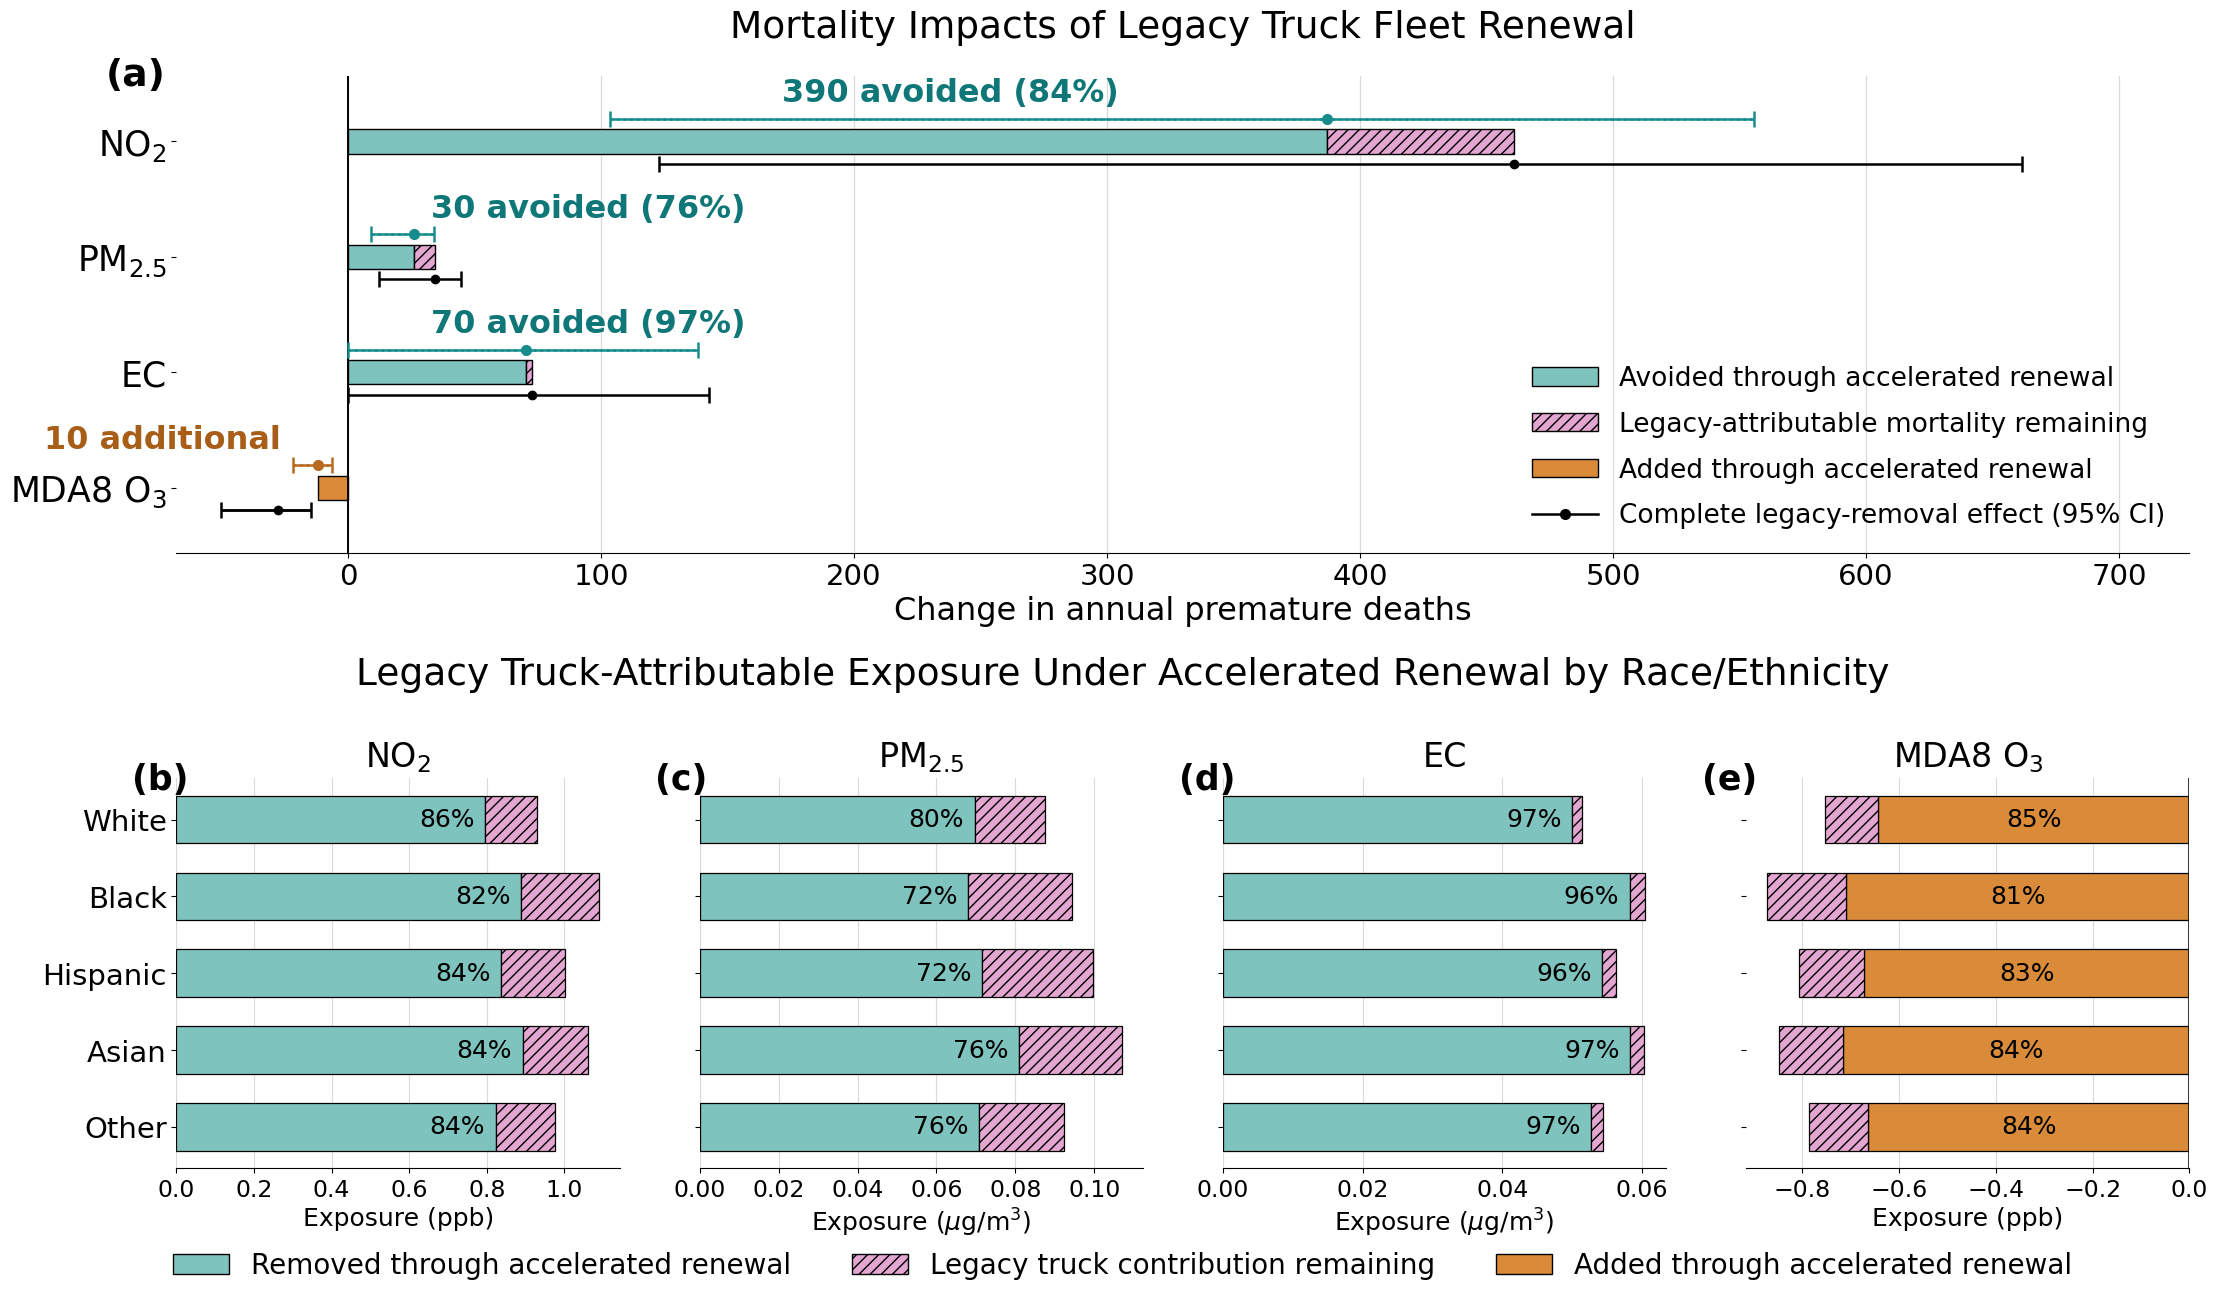

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# ============================================================
# COLORS
# ============================================================

renewal_color = "#7FC3BE"
remaining_color = "#E3A6D0"

legacy_ci_color = "black"
renewal_ci_color = "#168C8C"

legacy_text_color = "#B2337A"
renewal_text_color = "#0F7777"

# O3 trade-off colors
o3_color = "#D98B39"
o3_ci_color = "#B56A1F"
o3_text_color = "#A85E17"


# ============================================================
# MAKE SURE O3 LEGACY EXPOSURE EXISTS
# ============================================================

o3_legacy = get_legacy_exposure(O3_summary)


# ============================================================
# HEALTH DATA
#
# NO2 / PM2.5 / EC:
#   legacy-attributable mortality = positive burden
#   renewal effect = positive avoided mortality
#
# O3:
#   legacy trucks suppress O3
#   accelerated renewal increases O3
#   complete legacy removal increases O3 further
#
# For plotting only:
#
#   avoided mortality     -> RIGHT of zero
#   additional mortality  -> LEFT of zero
#
# ============================================================

benefit_order = [
    "NO2",
    "PM25_TOT",
    "PM25_EC"
]


health_label_map = {
    "NO2": r"NO$_2$",
    "PM25_TOT": r"PM$_{2.5}$",
    "PM25_EC": "EC",
    "O3_Turner2016": r"MDA8 O$_3$"
}


# ============================================================
# NO2 / PM2.5 / EC HEALTH DATA
# ============================================================

legacy_health = mortality_summary[
    (mortality_summary["Metric"] == "zeropre2010s_minus_base")
    & mortality_summary["Pollutant"].isin(benefit_order)
].copy()


renewal_health = mortality_summary[
    (mortality_summary["Metric"] == "renewal_minus_base")
    & mortality_summary["Pollutant"].isin(benefit_order)
].copy()


for df in [
    legacy_health,
    renewal_health
]:

    df["Pollutant"] = pd.Categorical(
        df["Pollutant"],
        categories=benefit_order,
        ordered=True
    )

    df.sort_values(
        "Pollutant",
        inplace=True
    )


# ============================================================
# CONVERT NO2 / PM2.5 / EC TO POSITIVE BURDENS / BENEFITS
#
# Original mortality differences are negative when deaths
# decrease, so multiply by -1 for plotting as positive
# burdens / avoided deaths.
# ============================================================

legacy_health["Legacy attributable"] = (
    -legacy_health["Total"].values
)


legacy_health["Legacy lower"] = np.minimum(
    -legacy_health["Lower"].values,
    -legacy_health["Upper"].values
)


legacy_health["Legacy upper"] = np.maximum(
    -legacy_health["Lower"].values,
    -legacy_health["Upper"].values
)


renewal_health["Avoided through renewal"] = (
    -renewal_health["Total"].values
)


renewal_health["Avoided lower"] = np.minimum(
    -renewal_health["Lower"].values,
    -renewal_health["Upper"].values
)


renewal_health["Avoided upper"] = np.maximum(
    -renewal_health["Lower"].values,
    -renewal_health["Upper"].values
)


# ============================================================
# COMBINE NO2 / PM2.5 / EC HEALTH DATA
# ============================================================

health_plot = pd.DataFrame({

    "Pollutant":
        benefit_order,

    "Legacy attributable":
        legacy_health["Legacy attributable"].values,

    "Legacy lower":
        legacy_health["Legacy lower"].values,

    "Legacy upper":
        legacy_health["Legacy upper"].values,

    "Avoided through renewal":
        renewal_health["Avoided through renewal"].values,

    "Avoided lower":
        renewal_health["Avoided lower"].values,

    "Avoided upper":
        renewal_health["Avoided upper"].values,
})


health_plot["Remaining after renewal"] = (
    health_plot["Legacy attributable"]
    - health_plot["Avoided through renewal"]
)


health_plot["Fraction avoided"] = (
    health_plot["Avoided through renewal"]
    / health_plot["Legacy attributable"]
    * 100
)


health_plot["Label"] = (
    health_plot["Pollutant"]
    .map(health_label_map)
)


# ============================================================
# O3 HEALTH EFFECT — ACCELERATED RENEWAL
#
# Underlying mortality remains POSITIVE because accelerated
# renewal raises O3 and therefore produces additional
# O3-attributable deaths.
#
# Flip sign ONLY for plotting so additional mortality appears
# LEFT of zero.
# ============================================================

o3_health = mortality_summary[
    (mortality_summary["Metric"] == "renewal_minus_base")
    & (mortality_summary["Pollutant"] == "O3_Turner2016")
].copy()


o3_total = (
    o3_health["Total"].iloc[0]
)


o3_lower = min(
    o3_health["Lower"].iloc[0],
    o3_health["Upper"].iloc[0]
)


o3_upper = max(
    o3_health["Lower"].iloc[0],
    o3_health["Upper"].iloc[0]
)


# Negative plotting coordinates only
o3_plot = (
    -o3_total
)


o3_plot_lower = (
    -o3_upper
)


o3_plot_upper = (
    -o3_lower
)


# ============================================================
# O3 HEALTH EFFECT — COMPLETE LEGACY TRUCK REMOVAL
#
# zeropre2010s_minus_base gives the mortality response from
# removing all pre-2010 trucks.
#
# Because complete legacy removal further increases O3,
# the mortality response is additional deaths.
#
# Again, flip sign ONLY for plotting so it appears LEFT of zero.
# ============================================================

o3_legacy_health = mortality_summary[
    (mortality_summary["Metric"] == "zeropre2010s_minus_base")
    & (mortality_summary["Pollutant"] == "O3_Turner2016")
].copy()


o3_legacy_total = (
    o3_legacy_health["Total"].iloc[0]
)


o3_legacy_lower = min(
    o3_legacy_health["Lower"].iloc[0],
    o3_legacy_health["Upper"].iloc[0]
)


o3_legacy_upper = max(
    o3_legacy_health["Lower"].iloc[0],
    o3_legacy_health["Upper"].iloc[0]
)


# Negative plotting coordinates only
o3_legacy_plot = (
    -o3_legacy_total
)


o3_legacy_plot_lower = (
    -o3_legacy_upper
)


o3_legacy_plot_upper = (
    -o3_legacy_lower
)


# ============================================================
# FIGURE LAYOUT
#
# Panel A spans all four columns
# Panels B-E = NO2, PM2.5, EC, MDA8 O3
# ============================================================

fig = plt.figure(
    figsize=(22, 13)
)


gs = fig.add_gridspec(
    2,
    4,
    height_ratios=[1.22, 1.0],
    hspace=0.52,
    wspace=0.18
)


ax_health = fig.add_subplot(
    gs[0, :]
)


axs_exp = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[1, 2]),
    fig.add_subplot(gs[1, 3]),
]


# ============================================================
# PANEL A — HEALTH IMPACTS
# ============================================================

health_labels = [
    r"NO$_2$",
    r"PM$_{2.5}$",
    "EC",
    r"MDA8 O$_3$"
]


y_spacing = 1.28


y = (
    np.arange(4)
    * y_spacing
)


bar_height = 0.27


# CI positions:
#
# renewal effect = above bar
# complete legacy-removal effect = below bar

renewal_ci_offset = -0.25
legacy_ci_offset = 0.25


avoided_text_offset = -0.36


annotation_x_shift = 25


# First three rows = mortality benefits
y_benefit = y[:3]


# Fourth row = O3 trade-off
o3_y = y[3]


# ============================================================
# PANEL A — NO2 / PM2.5 / EC STACKED BARS
# ============================================================

ax_health.barh(
    y_benefit,
    health_plot["Avoided through renewal"],
    height=bar_height,
    color=renewal_color,
    edgecolor="black",
    linewidth=1.0,
    label="Avoided through accelerated renewal"
)


ax_health.barh(
    y_benefit,
    health_plot["Remaining after renewal"],
    left=health_plot["Avoided through renewal"],
    height=bar_height,
    color=remaining_color,
    edgecolor="black",
    linewidth=1.0,
    hatch="///",
    label="Legacy-attributable mortality remaining"
)


# ============================================================
# PANEL A — O3 ADDITIONAL MORTALITY
#
# Negative plotting value places accelerated-renewal O3
# mortality LEFT of zero.
# ============================================================

ax_health.barh(
    o3_y,
    o3_plot,
    height=bar_height,
    color=o3_color,
    edgecolor="black",
    linewidth=1.0,
    label="Added through accelerated renewal"
)


# ============================================================
# PANEL A — ZERO LINE
# ============================================================

ax_health.axvline(
    0,
    color="black",
    linewidth=1.4,
    zorder=3
)


# ============================================================
# PANEL A — CONFIDENCE INTERVALS
# ============================================================


# ------------------------------------------------------------
# NO2 / PM2.5 / EC — legacy-removal CI
# ------------------------------------------------------------

legacy_lower_err = (
    health_plot["Legacy attributable"]
    - health_plot["Legacy lower"]
)


legacy_upper_err = (
    health_plot["Legacy upper"]
    - health_plot["Legacy attributable"]
)


# ------------------------------------------------------------
# NO2 / PM2.5 / EC — accelerated-renewal CI
# ------------------------------------------------------------

renewal_lower_err = (
    health_plot["Avoided through renewal"]
    - health_plot["Avoided lower"]
)


renewal_upper_err = (
    health_plot["Avoided upper"]
    - health_plot["Avoided through renewal"]
)


# ------------------------------------------------------------
# Accelerated-renewal mortality CI
# NO2 / PM2.5 / EC
# ------------------------------------------------------------

ax_health.errorbar(
    health_plot["Avoided through renewal"],
    y_benefit + renewal_ci_offset,

    xerr=[
        renewal_lower_err,
        renewal_upper_err
    ],

    fmt="o",

    color=renewal_ci_color,
    ecolor=renewal_ci_color,

    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=7,

    linestyle="none",
    zorder=7
)


for j, row in health_plot.iterrows():

    ax_health.hlines(
        y=y_benefit[j] + renewal_ci_offset,
        xmin=row["Avoided lower"],
        xmax=row["Avoided upper"],
        color=renewal_ci_color,
        linewidth=1.8,
        linestyles=":"
    )


# ------------------------------------------------------------
# Complete legacy-removal mortality CI
# NO2 / PM2.5 / EC
# ------------------------------------------------------------

ax_health.errorbar(
    health_plot["Legacy attributable"],
    y_benefit + legacy_ci_offset,

    xerr=[
        legacy_lower_err,
        legacy_upper_err
    ],

    fmt="o",

    color=legacy_ci_color,
    ecolor=legacy_ci_color,

    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=6,

    linestyle="none",
    zorder=7
)


# ============================================================
# O3 ACCELERATED-RENEWAL MORTALITY CI
#
# Orange point + dotted whisker above bar.
# ============================================================

o3_lower_err = (
    o3_plot
    - o3_plot_lower
)


o3_upper_err = (
    o3_plot_upper
    - o3_plot
)


ax_health.errorbar(
    o3_plot,
    o3_y + renewal_ci_offset,

    xerr=[
        [o3_lower_err],
        [o3_upper_err]
    ],

    fmt="o",

    color=o3_ci_color,
    ecolor=o3_ci_color,

    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=7,

    linestyle="none",
    zorder=7
)


ax_health.hlines(
    y=o3_y + renewal_ci_offset,
    xmin=o3_plot_lower,
    xmax=o3_plot_upper,
    color=o3_ci_color,
    linewidth=1.8,
    linestyles=":"
)


# ============================================================
# O3 COMPLETE LEGACY-REMOVAL MORTALITY CI
#
# Black point + solid whisker below bar.
#
# This mirrors the black legacy-removal reference point used
# for NO2 / PM2.5 / EC.
# ============================================================

o3_legacy_lower_err = (
    o3_legacy_plot
    - o3_legacy_plot_lower
)


o3_legacy_upper_err = (
    o3_legacy_plot_upper
    - o3_legacy_plot
)


ax_health.errorbar(
    o3_legacy_plot,
    o3_y + legacy_ci_offset,

    xerr=[
        [o3_legacy_lower_err],
        [o3_legacy_upper_err]
    ],

    fmt="o",

    color=legacy_ci_color,
    ecolor=legacy_ci_color,

    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=6,

    linestyle="none",
    zorder=7
)


ax_health.hlines(
    y=o3_y + legacy_ci_offset,
    xmin=o3_legacy_plot_lower,
    xmax=o3_legacy_plot_upper,
    color=legacy_ci_color,
    linewidth=1.8
)


# ============================================================
# PANEL A — TEXT ANNOTATIONS
# ============================================================


# ------------------------------------------------------------
# NO2 / PM2.5 / EC
# ------------------------------------------------------------

for j, row in health_plot.iterrows():

    avoided = (
        row["Avoided through renewal"]
    )

    pct = (
        row["Fraction avoided"]
    )


    # Round deaths only for display
    avoided_display = (
        round(avoided / 10)
        * 10
    )


    avoided_text_x = max(
        avoided * 0.55
        + annotation_x_shift,
        95
    )


    ax_health.text(
        avoided_text_x,
        y_benefit[j] + avoided_text_offset,

        f"{avoided_display:.0f} avoided ({pct:.0f}%)",

        ha="center",
        va="bottom",

        fontsize=23,
        fontweight="bold",

        color=renewal_text_color
    )


# ------------------------------------------------------------
# O3 accelerated-renewal annotation
#
# No annotation for the black legacy-removal point because
# the legend identifies that estimate.
# ------------------------------------------------------------

o3_display = (
    round(o3_total / 10)
    * 10
)


ax_health.text(
    o3_plot_lower - 5,
    o3_y + avoided_text_offset,

    f"{o3_display:.0f} additional",

    ha="right",
    va="bottom",

    fontsize=23,
    fontweight="bold",

    color=o3_text_color
)


# ============================================================
# PANEL A — AXES
# ============================================================

ax_health.set_yticks(
    y
)


ax_health.set_yticklabels(
    health_labels,
    fontsize=25
)


ax_health.set_ylim(
    y[-1] + 0.72,
    y[0] - 0.72
)


# ------------------------------------------------------------
# Asymmetric x-axis
#
# Negative side accounts for BOTH:
#   accelerated renewal O3 mortality
#   complete legacy-removal O3 mortality
#
# Positive side accounts for the large NO2 mortality burden.
# ------------------------------------------------------------

health_xmax = (
    health_plot["Legacy upper"].max()
    * 1.10
)


health_xmin = min(
    -50,
    o3_plot_lower * 1.35,
    o3_legacy_plot_lower * 1.35
)


ax_health.set_xlim(
    health_xmin,
    health_xmax
)


ax_health.set_xlabel(
    "Change in annual premature deaths",
    fontsize=23
)


ax_health.tick_params(
    axis="x",
    labelsize=21
)


ax_health.tick_params(
    axis="y",
    labelsize=25
)


ax_health.grid(
    axis="x",
    alpha=0.46,
    linewidth=0.9
)


ax_health.set_axisbelow(
    True
)


for spine in [
    "top",
    "right",
    "left"
]:

    ax_health.spines[
        spine
    ].set_visible(
        False
    )


# ============================================================
# PANEL A — DIRECTIONAL LABELS
# ============================================================



# ax_health.text(
#     0.99,
#     1.01,

#     "\u2192 Avoided deaths",

#     transform=ax_health.transAxes,

#     ha="right",
#     va="bottom",

#     fontsize=18,
#     fontweight="bold",

#     color=renewal_text_color
# )


# ============================================================
# PANEL A — TITLE / PANEL LABEL
# ============================================================

ax_health.set_title(
    "Mortality Impacts of Legacy Truck Fleet Renewal",
    fontsize=27,
    pad=28
)


ax_health.text(
    -0.035,
    1.04,

    "(a)",

    transform=ax_health.transAxes,

    ha="left",
    va="top",

    fontsize=27,
    fontweight="bold"
)


# ============================================================
# PANEL A — LEGEND
# ============================================================

health_legend = [

    Patch(
        facecolor=renewal_color,
        edgecolor="black",
        label="Avoided through accelerated renewal"
    ),

    Patch(
        facecolor=remaining_color,
        edgecolor="black",
        hatch="///",
        label="Legacy-attributable mortality remaining"
    ),

    Patch(
        facecolor=o3_color,
        edgecolor="black",
        label="Added through accelerated renewal"
    ),

    Line2D(
        [0],
        [0],

        color=legacy_ci_color,
        marker="o",

        markersize=7,
        linewidth=1.8,

        label="Complete legacy-removal effect (95% CI)"
    ),
]


ax_health.legend(
    handles=health_legend,

    frameon=False,

    fontsize=19,

    loc="lower right",

    handlelength=2.5,
    labelspacing=0.75
)


# ============================================================
# PANELS B–E — LEGACY-ATTRIBUTABLE EXPOSURE
# ============================================================

plot_data = [

    (
        no2_legacy,
        r"NO$_2$",
        "Exposure (ppb)",
        2,
        False
    ),

    (
        pm25_legacy,
        r"PM$_{2.5}$",
        r"Exposure ($\mu$g/m$^3$)",
        3,
        False
    ),

    (
        ec_legacy,
        "EC",
        r"Exposure ($\mu$g/m$^3$)",
        3,
        False
    ),

    (
        o3_legacy,
        r"MDA8 O$_3$",
        "Exposure (ppb)",
        2,
        True
    ),
]


groups = [
    "White",
    "Black",
    "Hispanic",
    "Asian",
    "Other"
]


y_exp = np.arange(
    len(groups)
)


# ============================================================
# DRAW EXPOSURE PANELS
# ============================================================

for i, (ax, item) in enumerate(
    zip(
        axs_exp,
        plot_data
    )
):

    df, title, xlabel, decimals, is_o3 = item


    legacy = (
        df["Legacy attributable"]
        .values
    )


    removed = (
        df["Removed by renewal"]
        .values
    )


    remaining = (
        df["Remaining after renewal"]
        .values
    )


    eliminated = (
        df["Fraction eliminated"]
        .values
    )


    # ========================================================
    # NO2 / PM2.5 / EC
    # ========================================================

    if not is_o3:

        # ----------------------------------------------------
        # Removed through accelerated renewal
        # ----------------------------------------------------

        ax.barh(
            y_exp,
            removed,

            height=0.62,

            color=renewal_color,

            edgecolor="black",
            linewidth=0.9,

            label="Avoided through accelerated renewal"
        )


        # ----------------------------------------------------
        # Legacy contribution remaining
        # ----------------------------------------------------

        ax.barh(
            y_exp,
            remaining,

            left=removed,

            height=0.62,

            color=remaining_color,

            edgecolor="black",
            linewidth=0.9,

            hatch="///",

            label="Legacy truck contribution remaining"
        )


        # ----------------------------------------------------
        # Percent removed
        # ----------------------------------------------------

        for j in range(
            len(groups)
        ):

            ax.text(
                removed[j]
                - legacy.max() * 0.025,

                j,

                f"{eliminated[j]:.0f}%",

                va="center",
                ha="right",

                fontsize=18,
                color="black"
            )


    # ========================================================
    # O3
    #
    # Negative values indicate legacy-truck O3 suppression.
    #
    # Accelerated renewal reverses much of that suppression,
    # increasing O3 exposure.
    # ========================================================

    else:

        # ----------------------------------------------------
        # O3 added through accelerated renewal
        # ----------------------------------------------------

        ax.barh(
            y_exp,
            removed,

            height=0.62,

            color=o3_color,

            edgecolor="black",
            linewidth=0.9,

            label="Added through accelerated renewal"
        )


        # ----------------------------------------------------
        # Legacy-associated O3 effect remaining
        # ----------------------------------------------------

        ax.barh(
            y_exp,
            remaining,

            left=removed,

            height=0.62,

            color=remaining_color,

            edgecolor="black",
            linewidth=0.9,

            hatch="///",

            label="Legacy truck contribution remaining"
        )


        # ----------------------------------------------------
        # Zero line
        # ----------------------------------------------------

        ax.axvline(
            0,
            color="black",
            linewidth=1.1
        )


        # ----------------------------------------------------
        # Fraction of legacy O3 suppression reversed by renewal
        # ----------------------------------------------------

        for j in range(
            len(groups)
        ):

            ax.text(
                removed[j] * 0.50,

                j,

                f"{eliminated[j]:.0f}%",

                va="center",
                ha="center",

                fontsize=18,
                color="black"
            )


    # ========================================================
    # PANEL TITLE
    # ========================================================

    ax.set_title(
        title,
        fontsize=24,
        pad=8
    )


    # ========================================================
    # X AXIS
    # ========================================================

    ax.set_xlabel(
        xlabel,
        fontsize=18
    )


    ax.tick_params(
        axis="x",
        labelsize=17
    )


    # ========================================================
    # Y AXIS
    # ========================================================

    ax.set_yticks(
        y_exp
    )


    if i == 0:

        ax.set_yticklabels(
            groups,
            fontsize=21
        )

    else:

        ax.set_yticklabels(
            []
        )


    ax.invert_yaxis()


    # ========================================================
    # FORMATTING
    # ========================================================

    ax.grid(
        axis="x",
        alpha=0.48,
        linewidth=0.8
    )


    ax.set_axisbelow(
        True
    )


    for spine in [
        "top",
        "right",
        "left"
    ]:

        ax.spines[
            spine
        ].set_visible(
            False
        )


    # ========================================================
    # PANEL LABELS
    # ========================================================

    ax.text(
        -0.10,
        1.04,

        f"({chr(98 + i)})",

        transform=ax.transAxes,

        ha="left",
        va="top",

        fontsize=25,
        fontweight="bold"
    )


# ============================================================
# SHARED EXPOSURE SUBHEADING
# ============================================================

fig.text(
    0.5,
    0.49,

    "Legacy Truck-Attributable Exposure Under Accelerated Renewal by Race/Ethnicity",

    ha="center",
    va="center",

    fontsize=27
)


# ============================================================
# SHARED LEGEND FOR PANELS B–E
# ============================================================

exposure_legend = [

    Patch(
        facecolor=renewal_color,
        edgecolor="black",
        label="Removed through accelerated renewal"
    ),

    Patch(
        facecolor=remaining_color,
        edgecolor="black",
        hatch="///",
        label="Legacy truck contribution remaining"
    ),

    Patch(
        facecolor=o3_color,
        edgecolor="black",
        label="Added through accelerated renewal"
    ),
]


fig.legend(
    handles=exposure_legend,

    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),

    ncol=3,

    frameon=False,

    fontsize=20,

    handlelength=2.0,
    columnspacing=2.2
)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.07,
    right=0.985,
    top=0.95,
    bottom=0.11
)
c

plt.savefig(
    "LegacyTruck_Mortality_Exposure_Renewal_withO3_diverging.png",
    dpi=600,
    bbox_inches="tight"
)


plt.show()

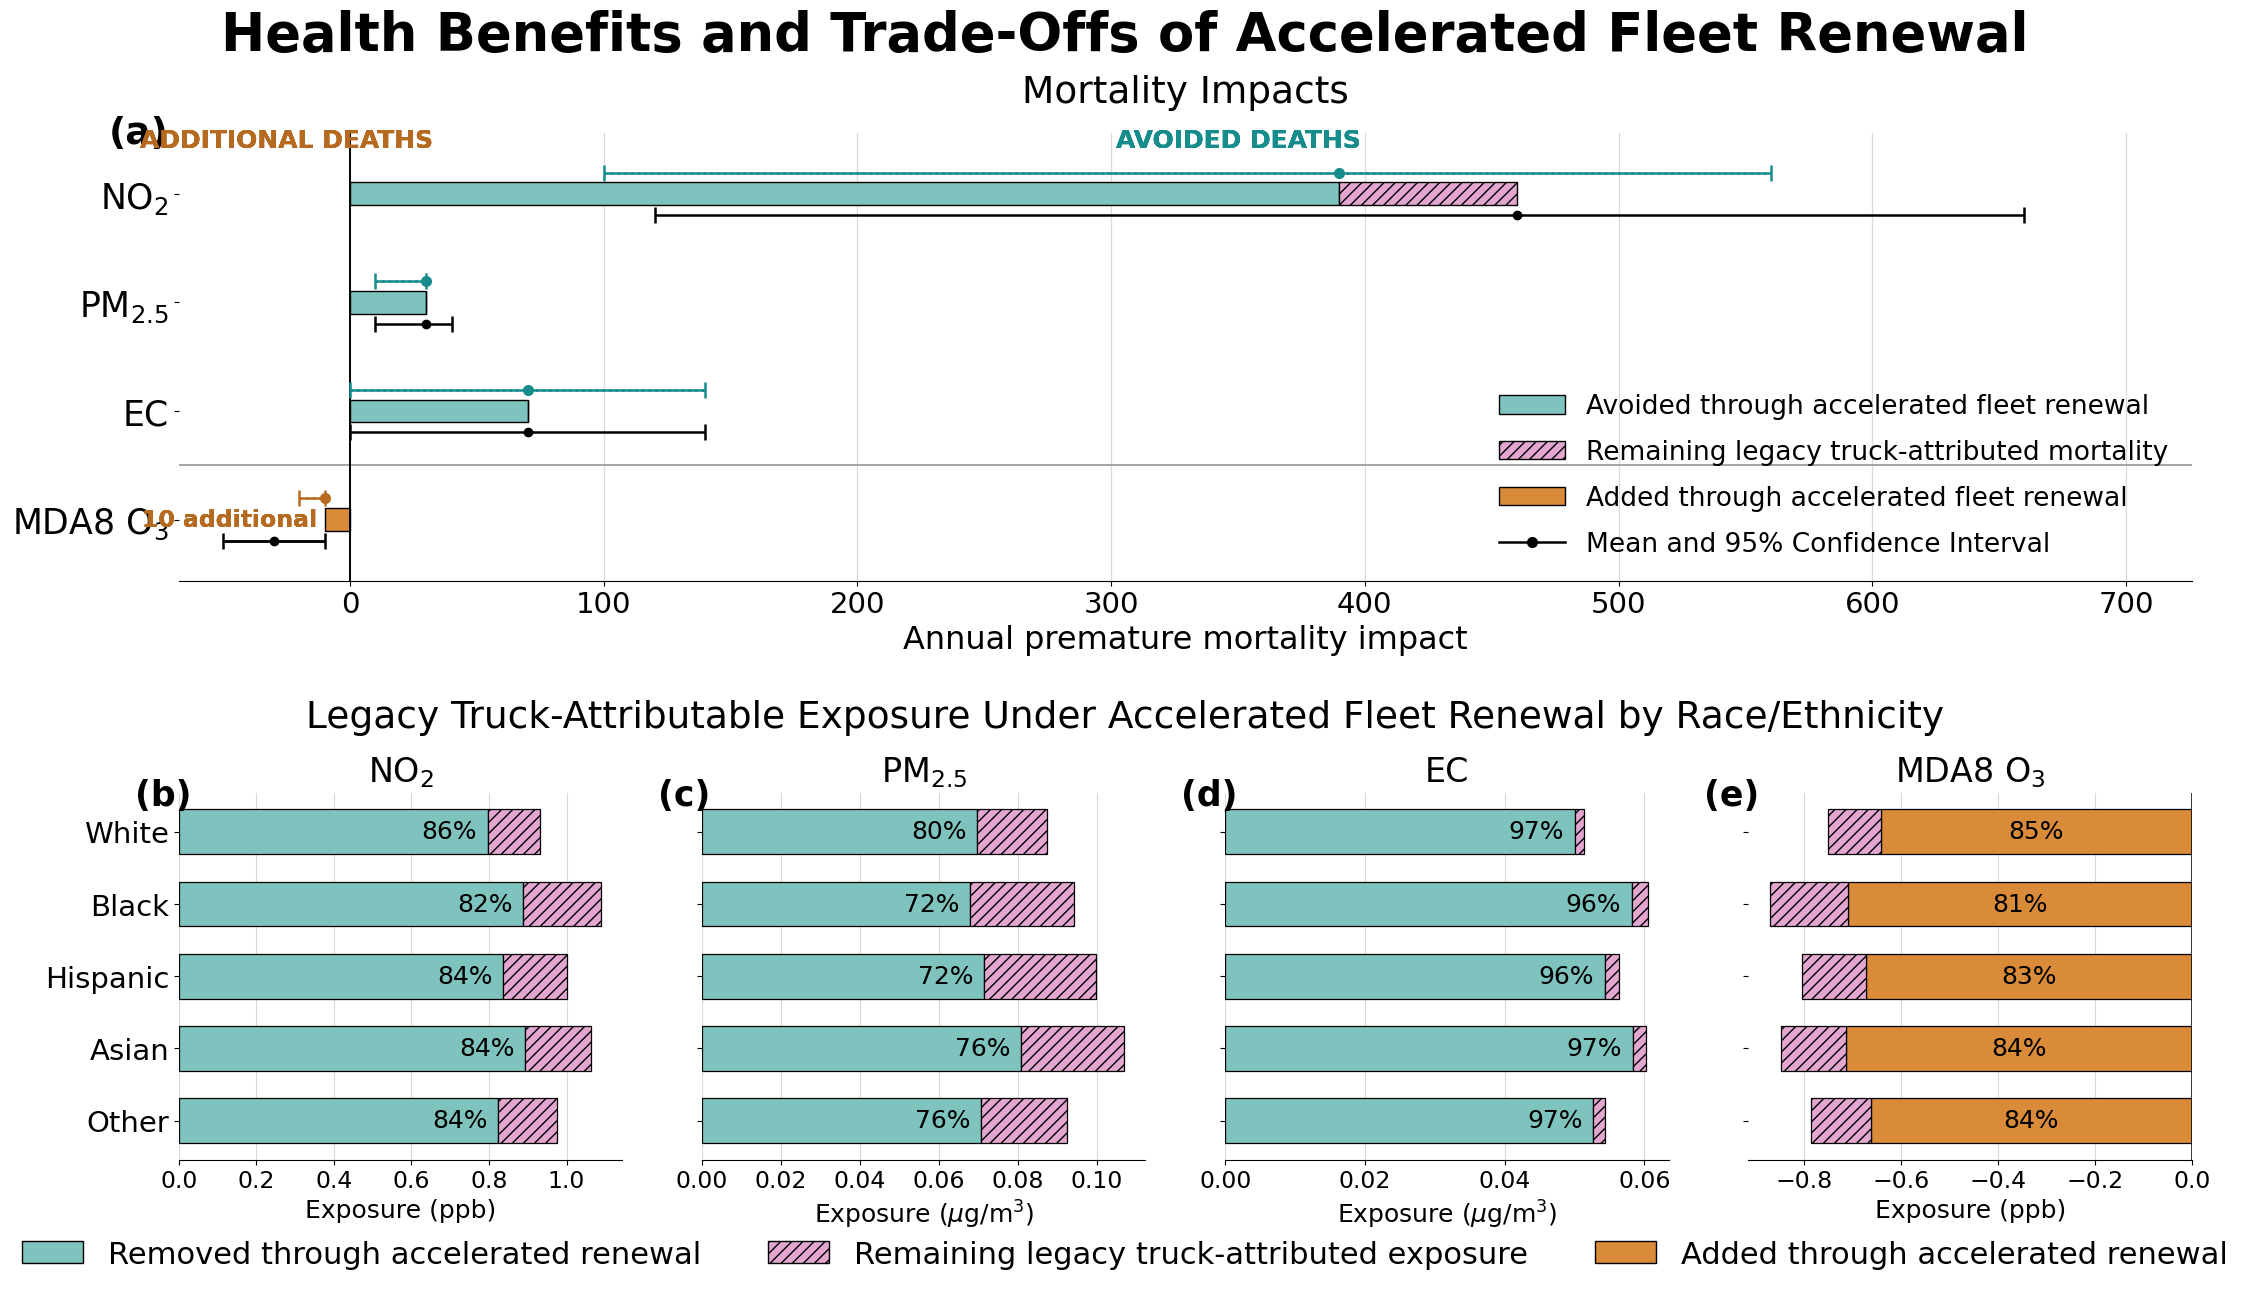

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# ============================================================
# COLORS
# ============================================================

renewal_color = "#7FC3BE"
remaining_color = "#E3A6D0"
legacy_ci_color = "black"
renewal_ci_color = "#168C8C"
o3_color = "#D98B39"
o3_ci_color = "#B56A1F"


# ============================================================
# HEALTH DATA
# ============================================================

benefit_order = ["NO2", "PM25_TOT", "PM25_EC"]

legacy_health = mortality_summary[(mortality_summary["Metric"] == "zeropre2010s_minus_base") & mortality_summary["Pollutant"].isin(benefit_order)].copy()
renewal_health = mortality_summary[(mortality_summary["Metric"] == "renewal_minus_base") & mortality_summary["Pollutant"].isin(benefit_order)].copy()

# Keep everything in the same pollutant order
for df in [legacy_health, renewal_health]:
    df["Pollutant"] = pd.Categorical(df["Pollutant"], categories=benefit_order, ordered=True)
    df.sort_values("Pollutant", inplace=True)

# Mortality differences are negative when deaths decrease, so flip them here
legacy_health["Legacy attributable"] = -legacy_health["Total"].values
legacy_health["Legacy lower"] = np.minimum(-legacy_health["Lower"].values, -legacy_health["Upper"].values)
legacy_health["Legacy upper"] = np.maximum(-legacy_health["Lower"].values, -legacy_health["Upper"].values)

renewal_health["Avoided through renewal"] = -renewal_health["Total"].values
renewal_health["Avoided lower"] = np.minimum(-renewal_health["Lower"].values, -renewal_health["Upper"].values)
renewal_health["Avoided upper"] = np.maximum(-renewal_health["Lower"].values, -renewal_health["Upper"].values)

health_plot = pd.DataFrame({
    "Pollutant": benefit_order,
    "Legacy attributable": legacy_health["Legacy attributable"].values,
    "Legacy lower": legacy_health["Legacy lower"].values,
    "Legacy upper": legacy_health["Legacy upper"].values,
    "Avoided through renewal": renewal_health["Avoided through renewal"].values,
    "Avoided lower": renewal_health["Avoided lower"].values,
    "Avoided upper": renewal_health["Avoided upper"].values
})

# Round mortality estimates and CIs to the nearest 10 before plotting
mortality_cols = ["Legacy attributable", "Legacy lower", "Legacy upper", "Avoided through renewal", "Avoided lower", "Avoided upper"]
health_plot[mortality_cols] = health_plot[mortality_cols].apply(lambda x: np.round(x / 10) * 10)

health_plot["Remaining after renewal"] = health_plot["Legacy attributable"] - health_plot["Avoided through renewal"]


# ============================================================
# O3 HEALTH EFFECTS
# ============================================================

# Renewal increases O3, so these are additional deaths
o3_health = mortality_summary[(mortality_summary["Metric"] == "renewal_minus_base") & (mortality_summary["Pollutant"] == "O3_Turner2016")].copy()

o3_total = round(o3_health["Total"].iloc[0] / 10) * 10
o3_lower = round(min(o3_health["Lower"].iloc[0], o3_health["Upper"].iloc[0]) / 10) * 10
o3_upper = round(max(o3_health["Lower"].iloc[0], o3_health["Upper"].iloc[0]) / 10) * 10

# Put additional mortality to the left of zero
o3_plot = -o3_total
o3_plot_lower = -o3_upper
o3_plot_upper = -o3_lower

# Complete legacy removal
o3_legacy_health = mortality_summary[(mortality_summary["Metric"] == "zeropre2010s_minus_base") & (mortality_summary["Pollutant"] == "O3_Turner2016")].copy()

o3_legacy_total = round(o3_legacy_health["Total"].iloc[0] / 10) * 10
o3_legacy_lower = round(min(o3_legacy_health["Lower"].iloc[0], o3_legacy_health["Upper"].iloc[0]) / 10) * 10
o3_legacy_upper = round(max(o3_legacy_health["Lower"].iloc[0], o3_legacy_health["Upper"].iloc[0]) / 10) * 10

o3_legacy_plot = -o3_legacy_total
o3_legacy_plot_lower = -o3_legacy_upper
o3_legacy_plot_upper = -o3_legacy_lower


# ============================================================
# EXPOSURE DATA
# ============================================================

o3_legacy = get_legacy_exposure(O3_summary)

plot_data = [
    (no2_legacy, r"NO$_2$", "Exposure (ppb)", False),
    (pm25_legacy, r"PM$_{2.5}$", r"Exposure ($\mu$g/m$^3$)", False),
    (ec_legacy, "EC", r"Exposure ($\mu$g/m$^3$)", False),
    (o3_legacy, r"MDA8 O$_3$", "Exposure (ppb)", True)
]

groups = ["White", "Black", "Hispanic", "Asian", "Other"]


# ============================================================
# FIGURE
# ============================================================

fig = plt.figure(figsize=(22, 13))
fig.suptitle("Health Benefits and Trade-Offs of Accelerated Fleet Renewal", fontsize=38, fontweight="bold", y=0.995)

gs = fig.add_gridspec(2, 4, height_ratios=[1.22, 1.0], hspace=0.52, wspace=0.18)
ax_health = fig.add_subplot(gs[0, :])
axs_exp = [fig.add_subplot(gs[1, i]) for i in range(4)]


# ============================================================
# A) MORTALITY
# ============================================================

health_labels = [r"NO$_2$", r"PM$_{2.5}$", "EC", r"MDA8 O$_3$"]

y = np.arange(4) * 1.28
y_benefit = y[:3]
o3_y = y[3]

bar_height = 0.27
renewal_ci_offset = -0.25
legacy_ci_offset = 0.25

# Avoided through renewal
ax_health.barh(y_benefit, health_plot["Avoided through renewal"], height=bar_height, color=renewal_color, edgecolor="black", linewidth=1.0)

# Total legacy truck-attributed mortality remaining beyond the renewal benefit
ax_health.barh(y_benefit, health_plot["Remaining after renewal"], left=health_plot["Avoided through renewal"], height=bar_height, color=remaining_color, edgecolor="black", linewidth=1.0, hatch="///")

# O3 mortality trade-off
ax_health.barh(o3_y, o3_plot, height=bar_height, color=o3_color, edgecolor="black", linewidth=1.0)

ax_health.axvline(0, color="black", linewidth=1.4, zorder=3)


# ============================================================
# CONFIDENCE INTERVALS
# ============================================================

legacy_lower_err = health_plot["Legacy attributable"] - health_plot["Legacy lower"]
legacy_upper_err = health_plot["Legacy upper"] - health_plot["Legacy attributable"]

renewal_lower_err = health_plot["Avoided through renewal"] - health_plot["Avoided lower"]
renewal_upper_err = health_plot["Avoided upper"] - health_plot["Avoided through renewal"]

# Accelerated renewal
ax_health.errorbar(health_plot["Avoided through renewal"], y_benefit + renewal_ci_offset, xerr=[renewal_lower_err, renewal_upper_err], fmt="o", color=renewal_ci_color, ecolor=renewal_ci_color, elinewidth=1.8, capsize=6, capthick=1.8, markersize=7, linestyle="none", zorder=7)

for j, row in health_plot.iterrows():
    ax_health.hlines(y_benefit[j] + renewal_ci_offset, row["Avoided lower"], row["Avoided upper"], color=renewal_ci_color, linewidth=1.8, linestyles=":")

# Complete legacy removal
ax_health.errorbar(health_plot["Legacy attributable"], y_benefit + legacy_ci_offset, xerr=[legacy_lower_err, legacy_upper_err], fmt="o", color=legacy_ci_color, ecolor=legacy_ci_color, elinewidth=1.8, capsize=6, capthick=1.8, markersize=6, linestyle="none", zorder=7)

# O3 accelerated renewal
o3_lower_err = o3_plot - o3_plot_lower
o3_upper_err = o3_plot_upper - o3_plot

ax_health.errorbar(o3_plot, o3_y + renewal_ci_offset, xerr=[[o3_lower_err], [o3_upper_err]], fmt="o", color=o3_ci_color, ecolor=o3_ci_color, elinewidth=1.8, capsize=6, capthick=1.8, markersize=7, linestyle="none", zorder=7)
ax_health.hlines(o3_y + renewal_ci_offset, o3_plot_lower, o3_plot_upper, color=o3_ci_color, linewidth=1.8, linestyles=":")

# O3 complete legacy removal
o3_legacy_lower_err = o3_legacy_plot - o3_legacy_plot_lower
o3_legacy_upper_err = o3_legacy_plot_upper - o3_legacy_plot

ax_health.errorbar(o3_legacy_plot, o3_y + legacy_ci_offset, xerr=[[o3_legacy_lower_err], [o3_legacy_upper_err]], fmt="o", color=legacy_ci_color, ecolor=legacy_ci_color, elinewidth=1.8, capsize=6, capthick=1.8, markersize=6, linestyle="none", zorder=7)
ax_health.hlines(o3_y + legacy_ci_offset, o3_legacy_plot_lower, o3_legacy_plot_upper, color=legacy_ci_color, linewidth=1.8)


# ============================================================
# MORTALITY FORMATTING
# ============================================================

health_xmax = health_plot["Legacy upper"].max() * 1.10
health_xmin = min(-50, o3_plot_lower * 1.35, o3_legacy_plot_lower * 1.35)

ax_health.set_yticks(y)
ax_health.set_yticklabels(health_labels, fontsize=25)
ax_health.set_ylim(y[-1] + 0.72, y[0] - 0.72)
ax_health.set_xlim(health_xmin, health_xmax)
ax_health.set_xlabel("Change in annual premature deaths", fontsize=23)
ax_health.tick_params(axis="x", labelsize=21)
ax_health.grid(axis="x", alpha=0.46, linewidth=0.9)
ax_health.set_axisbelow(True)
ax_health.set_title("Mortality Impacts", fontsize=27, pad=22)

for spine in ["top", "right", "left"]:
    ax_health.spines[spine].set_visible(False)

ax_health.text(-0.035, 1.04, "(a)", transform=ax_health.transAxes, ha="left", va="top", fontsize=27, fontweight="bold")


# ============================================================
# MORTALITY LEGEND
# ============================================================

health_legend = [
    Patch(facecolor=renewal_color, edgecolor="black", label="Avoided through accelerated fleet renewal"),
    Patch(facecolor=remaining_color, edgecolor="black", hatch="///", label="Remaining legacy truck-attributed mortality"),
    Patch(facecolor=o3_color, edgecolor="black", label="Added through accelerated fleet renewal"),
    Line2D([0], [0], color=legacy_ci_color, marker="o", markersize=7, linewidth=1.8, label="Mean and 95% Confidence Interval")
]

ax_health.legend(handles=health_legend, frameon=False, fontsize=19, loc="lower right", handlelength=2.5, labelspacing=0.75)


# ============================================================
# B-E) EXPOSURE BY RACE / ETHNICITY
# ============================================================

y_exp = np.arange(len(groups))

for i, (ax, item) in enumerate(zip(axs_exp, plot_data)):

    df, title, xlabel, is_o3 = item

    legacy = df["Legacy attributable"].values
    removed = df["Removed by renewal"].values
    remaining = df["Remaining after renewal"].values
    eliminated = df["Fraction eliminated"].values

    if not is_o3:

        ax.barh(y_exp, removed, height=0.62, color=renewal_color, edgecolor="black", linewidth=0.9)
        ax.barh(y_exp, remaining, left=removed, height=0.62, color=remaining_color, edgecolor="black", linewidth=0.9, hatch="///")

        # Percent of the legacy contribution removed through renewal
        for j in range(len(groups)):
            ax.text(removed[j] - legacy.max() * 0.025, j, f"{eliminated[j]:.0f}%", va="center", ha="right", fontsize=18, color="black")

    else:

        # Renewal reverses legacy O3 suppression, so O3 increases
        ax.barh(y_exp, removed, height=0.62, color=o3_color, edgecolor="black", linewidth=0.9)
        ax.barh(y_exp, remaining, left=removed, height=0.62, color=remaining_color, edgecolor="black", linewidth=0.9, hatch="///")
        ax.axvline(0, color="black", linewidth=1.1)

        for j in range(len(groups)):
            ax.text(removed[j] * 0.50, j, f"{eliminated[j]:.0f}%", va="center", ha="center", fontsize=18, color="black")

    ax.set_title(title, fontsize=24, pad=8)
    ax.set_xlabel(xlabel, fontsize=18)
    ax.tick_params(axis="x", labelsize=17)
    ax.set_yticks(y_exp)
    ax.set_yticklabels(groups if i == 0 else [], fontsize=21)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.48, linewidth=0.8)
    ax.set_axisbelow(True)
    from matplotlib.ticker import FuncFormatter

    ax_health.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{abs(x):.0f}"))
    ax_health.set_xlabel("Annual premature mortality impact", fontsize=23)

    ax_health.text(-25, y[0] - 0.55, "ADDITIONAL DEATHS", color=o3_ci_color, fontsize=18, fontweight="bold", ha="center")
    ax_health.text(350, y[0] - 0.55, "AVOIDED DEATHS", color=renewal_ci_color, fontsize=18, fontweight="bold", ha="center")

    ax_health.axhline((y[2] + y[3]) / 2, color="0.65", linewidth=1.2)
    ax_health.text(o3_plot - 3, o3_y, f"{abs(o3_plot):.0f} additional", ha="right", va="center", fontsize=17, color=o3_ci_color, fontweight="bold")
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.text(-0.10, 1.04, f"({chr(98 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=25, fontweight="bold")


# ============================================================
# EXPOSURE HEADING + LEGEND
# ============================================================

fig.text(0.5, 0.45, "Legacy Truck-Attributable Exposure Under Accelerated Fleet Renewal by Race/Ethnicity", ha="center", va="center", fontsize=27)

exposure_legend = [
    Patch(facecolor=renewal_color, edgecolor="black", label="Removed through accelerated renewal"),
    Patch(facecolor=remaining_color, edgecolor="black", hatch="///", label="Remaining legacy truck-attributed exposure"),
    Patch(facecolor=o3_color, edgecolor="black", label="Added through accelerated renewal")
]

fig.legend(handles=exposure_legend, loc="lower center", bbox_to_anchor=(0.5, 0.005), ncol=3, frameon=False, fontsize=22, handlelength=2.0, columnspacing=2.2)


# ============================================================
# SAVE
# ============================================================

plt.subplots_adjust(left=0.07, right=0.985, top=0.90, bottom=0.11)
plt.savefig("AcceleratedFleetRenewal_HealthBenefits_Tradeoffs.png", dpi=600, bbox_inches="tight")
plt.show()

In [260]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# ============================================================
# COLORS
# ============================================================

renewal_color = "#7FC3BE"
remaining_color = "#E3A6D0"

legacy_ci_color = "black"
renewal_ci_color = "#168C8C"

legacy_text_color = "#B2337A"
renewal_text_color = "#0F7777"

# O3 trade-off colors
o3_color = "#D98B39"
o3_ci_color = "#B56A1F"
o3_text_color = "#A85E17"


# ============================================================
# MAKE SURE O3 LEGACY EXPOSURE EXISTS
# ============================================================

o3_legacy = get_legacy_exposure(O3_summary)


# ============================================================
# HEALTH DATA
#
# NO2 / PM2.5 / EC:
#   legacy-attributable mortality = positive burden
#   renewal effect = positive avoided mortality
#
# O3:
#   legacy trucks suppress O3
#   accelerated renewal increases O3
#   complete legacy removal increases O3 further
#
# For plotting only:
#
#   avoided mortality     -> RIGHT of zero
#   additional mortality  -> LEFT of zero
#
# ============================================================

benefit_order = [
    "NO2",
    "PM25_TOT",
    "PM25_EC"
]


health_label_map = {
    "NO2": r"NO$_2$",
    "PM25_TOT": r"PM$_{2.5}$",
    "PM25_EC": "EC",
    "O3_Turner2016": r"MDA8 O$_3$"
}


# ============================================================
# NO2 / PM2.5 / EC HEALTH DATA
# ============================================================

legacy_health = mortality_summary[
    (mortality_summary["Metric"] == "zeropre2010s_minus_base")
    & mortality_summary["Pollutant"].isin(benefit_order)
].copy()


renewal_health = mortality_summary[
    (mortality_summary["Metric"] == "renewal_minus_base")
    & mortality_summary["Pollutant"].isin(benefit_order)
].copy()


for df in [
    legacy_health,
    renewal_health
]:

    df["Pollutant"] = pd.Categorical(
        df["Pollutant"],
        categories=benefit_order,
        ordered=True
    )

    df.sort_values(
        "Pollutant",
        inplace=True
    )


# ============================================================
# CONVERT NO2 / PM2.5 / EC TO POSITIVE BURDENS / BENEFITS
#
# Original mortality differences are negative when deaths
# decrease, so multiply by -1 for plotting as positive
# burdens / avoided deaths.
# ============================================================

legacy_health["Legacy attributable"] = (
    -legacy_health["Total"].values
)


legacy_health["Legacy lower"] = np.minimum(
    -legacy_health["Lower"].values,
    -legacy_health["Upper"].values
)


legacy_health["Legacy upper"] = np.maximum(
    -legacy_health["Lower"].values,
    -legacy_health["Upper"].values
)


renewal_health["Avoided through renewal"] = (
    -renewal_health["Total"].values
)


renewal_health["Avoided lower"] = np.minimum(
    -renewal_health["Lower"].values,
    -renewal_health["Upper"].values
)


renewal_health["Avoided upper"] = np.maximum(
    -renewal_health["Lower"].values,
    -renewal_health["Upper"].values
)


# ============================================================
# COMBINE NO2 / PM2.5 / EC HEALTH DATA
# ============================================================

health_plot = pd.DataFrame({

    "Pollutant":
        benefit_order,

    "Legacy attributable":
        legacy_health["Legacy attributable"].values,

    "Legacy lower":
        legacy_health["Legacy lower"].values,

    "Legacy upper":
        legacy_health["Legacy upper"].values,

    "Avoided through renewal":
        renewal_health["Avoided through renewal"].values,

    "Avoided lower":
        renewal_health["Avoided lower"].values,

    "Avoided upper":
        renewal_health["Avoided upper"].values,
})


health_plot["Remaining after renewal"] = (
    health_plot["Legacy attributable"]
    - health_plot["Avoided through renewal"]
)


health_plot["Fraction avoided"] = (
    health_plot["Avoided through renewal"]
    / health_plot["Legacy attributable"]
    * 100
)


health_plot["Label"] = (
    health_plot["Pollutant"]
    .map(health_label_map)
)


# ============================================================
# O3 HEALTH EFFECT — ACCELERATED RENEWAL
#
# Underlying mortality remains POSITIVE because accelerated
# renewal raises O3 and therefore produces additional
# O3-attributable deaths.
#
# Flip sign ONLY for plotting so additional mortality appears
# LEFT of zero.
# ============================================================

o3_health = mortality_summary[
    (mortality_summary["Metric"] == "renewal_minus_base")
    & (mortality_summary["Pollutant"] == "O3_Turner2016")
].copy()


o3_total = (
    o3_health["Total"].iloc[0]
)


o3_lower = min(
    o3_health["Lower"].iloc[0],
    o3_health["Upper"].iloc[0]
)


o3_upper = max(
    o3_health["Lower"].iloc[0],
    o3_health["Upper"].iloc[0]
)


# Negative plotting coordinates only
o3_plot = (
    -o3_total
)


o3_plot_lower = (
    -o3_upper
)


o3_plot_upper = (
    -o3_lower
)


# ============================================================
# O3 HEALTH EFFECT — COMPLETE LEGACY TRUCK REMOVAL
#
# zeropre2010s_minus_base gives the mortality response from
# removing all pre-2010 trucks.
#
# Because complete legacy removal further increases O3,
# the mortality response is additional deaths.
#
# Again, flip sign ONLY for plotting so it appears LEFT of zero.
# ============================================================

o3_legacy_health = mortality_summary[
    (mortality_summary["Metric"] == "zeropre2010s_minus_base")
    & (mortality_summary["Pollutant"] == "O3_Turner2016")
].copy()


o3_legacy_total = (
    o3_legacy_health["Total"].iloc[0]
)


o3_legacy_lower = min(
    o3_legacy_health["Lower"].iloc[0],
    o3_legacy_health["Upper"].iloc[0]
)


o3_legacy_upper = max(
    o3_legacy_health["Lower"].iloc[0],
    o3_legacy_health["Upper"].iloc[0]
)


# Negative plotting coordinates only
o3_legacy_plot = (
    -o3_legacy_total
)


o3_legacy_plot_lower = (
    -o3_legacy_upper
)


o3_legacy_plot_upper = (
    -o3_legacy_lower
)


# ============================================================
# FIGURE LAYOUT
#
# Panel A spans all four columns
# Panels B-E = NO2, PM2.5, EC, MDA8 O3
# ============================================================

fig = plt.figure(
    figsize=(22, 13)
)


gs = fig.add_gridspec(
    2,
    4,
    height_ratios=[1.22, 1.0],
    hspace=0.52,
    wspace=0.18
)


ax_health = fig.add_subplot(
    gs[0, :]
)


axs_exp = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[1, 2]),
    fig.add_subplot(gs[1, 3]),
]


# ============================================================
# PANEL A — HEALTH IMPACTS
# ============================================================

health_labels = [
    r"NO$_2$",
    r"PM$_{2.5}$",
    "EC",
    r"MDA8 O$_3$"
]


y_spacing = 1.28


y = (
    np.arange(4)
    * y_spacing
)


bar_height = 0.27


# CI positions:
#
# renewal effect = above bar
# complete legacy-removal effect = below bar

renewal_ci_offset = -0.25
legacy_ci_offset = 0.25


avoided_text_offset = -0.36


annotation_x_shift = 25


# First three rows = mortality benefits
y_benefit = y[:3]


# Fourth row = O3 trade-off
o3_y = y[3]


# ============================================================
# PANEL A — NO2 / PM2.5 / EC STACKED BARS
# ============================================================

ax_health.barh(
    y_benefit,
    health_plot["Avoided through renewal"],
    height=bar_height,
    color=renewal_color,
    edgecolor="black",
    linewidth=1.0,
    label="Avoided through accelerated renewal"
)


ax_health.barh(
    y_benefit,
    health_plot["Remaining after renewal"],
    left=health_plot["Avoided through renewal"],
    height=bar_height,
    color=remaining_color,
    edgecolor="black",
    linewidth=1.0,
    hatch="///",
    label="Legacy-attributable mortality remaining"
)


# ============================================================
# PANEL A — O3 ADDITIONAL MORTALITY
#
# Negative plotting value places accelerated-renewal O3
# mortality LEFT of zero.
# ============================================================

ax_health.barh(
    o3_y,
    o3_plot,
    height=bar_height,
    color=o3_color,
    edgecolor="black",
    linewidth=1.0,
    label="Added through accelerated renewal"
)


# ============================================================
# PANEL A — ZERO LINE
# ============================================================

ax_health.axvline(
    0,
    color="black",
    linewidth=1.4,
    zorder=3
)


# ============================================================
# PANEL A — CONFIDENCE INTERVALS
# ============================================================


# ------------------------------------------------------------
# NO2 / PM2.5 / EC — legacy-removal CI
# ------------------------------------------------------------

legacy_lower_err = (
    health_plot["Legacy attributable"]
    - health_plot["Legacy lower"]
)


legacy_upper_err = (
    health_plot["Legacy upper"]
    - health_plot["Legacy attributable"]
)


# ------------------------------------------------------------
# NO2 / PM2.5 / EC — accelerated-renewal CI
# ------------------------------------------------------------

renewal_lower_err = (
    health_plot["Avoided through renewal"]
    - health_plot["Avoided lower"]
)


renewal_upper_err = (
    health_plot["Avoided upper"]
    - health_plot["Avoided through renewal"]
)


# ------------------------------------------------------------
# Accelerated-renewal mortality CI
# NO2 / PM2.5 / EC
# ------------------------------------------------------------

ax_health.errorbar(
    health_plot["Avoided through renewal"],
    y_benefit + renewal_ci_offset,

    xerr=[
        renewal_lower_err,
        renewal_upper_err
    ],

    fmt="o",

    color=renewal_ci_color,
    ecolor=renewal_ci_color,

    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=7,

    linestyle="none",
    zorder=7
)


for j, row in health_plot.iterrows():

    ax_health.hlines(
        y=y_benefit[j] + renewal_ci_offset,
        xmin=row["Avoided lower"],
        xmax=row["Avoided upper"],
        color=renewal_ci_color,
        linewidth=1.8,
        linestyles=":"
    )


# ------------------------------------------------------------
# Complete legacy-removal mortality CI
# NO2 / PM2.5 / EC
# ------------------------------------------------------------

ax_health.errorbar(
    health_plot["Legacy attributable"],
    y_benefit + legacy_ci_offset,

    xerr=[
        legacy_lower_err,
        legacy_upper_err
    ],

    fmt="o",

    color=legacy_ci_color,
    ecolor=legacy_ci_color,

    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=6,

    linestyle="none",
    zorder=7
)


# ============================================================
# O3 ACCELERATED-RENEWAL MORTALITY CI
#
# Orange point + dotted whisker above bar.
# ============================================================

o3_lower_err = (
    o3_plot
    - o3_plot_lower
)


o3_upper_err = (
    o3_plot_upper
    - o3_plot
)


ax_health.errorbar(
    o3_plot,
    o3_y + renewal_ci_offset,

    xerr=[
        [o3_lower_err],
        [o3_upper_err]
    ],

    fmt="o",

    color=o3_ci_color,
    ecolor=o3_ci_color,

    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=7,

    linestyle="none",
    zorder=7
)


ax_health.hlines(
    y=o3_y + renewal_ci_offset,
    xmin=o3_plot_lower,
    xmax=o3_plot_upper,
    color=o3_ci_color,
    linewidth=1.8,
    linestyles=":"
)


# ============================================================
# O3 COMPLETE LEGACY-REMOVAL MORTALITY CI
#
# Black point + solid whisker below bar.
#
# This mirrors the black legacy-removal reference point used
# for NO2 / PM2.5 / EC.
# ============================================================

o3_legacy_lower_err = (
    o3_legacy_plot
    - o3_legacy_plot_lower
)


o3_legacy_upper_err = (
    o3_legacy_plot_upper
    - o3_legacy_plot
)


ax_health.errorbar(
    o3_legacy_plot,
    o3_y + legacy_ci_offset,

    xerr=[
        [o3_legacy_lower_err],
        [o3_legacy_upper_err]
    ],

    fmt="o",

    color=legacy_ci_color,
    ecolor=legacy_ci_color,

    elinewidth=1.8,
    capsize=6,
    capthick=1.8,
    markersize=6,

    linestyle="none",
    zorder=7
)


ax_health.hlines(
    y=o3_y + legacy_ci_offset,
    xmin=o3_legacy_plot_lower,
    xmax=o3_legacy_plot_upper,
    color=legacy_ci_color,
    linewidth=1.8
)


# ============================================================
# PANEL A — TEXT ANNOTATIONS
# ============================================================


# ------------------------------------------------------------
# NO2 / PM2.5 / EC
# ------------------------------------------------------------

for j, row in health_plot.iterrows():

    avoided = (
        row["Avoided through renewal"]
    )

    pct = (
        row["Fraction avoided"]
    )


    # Round deaths only for display
    avoided_display = (
        round(avoided / 10)
        * 10
    )


    avoided_text_x = max(
        avoided * 0.55
        + annotation_x_shift,
        95
    )


    ax_health.text(
        avoided_text_x,
        y_benefit[j] + avoided_text_offset,

        f"{avoided_display:.0f} avoided ({pct:.0f}%)",

        ha="center",
        va="bottom",

        fontsize=23,
        fontweight="bold",

        color=renewal_text_color
    )


# ------------------------------------------------------------
# O3 accelerated-renewal annotation
#
# No annotation for the black legacy-removal point because
# the legend identifies that estimate.
# ------------------------------------------------------------

o3_display = (
    round(o3_total / 10)
    * 10
)


ax_health.text(
    o3_plot_lower - 5,
    o3_y + avoided_text_offset,

    f"{o3_display:.0f} additional",

    ha="right",
    va="bottom",

    fontsize=23,
    fontweight="bold",

    color=o3_text_color
)


# ============================================================
# PANEL A — AXES
# ============================================================

ax_health.set_yticks(
    y
)


ax_health.set_yticklabels(
    health_labels,
    fontsize=25
)


ax_health.set_ylim(
    y[-1] + 0.72,
    y[0] - 0.72
)


# ------------------------------------------------------------
# Asymmetric x-axis
#
# Negative side accounts for BOTH:
#   accelerated renewal O3 mortality
#   complete legacy-removal O3 mortality
#
# Positive side accounts for the large NO2 mortality burden.
# ------------------------------------------------------------

health_xmax = (
    health_plot["Legacy upper"].max()
    * 1.10
)


health_xmin = min(
    -50,
    o3_plot_lower * 1.35,
    o3_legacy_plot_lower * 1.35
)


ax_health.set_xlim(
    health_xmin,
    health_xmax
)


ax_health.set_xlabel(
    "Change in annual premature deaths",
    fontsize=23
)


ax_health.tick_params(
    axis="x",
    labelsize=21
)


ax_health.tick_params(
    axis="y",
    labelsize=25
)


ax_health.grid(
    axis="x",
    alpha=0.46,
    linewidth=0.9
)


ax_health.set_axisbelow(
    True
)


for spine in [
    "top",
    "right",
    "left"
]:

    ax_health.spines[
        spine
    ].set_visible(
        False
    )


# ============================================================
# PANEL A — DIRECTIONAL LABELS
# ============================================================



# ax_health.text(
#     0.99,
#     1.01,

#     "\u2192 Avoided deaths",

#     transform=ax_health.transAxes,

#     ha="right",
#     va="bottom",

#     fontsize=18,
#     fontweight="bold",

#     color=renewal_text_color
# )


# ============================================================
# PANEL A — TITLE / PANEL LABEL
# ============================================================

ax_health.set_title(
    "Mortality Impacts of Legacy Truck Fleet Renewal",
    fontsize=27,
    pad=28
)


ax_health.text(
    -0.035,
    1.04,

    "(a)",

    transform=ax_health.transAxes,

    ha="left",
    va="top",

    fontsize=27,
    fontweight="bold"
)


# ============================================================
# PANEL A — LEGEND
# ============================================================

health_legend = [

    Patch(
        facecolor=renewal_color,
        edgecolor="black",
        label="Avoided through accelerated fleet renewal"
    ),

    Patch(
        facecolor=remaining_color,
        edgecolor="black",
        hatch="///",
        label="Remaining legacy truck-attributed mortality"
    ),

    Patch(
        facecolor=o3_color,
        edgecolor="black",
        label="Added through accelerated fleet renewal"
    ),

    Line2D(
        [0],
        [0],

        color=legacy_ci_color,
        marker="o",

        markersize=7,
        linewidth=1.8,

        label="Mean and 95% Confidence Interval"
    ),
]


ax_health.legend(
    handles=health_legend,

    frameon=False,

    fontsize=19,

    loc="lower right",

    handlelength=2.5,
    labelspacing=0.75
)


# ============================================================
# PANELS B–E — LEGACY-ATTRIBUTABLE EXPOSURE
# ============================================================

plot_data = [

    (
        no2_legacy,
        r"NO$_2$",
        "Exposure (ppb)",
        2,
        False
    ),

    (
        pm25_legacy,
        r"PM$_{2.5}$",
        r"Exposure ($\mu$g/m$^3$)",
        3,
        False
    ),

    (
        ec_legacy,
        "EC",
        r"Exposure ($\mu$g/m$^3$)",
        3,
        False
    ),

    (
        o3_legacy,
        r"MDA8 O$_3$",
        "Exposure (ppb)",
        2,
        True
    ),
]


groups = [
    "White",
    "Black",
    "Hispanic",
    "Asian",
    "Other"
]


y_exp = np.arange(
    len(groups)
)


# ============================================================
# DRAW EXPOSURE PANELS
# ============================================================

for i, (ax, item) in enumerate(
    zip(
        axs_exp,
        plot_data
    )
):

    df, title, xlabel, decimals, is_o3 = item


    legacy = (
        df["Legacy attributable"]
        .values
    )


    removed = (
        df["Removed by renewal"]
        .values
    )


    remaining = (
        df["Remaining after renewal"]
        .values
    )


    eliminated = (
        df["Fraction eliminated"]
        .values
    )


    # ========================================================
    # NO2 / PM2.5 / EC
    # ========================================================

    if not is_o3:

        # ----------------------------------------------------
        # Removed through accelerated renewal
        # ----------------------------------------------------

        ax.barh(
            y_exp,
            removed,

            height=0.62,

            color=renewal_color,

            edgecolor="black",
            linewidth=0.9,

            label="Avoided through accelerated renewal"
        )


        # ----------------------------------------------------
        # Legacy contribution remaining
        # ----------------------------------------------------

        ax.barh(
            y_exp,
            remaining,

            left=removed,

            height=0.62,

            color=remaining_color,

            edgecolor="black",
            linewidth=0.9,

            hatch="///",

            label="Legacy truck contribution remaining"
        )


        # ----------------------------------------------------
        # Percent removed
        # ----------------------------------------------------

        for j in range(
            len(groups)
        ):

            ax.text(
                removed[j]
                - legacy.max() * 0.025,

                j,

                f"{eliminated[j]:.0f}%",

                va="center",
                ha="right",

                fontsize=18,
                color="black"
            )


    # ========================================================
    # O3
    #
    # Negative values indicate legacy-truck O3 suppression.
    #
    # Accelerated renewal reverses much of that suppression,
    # increasing O3 exposure.
    # ========================================================

    else:

        # ----------------------------------------------------
        # O3 added through accelerated renewal
        # ----------------------------------------------------

        ax.barh(
            y_exp,
            removed,

            height=0.62,

            color=o3_color,

            edgecolor="black",
            linewidth=0.9,

            label="Added through accelerated renewal"
        )


        # ----------------------------------------------------
        # Legacy-associated O3 effect remaining
        # ----------------------------------------------------

        ax.barh(
            y_exp,
            remaining,

            left=removed,

            height=0.62,

            color=remaining_color,

            edgecolor="black",
            linewidth=0.9,

            hatch="///",

            label="Legacy truck contribution remaining"
        )


        # ----------------------------------------------------
        # Zero line
        # ----------------------------------------------------

        ax.axvline(
            0,
            color="black",
            linewidth=1.1
        )


        # ----------------------------------------------------
        # Fraction of legacy O3 suppression reversed by renewal
        # ----------------------------------------------------

        for j in range(
            len(groups)
        ):

            ax.text(
                removed[j] * 0.50,

                j,

                f"{eliminated[j]:.0f}%",

                va="center",
                ha="center",

                fontsize=18,
                color="black"
            )


    # ========================================================
    # PANEL TITLE
    # ========================================================

    ax.set_title(
        title,
        fontsize=24,
        pad=8
    )


    # ========================================================
    # X AXIS
    # ========================================================

    ax.set_xlabel(
        xlabel,
        fontsize=18
    )


    ax.tick_params(
        axis="x",
        labelsize=17
    )


    # ========================================================
    # Y AXIS
    # ========================================================

    ax.set_yticks(
        y_exp
    )


    if i == 0:

        ax.set_yticklabels(
            groups,
            fontsize=21
        )

    else:

        ax.set_yticklabels(
            []
        )


    ax.invert_yaxis()


    # ========================================================
    # FORMATTING
    # ========================================================

    ax.grid(
        axis="x",
        alpha=0.48,
        linewidth=0.8
    )


    ax.set_axisbelow(
        True
    )


    for spine in [
        "top",
        "right",
        "left"
    ]:

        ax.spines[
            spine
        ].set_visible(
            False
        )


    # ========================================================
    # PANEL LABELS
    # ========================================================

    ax.text(
        -0.10,
        1.04,

        f"({chr(98 + i)})",

        transform=ax.transAxes,

        ha="left",
        va="top",

        fontsize=25,
        fontweight="bold"
    )


# ============================================================
# SHARED EXPOSURE SUBHEADING
# ============================================================

fig.text(
    0.5,
    0.49,

    "Legacy Truck-Attributable Exposure Under Accelerated Renewal by Race/Ethnicity",

    ha="center",
    va="center",

    fontsize=27
)


# ============================================================
# SHARED LEGEND FOR PANELS B–E
# ============================================================

exposure_legend = [

    Patch(
        facecolor=renewal_color,
        edgecolor="black",
        label="Removed through accelerated renewal"
    ),

    Patch(
        facecolor=remaining_color,
        edgecolor="black",
        hatch="///",
        label="Remaining legacy truck-attributed exposure"
    ),

    Patch(
        facecolor=o3_color,
        edgecolor="black",
        label="Added through accelerated renewal"
    ),
]


fig.legend(
    handles=exposure_legend,

    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),

    ncol=3,

    frameon=False,

    fontsize=20,

    handlelength=2.0,
    columnspacing=2.2
)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.07,
    right=0.985,
    top=0.95,
    bottom=0.11
)

plt.savefig(
    "LegacyTruck_Mortality_Exposure_Renewal_withO3_diverging.png",
    dpi=600,
    bbox_inches="tight"
)


plt.show()
# 

In [1]:
from matplotlib import pyplot as plt
from matplotlib import colors
import numpy as np
from matplotlib.patches import Path, PathPatch
import pandas as pd
from shapely.geometry import Point, shape, Polygon
from shapely.ops import unary_union, cascaded_union
from geopandas.tools import sjoin
import geopandas as gpd
from netCDF4 import Dataset
from cartopy import crs as ccrs
from cartopy.io.shapereader import Reader
from sklearn.metrics import mean_squared_error
import scipy.stats as st
from sklearn.linear_model import LinearRegression
from matplotlib.lines import Line2D
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from matplotlib.ticker import FormatStrFormatter
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs

C:\Users\x12la\AppData\Local\Temp\ipykernel_7596\3251125660.py:8: UserWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas will still use PyGEOS by default for now. To force to use and test Shapely 2.0, you have to set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In a future release, GeoPandas will switch to using Shapely by default. If you are using PyGEOS directly (calling PyGEOS functions on geometries from GeoPandas), this will then stop working and you are encouraged to migrate from PyGEOS to Shapely 2.0 (https://shapely.readthedocs.io/en/latest/migration_pygeos.html).
  from geopandas.tools import sjoin


<h1> Load Data

In [2]:
# CMAQ lat/lon datafile
d03 = Dataset('C:/Users/x12la/Desktop/latlon_ChicagoLADCO_d03.nc')
cmaq_lon,cmaq_lat = np.array(d03['lon']),np.array(d03['lat'])
cmaq_llat,cmaq_ulat,cmaq_llon,cmaq_ulon=cmaq_lat.min(), cmaq_lat.max(), cmaq_lon.min(), cmaq_lon.max()

In [3]:
#CMAP 7 counties surrounding Chicago/Cook County
cmap_cty = gpd.read_file('C:/Users/x12la/Desktop/Scripts/CMAP_cty.shp')
cmap_cty = cmap_cty.to_crs('EPSG:4326')

#primary roads
primary_roads = gpd.read_file('C:/Users/x12la/Desktop/Scripts/tl_2016_us_primaryroads.shp')
primary_roads = primary_roads.to_crs('EPSG:4326')

In [4]:
base_aconc = gpd.read_file("../EmissionMod_CTMComp/COMBINE_ACONC_LOCUSIdling_HDVSpatial_2023_annual_censustracts.shp").to_crs("EPSG:4326")
base_o3    = gpd.read_file("../EmissionMod_CTMComp/dailymaxozone_LOCUSIdling_HDVSpatial_2023_annual_censustracts.shp").to_crs("EPSG:4326")

In [5]:
renewal_aconc = gpd.read_file("COMBINE_ACONC_Renewal_Annualized_average_censustracts.shp").to_crs("EPSG:4326")
renewal_o3    = gpd.read_file("MDA8O3_Annualized_Renewal_Average_censustracts.shp").to_crs("EPSG:4326")

In [6]:
zeropre2010s_aconc = gpd.read_file("COMBINE_ACONC_ZeroPre2010s_Annual2023_average_censustracts.shp").to_crs("EPSG:4326")
zeropre2010s_o3    = gpd.read_file("MDA8O3_Annual2023_ZeroPre2010s_Average_censustracts.shp").to_crs("EPSG:4326")

In [7]:
cmap_domain = cmap_cty.geometry.unary_union
cmap_roads = gpd.clip(primary_roads.to_crs("EPSG:4326"), cmap_domain)
cmap_base  = gpd.clip(base_aconc, cmap_domain)
cmap_base_o3     = gpd.clip(base_o3, cmap_domain)
cmap_zeropre2010s = gpd.clip(zeropre2010s_aconc, cmap_domain)
cmap_zeropre2010s_o3    = gpd.clip(zeropre2010s_o3, cmap_domain)
cmap_renewal = gpd.clip(renewal_aconc, cmap_domain)
cmap_renewal_o3    = gpd.clip(renewal_o3, cmap_domain)

In [8]:
# # # Load in NHGIS of the 2019-2023 ACS
demo_data = pd.read_csv('../demographic/nhgis0011_ds267_20235_tract.csv')

census_tracts = gpd.read_file('../demographic/cmap_census_tracts2018.shp')
census_tracts = census_tracts.to_crs('EPSG:4326')

demo_joined = census_tracts.merge(demo_data, on='GISJOIN')
domain_tracts = gpd.clip(census_tracts, cmap_cty.to_crs('EPSG:4326'))
domain_demo   = gpd.clip(demo_joined,  cmap_cty.to_crs('EPSG:4326'))

In [9]:
benmap_df = pd.read_csv("../EmissionMod_CTMComp/BenMAP_Ready_USALEEP_AllCauseRates_OriginalYears.csv")
#benmap_df = pd.read_csv("../demographic/BenMAP_Ready_Tract_Incidence_CountyRatio_Edited.csv")

In [10]:
benmap_df.head()

,Endpoint Group,Endpoint,Race,Gender,Ethnicity,Start Age,End Age,TractFIPS,StateCountyFIPS,Type,Value
0,Mortality,"Mortality, All Cause",NaN,NaN,NaN,0,0,20100,1001,Incidence,0.020097
1,Mortality,"Mortality, All Cause",NaN,NaN,NaN,1,4,20100,1001,Incidence,0.002231
2,Mortality,"Mortality, All Cause",NaN,NaN,NaN,5,14,20100,1001,Incidence,0.000619
3,Mortality,"Mortality, All Cause",NaN,NaN,NaN,15,24,20100,1001,Incidence,0.000865
4,Mortality,"Mortality, All Cause",NaN,NaN,NaN,25,34,20100,1001,Incidence,0.002421


<h1> Data formatting 

In [11]:
benmap_df["StateCountyFIPS_v1"] = benmap_df["StateCountyFIPS"].astype(str).str.zfill(5)
benmap_df["TractFIPS_v1"] = benmap_df["TractFIPS"].astype(str).str.zfill(6)

# Use this if domain_demo/cmap_* GEOID values include "14000US"
benmap_df["GEOID"] =  benmap_df["StateCountyFIPS_v1"] + benmap_df["TractFIPS_v1"]

# Use this instead if your GEOID values are only 11-digit FIPS
# benmap_df["GEOID"] = benmap_df["StateCountyFIPS_v1"] + benmap_df["TractFIPS_v1"]

bmr_age_bins = {
    "0-0": "BMR_0_0",
    "1-4": "BMR_1_4",
    "5-14": "BMR_5_14",
    "15-24": "BMR_15_24",
    "25-34": "BMR_25_34",
    "35-44": "BMR_35_44",
    "45-54": "BMR_45_54",
    "55-64": "BMR_55_64",
    "65-74": "BMR_65_74",
    "75-84": "BMR_75_84",
    "85-99": "BMR_85_99",
}

benmap_df["AgeBin"] = (
    benmap_df["Start Age"].astype(str) + "-" + benmap_df["End Age"].astype(str)
)

benmap_df["BMR_Column"] = benmap_df["AgeBin"].map(bmr_age_bins)
benmap_df = benmap_df.dropna(subset=["BMR_Column"])

bmr_wide_df = (
    benmap_df
    .pivot_table(
        index="GEOID",
        columns="BMR_Column",
        values="Value",
        aggfunc="first"
    )
    .reset_index()
)

bmr_wide_df = bmr_wide_df[
    ["GEOID"] + sorted([col for col in bmr_wide_df.columns if col != "GEOID"])
]

In [12]:
pollutants = ["NO2", "PM25_EC", "PM25_TOT"]

base_pollutants = cmap_base[["GEOID"] + pollutants].copy()
base_pollutants = base_pollutants.rename(
    columns={col: f"base_{col}" for col in pollutants}
)

renewal_pollutants = cmap_renewal[["GEOID"] + pollutants].copy()
renewal_pollutants = renewal_pollutants.rename(
    columns={col: f"renewal_{col}" for col in pollutants}
)

zeropre2010s_pollutants = cmap_zeropre2010s[["GEOID"] + pollutants].copy()
zeropre2010s_pollutants = zeropre2010s_pollutants.rename(
    columns={col: f"zeropre2010s_{col}" for col in pollutants}
)

base_o3_col = cmap_base_o3[["GEOID", "O3"]].copy()
base_o3_col = base_o3_col.rename(columns={"O3": "base_O3"})

zeropre2010s_o3_col = cmap_zeropre2010s_o3[["GEOID", "O3"]].copy()
zeropre2010s_o3_col = zeropre2010s_o3_col.rename(columns={"O3": "zeropre2010s_O3"})

renewal_o3_col = cmap_renewal_o3[["GEOID", "O3"]].copy()
renewal_o3_col = renewal_o3_col.rename(columns={"O3": "renewal_O3"})

aq_scenarios = (
    base_pollutants
    .merge(zeropre2010s_pollutants, on="GEOID", how="inner")
    .merge(renewal_pollutants, on="GEOID", how="inner")
    .merge(base_o3_col, on="GEOID", how="inner")
    .merge(renewal_o3_col, on="GEOID", how="inner")
    .merge(zeropre2010s_o3_col, on="GEOID", how="inner")
)

full_merged = (
    domain_demo
    .merge(aq_scenarios, on="GEOID", how="inner")
    .merge(bmr_wide_df, on="GEOID", how="inner")
)

full_merged

,GISJOIN,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,...,BMR_15_24,BMR_1_4,BMR_25_34,BMR_35_44,BMR_45_54,BMR_55_64,BMR_5_14,BMR_65_74,BMR_75_84,BMR_85_99
0,G1700910010900,17,091,010900,17091010900,109,Census Tract 109,G5020,S,189425605.0,...,0.000923,0.000226,0.001784,0.001916,0.007119,0.010016,0.000125,0.016647,0.042583,0.124401
1,G1800890043401,18,089,043401,18089043401,434.01,Census Tract 434.01,G5020,S,160485773.0,...,0.000397,0.000227,0.000988,0.001073,0.002360,0.009373,0.000123,0.019890,0.062501,0.191983
2,G1701970883902,17,197,883902,17197883902,8839.02,Census Tract 8839.02,G5020,S,116132140.0,...,0.001283,0.000211,0.000929,0.000853,0.002451,0.007468,0.000203,0.017051,0.054653,0.144738
3,G1701970883808,17,197,883808,17197883808,8838.08,Census Tract 8838.08,G5020,S,30930415.0,...,0.000491,0.000135,0.000789,0.000873,0.002193,0.006267,0.000135,0.016378,0.047602,0.145780
4,G1701970883811,17,197,883811,17197883811,8838.11,Census Tract 8838.11,G5020,S,23262854.0,...,0.001339,0.000162,0.001200,0.000531,0.003081,0.007070,0.000088,0.018483,0.085030,0.252770
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1932,G1700970861012,17,097,861012,17097861012,8610.12,Census Tract 8610.12,G5020,S,14845555.0,...,0.000369,0.000134,0.000574,0.001724,0.002265,0.006222,0.000078,0.015847,0.048374,0.172071
1933,G1700970860809,17,097,860809,17097860809,8608.09,Census Tract 8608.09,G5020,S,8400459.0,...,0.000606,0.000129,0.000964,0.000870,0.002465,0.003091,0.000076,0.007860,0.039473,0.179613
1934,G1700970860811,17,097,860811,17097860811,8608.11,Census Tract 8608.11,G5020,S,17538320.0,...,0.000920,0.000143,0.001710,0.000240,0.002647,0.005310,0.000088,0.014616,0.049938,0.392590
1935,G1700970860806,17,097,860806,17097860806,8608.06,Census Tract 8608.06,G5020,S,5128895.0,...,0.000260,0.000141,0.001236,0.000699,0.002935,0.006124,0.000076,0.023256,0.049618,0.219332


In [13]:
# population data 
male_population_columns = {
    "Under 5 years": "ASNQE003",
    "5 to 9 years": "ASNQE004",
    "10 to 14 years": "ASNQE005",
    "15 to 17 years": "ASNQE006",
    "18 and 19 years": "ASNQE007",
    "20 years": "ASNQE008",
    "21 years": "ASNQE009",
    "22 to 24 years": "ASNQE010",
    "25 to 29 years": "ASNQE011",
    "30 to 34 years": "ASNQE012",
    "35 to 39 years": "ASNQE013",
    "40 to 44 years": "ASNQE014",
    "45 to 49 years": "ASNQE015",
    "50 to 54 years": "ASNQE016",
    "55 to 59 years": "ASNQE017",
    "60 and 61 years": "ASNQE018",
    "62 to 64 years": "ASNQE019",
    "65 and 66 years": "ASNQE020",
    "67 to 69 years": "ASNQE021",
    "70 to 74 years": "ASNQE022",
    "75 to 79 years": "ASNQE023",
    "80 to 84 years": "ASNQE024",
    "85 years and over": "ASNQE025"
}

female_population_columns = {
    "Under 5 years": "ASNQE027",
    "5 to 9 years": "ASNQE028",
    "10 to 14 years": "ASNQE029",
    "15 to 17 years": "ASNQE030",
    "18 and 19 years": "ASNQE031",
    "20 years": "ASNQE032",
    "21 years": "ASNQE033",
    "22 to 24 years": "ASNQE034",
    "25 to 29 years": "ASNQE035",
    "30 to 34 years": "ASNQE036",
    "35 to 39 years": "ASNQE037",
    "40 to 44 years": "ASNQE038",
    "45 to 49 years": "ASNQE039",
    "50 to 54 years": "ASNQE040",
    "55 to 59 years": "ASNQE041",
    "60 and 61 years": "ASNQE042",
    "62 to 64 years": "ASNQE043",
    "65 and 66 years": "ASNQE044",
    "67 to 69 years": "ASNQE045",
    "70 to 74 years": "ASNQE046",
    "75 to 79 years": "ASNQE047",
    "80 to 84 years": "ASNQE048",
    "85 years and over": "ASNQE049"
}

In [14]:
# 1. Calculate baseline mortality over age 30
# ============================================================

age_mapping = {
    "0-0": ["Under 5 years"],
    "1-4": ["Under 5 years"],
    "5-14": ["5 to 9 years", "10 to 14 years"],
    "15-24": ["15 to 17 years", "18 and 19 years", "20 years", "21 years", "22 to 24 years"],
    "25-34": ["25 to 29 years", "30 to 34 years"],
    "35-44": ["35 to 39 years", "40 to 44 years"],
    "45-54": ["45 to 49 years", "50 to 54 years"],
    "55-64": ["55 to 59 years", "60 and 61 years", "62 to 64 years"],
    "65-74": ["65 and 66 years", "67 to 69 years", "70 to 74 years"],
    "75-84": ["75 to 79 years", "80 to 84 years"],
    "85-99": ["85 years and over"]
}

for bmr_age_group, pop_age_groups in age_mapping.items():
    age_label = bmr_age_group.replace("-", "_")
    bmr_col = f"BMR_{age_label}"

    full_merged[f"BM_M_{age_label}"] = 0
    full_merged[f"BM_F_{age_label}"] = 0

    for pop_age_group in pop_age_groups:
        # Pop CT  * BMR CT 
        male_col = male_population_columns.get(pop_age_group)
        female_col = female_population_columns.get(pop_age_group)

        if male_col:
            full_merged[f"BM_M_{age_label}"] += full_merged[bmr_col] * full_merged[male_col]

        if female_col:
            full_merged[f"BM_F_{age_label}"] += full_merged[bmr_col] * full_merged[female_col]


# Only sum BMR groups where the age bin starts at 30+
over30_age_labels = ["35_44", "45_54", "55_64", "65_74", "75_84", "85_99"]

bm_male_cols = [f"BM_M_{age}" for age in over30_age_labels]
bm_female_cols = [f"BM_F_{age}" for age in over30_age_labels]

full_merged["BM_Male_Over30"] = full_merged[bm_male_cols].sum(axis=1)
full_merged["BM_Female_Over30"] = full_merged[bm_female_cols].sum(axis=1)
full_merged["BM_Total_Over30"] = (
    full_merged["BM_Male_Over30"] + full_merged["BM_Female_Over30"]
)

In [15]:
full_merged["BM_Total_Over30"]

0       37.931616
1       75.458082
2       68.189390
3       32.226805
4       69.845686
          ...    
1932    39.571359
1933    21.098213
1934    41.780773
1935    37.047315
1936    35.057270
Name: BM_Total_Over30, Length: 1937, dtype: float64

In [16]:
over30_groups = [
    "30 to 34 years",
    "35 to 39 years",
    "40 to 44 years",
    "45 to 49 years",
    "50 to 54 years",
    "55 to 59 years",
    "60 and 61 years",
    "62 to 64 years",
    "65 and 66 years",
    "67 to 69 years",
    "70 to 74 years",
    "75 to 79 years",
    "80 to 84 years",
    "85 years and over",
]

male_over30_cols = [male_population_columns[age] for age in over30_groups]
female_over30_cols = [female_population_columns[age] for age in over30_groups]

full_merged["Pop_Over30"] = (
    full_merged[male_over30_cols].sum(axis=1)
    + full_merged[female_over30_cols].sum(axis=1)
)

print(f"Total population 30+: {full_merged['Pop_Over30'].sum():,.0f}")

Total population 30+: 4,893,270


<h1> Calculate attributable mortality by scenario

In [17]:
increment_ppb = 10 / 1.88

beta = np.log(1.04) / increment_ppb
lower = np.log(1.01) / increment_ppb
upper = np.log(1.06) / increment_ppb

print(beta, lower, upper)

## use these outputs in the NO2-- converting 10ug/m3 to ppb 

pollutant_betas = {
    "NO2": {
        "col": "NO2",
        "beta": 0.00738,
        "lower": 0.00187,
        "upper": 0.01096,
    },
    "PM25_TOT": {
        "col": "PM25_TOT",
        "beta": 0.00591,
        "lower": 0.00199,
        "upper": 0.00784,
    },
    "PM25_EC": {
        "col": "PM25_EC",
        "beta": 0.0198,
        "lower": 0.0,
        "upper": 0.0392,
    },
    "O3_WHO": {
        "col": "O3",
        "beta": 0.00956,
        "lower": 0.00488,
        "upper": 0.01420,
    },
    "O3_Turner2016": {
        "col": "O3",
        "beta": 0.00198,
        "lower": 0.000995,
        "upper": 0.00392,
    },
}

scenarios = ["base", "renewal","zeropre2010s"]

for pollutant, info in pollutant_betas.items():
    pollutant_col = info["col"]

    for scenario in scenarios:
        conc_col = f"{scenario}_{pollutant_col}"

        af_col = f"AF_{pollutant}_{scenario}"
        af_lower_col = f"AF_{pollutant}_{scenario}_lower"
        af_upper_col = f"AF_{pollutant}_{scenario}_upper"

        crf_col = f"CRF_{pollutant}_{scenario}"
        crf_lower_col = f"CRF_{pollutant}_{scenario}_lower"
        crf_upper_col = f"CRF_{pollutant}_{scenario}_upper"

        full_merged[af_col] = 1 - np.exp(-info["beta"] * full_merged[conc_col])
        full_merged[af_lower_col] = 1 - np.exp(-info["lower"] * full_merged[conc_col])
        full_merged[af_upper_col] = 1 - np.exp(-info["upper"] * full_merged[conc_col])

        full_merged[crf_col] = full_merged["BM_Total_Over30"] * full_merged[af_col]
        full_merged[crf_lower_col] = full_merged["BM_Total_Over30"] * full_merged[af_lower_col]
        full_merged[crf_upper_col] = full_merged["BM_Total_Over30"] * full_merged[af_upper_col]

0.00737349407281689 0.0018706622003956013 0.010954554727307456


<h1> Calculate Zero Pre2010s Scenario minus baseline mortality differences

In [18]:
for pollutant in pollutant_betas.keys():

    full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base"] = (
        full_merged[f"CRF_{pollutant}_zeropre2010s"]
        - full_merged[f"CRF_{pollutant}_base"]
    )

    full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base_lower"] = (
        full_merged[f"CRF_{pollutant}_zeropre2010s_lower"]
        - full_merged[f"CRF_{pollutant}_base_lower"]
    )

    full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base_upper"] = (
        full_merged[f"CRF_{pollutant}_zeropre2010s_upper"]
        - full_merged[f"CRF_{pollutant}_base_upper"]
    )
    
    full_merged[f"CRF_{pollutant}_renewal_minus_base"] = (
        full_merged[f"CRF_{pollutant}_renewal"]
        - full_merged[f"CRF_{pollutant}_base"]
    )

    full_merged[f"CRF_{pollutant}_renewal_minus_base_lower"] = (
        full_merged[f"CRF_{pollutant}_renewal_lower"]
        - full_merged[f"CRF_{pollutant}_base_lower"]
    )

    full_merged[f"CRF_{pollutant}_renewal_minus_base_upper"] = (
        full_merged[f"CRF_{pollutant}_renewal_upper"]
        - full_merged[f"CRF_{pollutant}_base_upper"]
    )

C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consid

In [19]:
summary_rows = []

for pollutant in pollutant_betas.keys():

    for scenario in scenarios:
        summary_rows.append({
            "Pollutant": pollutant,
            "Metric": scenario,
            "Total": full_merged[f"CRF_{pollutant}_{scenario}"].sum(),
            "Lower": full_merged[f"CRF_{pollutant}_{scenario}_lower"].sum(),
            "Upper": full_merged[f"CRF_{pollutant}_{scenario}_upper"].sum(),
        })
        
    summary_rows.append({
        "Pollutant": pollutant,
        "Metric": "renewal_minus_base",
        "Total": full_merged[f"CRF_{pollutant}_renewal_minus_base"].sum(),
        "Lower": full_merged[f"CRF_{pollutant}_renewal_minus_base_lower"].sum(),
        "Upper": full_merged[f"CRF_{pollutant}_renewal_minus_base_upper"].sum(),
        })
  
    summary_rows.append({
        "Pollutant": pollutant,
        "Metric": "zeropre2010s_minus_base",
        "Total": full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base"].sum(),
        "Lower": full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base_lower"].sum(),
        "Upper": full_merged[f"CRF_{pollutant}_zeropre2010s_minus_base_upper"].sum(),
        })

mortality_summary = pd.DataFrame(summary_rows)

mortality_summary["Total"] = mortality_summary["Total"].round(2)
mortality_summary["Lower"] = mortality_summary["Lower"].round(2)
mortality_summary["Upper"] = mortality_summary["Upper"].round(2)

mortality_summary["Total_round10"] = (
    mortality_summary["Total"] / 10
).round() * 10

mortality_summary["Lower_round10"] = (
    mortality_summary["Lower"] / 10
).round() * 10

mortality_summary["Upper_round10"] = (
    mortality_summary["Upper"] / 10
).round() * 10

mortality_summary["Total_round10"] = mortality_summary["Total_round10"].astype(int)
mortality_summary["Lower_round10"] = mortality_summary["Lower_round10"].astype(int)
mortality_summary["Upper_round10"] = mortality_summary["Upper_round10"].astype(int)

mortality_summary

,Pollutant,Metric,Total,Lower,Upper,Total_round10,Lower_round10,Upper_round10
0,NO2,base,4324.77,1126.56,6309.52,4320,1130,6310
1,NO2,renewal,3937.65,1023.22,5753.70,3940,1020,5750
2,NO2,zeropre2010s,3863.90,1003.51,5647.88,3860,1000,5650
3,NO2,renewal_minus_base,-387.11,-103.34,-555.82,-390,-100,-560
4,NO2,zeropre2010s_minus_base,-460.87,-123.05,-661.65,-460,-120,-660
5,PM25_TOT,base,4023.26,1382.93,5283.49,4020,1380,5280
6,PM25_TOT,renewal,3997.13,1373.76,5249.52,4000,1370,5250
7,PM25_TOT,zeropre2010s,3988.98,1370.89,5238.94,3990,1370,5240
8,PM25_TOT,renewal_minus_base,-26.14,-9.17,-33.97,-30,-10,-30
9,PM25_TOT,zeropre2010s_minus_base,-34.28,-12.04,-44.55,-30,-10,-40


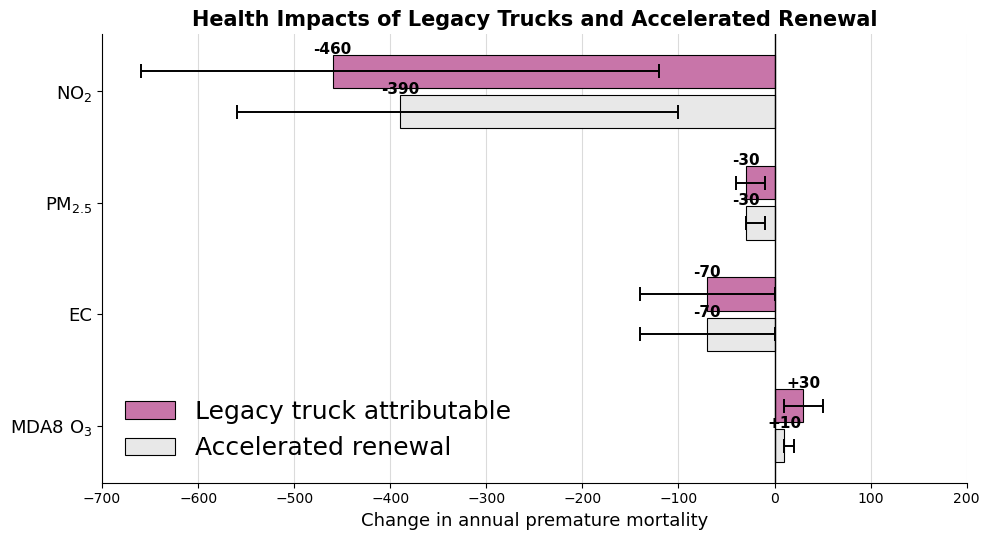

In [20]:
legacy_df = mortality_summary[
    mortality_summary["Metric"] == "zeropre2010s_minus_base"
].copy()

renewal_df = mortality_summary[
    mortality_summary["Metric"] == "renewal_minus_base"
].copy()

# ------------------------------------------------------------
# Keep only Turner et al. O3 health outcome
# ------------------------------------------------------------

legacy_colors = "#C875A9"
renewal_colors = "#E8E8E8"

label_map = {
    "NO2": r"NO$_2$",
    "PM25_TOT": r"PM$_{2.5}$",
    "PM25_EC": "EC",
    "O3_Turner2016": r"MDA8 O$_3$"
}

order = [
    "NO2",
    "PM25_TOT",
    "PM25_EC",
    "O3_Turner2016"
]

# Remove WHO O3 and any other pollutants not in desired order
legacy_df = legacy_df[
    legacy_df["Pollutant"].isin(order)
].copy()

renewal_df = renewal_df[
    renewal_df["Pollutant"].isin(order)
].copy()

for df in [legacy_df, renewal_df]:

    df["Pollutant"] = pd.Categorical(
        df["Pollutant"],
        categories=order,
        ordered=True
    )

    df.sort_values(
        "Pollutant",
        inplace=True
    )

    df["Label"] = df["Pollutant"].map(label_map)

# ------------------------------------------------------------
# Estimates and confidence intervals
# ------------------------------------------------------------

legacy_df["Estimate"] = legacy_df["Total_round10"]

legacy_df["Lower"] = np.minimum(
    legacy_df["Lower_round10"],
    legacy_df["Upper_round10"]
)

legacy_df["Upper"] = np.maximum(
    legacy_df["Lower_round10"],
    legacy_df["Upper_round10"]
)


renewal_df["Estimate"] = renewal_df["Total_round10"]

renewal_df["Lower"] = np.minimum(
    renewal_df["Lower_round10"],
    renewal_df["Upper_round10"]
)

renewal_df["Upper"] = np.maximum(
    renewal_df["Lower_round10"],
    renewal_df["Upper_round10"]
)

# ------------------------------------------------------------
# Error-bar widths
# ------------------------------------------------------------

legacy_lower_err = (
    legacy_df["Estimate"]
    - legacy_df["Lower"]
)

legacy_upper_err = (
    legacy_df["Upper"]
    - legacy_df["Estimate"]
)

renewal_lower_err = (
    renewal_df["Estimate"]
    - renewal_df["Lower"]
)

renewal_upper_err = (
    renewal_df["Upper"]
    - renewal_df["Estimate"]
)

# ------------------------------------------------------------
# Colors
# ------------------------------------------------------------

# ------------------------------------------------------------
# Colors — consistent with exposure/distributional panels
# ------------------------------------------------------------

legacy_color = "#C04A9A"
renewal_color = "#7FC3BE"
# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

y = np.arange(len(order))

bar_height = 0.30
offset = 0.18

y_legacy = y - offset
y_renewal = y + offset

ax.barh(
    y_legacy,
    legacy_df["Estimate"],
    height=bar_height,
    xerr=[
        legacy_lower_err,
        legacy_upper_err
    ],
    color=legacy_colors,
    edgecolor="black",
    linewidth=0.8,
    capsize=5,
    error_kw=dict(
        ecolor="black",
        lw=1.4,
        capthick=1.4
    ),
    label="Legacy truck attributable"
)

ax.barh(
    y_renewal,
    renewal_df["Estimate"],
    height=bar_height,
    xerr=[
        renewal_lower_err,
        renewal_upper_err
    ],
    color=renewal_colors,
    edgecolor="black",
    linewidth=0.8,
    capsize=5,
    error_kw=dict(
        ecolor="black",
        lw=1.4,
        capthick=1.4
    ),
    label="Accelerated renewal"
)

# ------------------------------------------------------------
# Zero line
# ------------------------------------------------------------

ax.axvline(
    0,
    color="black",
    lw=1
)

# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_yticks(y)

ax.set_yticklabels(
    legacy_df["Label"],
    fontsize=13
)

ax.set_xlabel(
    "Change in annual premature mortality",
    fontsize=13
)

ax.set_title(
    "Health Impacts of Legacy Trucks and Accelerated Renewal",
    fontsize=15,
    fontweight="bold"
)

# ------------------------------------------------------------
# Value labels
# ------------------------------------------------------------

for ypos, val in zip(
    y_legacy,
    legacy_df["Estimate"]
):
    ax.text(
        val,
        ypos - 0.13,
        f"{val:+.0f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

for ypos, val in zip(
    y_renewal,
    renewal_df["Estimate"]
):
    ax.text(
        val,
        ypos - 0.13,
        f"{val:+.0f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_xlim(
    -700,
    200
)

ax.invert_yaxis()

ax.grid(
    axis="x",
    alpha=0.45
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    fontsize=18
)

plt.tight_layout()
plt.show()

<h1> Population Weighted Exposure 
    
    
<h3>
$$
\text{Domain Total Population Weighted Average Concentrations} = \frac{\sum (\text{Concentrations}_{\text{CT}} \times \text{Population Total}_{\text{CT}})}{\sum (\text{Population Total}_{\text{CT}})}
$$

<h3>
$$
\text{Subgroup Population Weighted Average Concentrations} = \frac{\sum (\text{Concentrations}_{\text{CT}} \times \text{Subgroup Population Total}_{\text{CT}})}{\sum (\text{Subgroup Population Total}_{\text{CT}})}
$$    
    

<h3>
$$
\text{Relative Concentrations Disparity} = \frac{(
\frac{\sum (\text{Concentrations}_{\text{CT}} \times \text{Subgroup Population Total}_{\text{CT}})}{\sum (\text{Subgroup Population Total}_{\text{CT}})})
}{
(\frac{\sum (\text{Concentrations}_{\text{CT}} \times \text{Population Total}_{\text{CT}})}{\sum (\text{Population Total}_{\text{CT}})})
}
$$


In [91]:
# Population represented in the exposure analysis
pop_cols = {"Total": "ASOAE001", "White": "ASOAE003", "Black": "ASOAE004", "Hispanic": "ASOAE012", "Asian": "ASOAE006", "Other": "OTHER_POP"}
total_pop = base_joined["ASOAE001"].sum()
for group, col in pop_cols.items():
    pop = base_joined[col].sum()
    print(f"{group}: {pop:,.0f} ({pop / total_pop * 100:.1f}%)")

Total: 7,893,946 (100.0%)
White: 3,801,572 (48.2%)
Black: 1,290,733 (16.4%)
Hispanic: 1,965,443 (24.9%)
Asian: 580,367 (7.4%)
Other: 255,831 (3.2%)


In [21]:
cmap_base['MDA8O3'] = cmap_base_o3['O3']
cmap_zeropre2010s['MDA8O3'] = cmap_zeropre2010s_o3['O3']
cmap_renewal['MDA8O3'] = cmap_renewal_o3['O3']

In [22]:
base_joined = domain_demo.merge(cmap_base, on='GISJOIN', how='inner')
renewal_joined = domain_demo.merge(cmap_renewal, on='GISJOIN', how='inner')
zeropre2010s_joined = domain_demo.merge(cmap_zeropre2010s, on='GISJOIN', how='inner')

In [23]:
base_joined['OTHER_POP'] = (
    base_joined['ASOAE001'] - (
        base_joined['ASOAE003'] +   # NH White
        base_joined['ASOAE004'] +   # NH Black
        base_joined['ASOAE006'] +   # NH Asian
        base_joined['ASOAE012']     # Hispanic any race
    )
)

renewal_joined['OTHER_POP'] = (
    renewal_joined['ASOAE001'] - (
        renewal_joined['ASOAE003'] +
        renewal_joined['ASOAE004'] +
        renewal_joined['ASOAE006'] +
        renewal_joined['ASOAE012']
    )
)

zeropre2010s_joined['OTHER_POP'] = (
    zeropre2010s_joined['ASOAE001'] - (
        zeropre2010s_joined['ASOAE003'] +
        zeropre2010s_joined['ASOAE004'] +
        zeropre2010s_joined['ASOAE006'] +
        zeropre2010s_joined['ASOAE012']
    )
)

In [24]:
base_joined['PopWeightedNO2'] = (base_joined['NO2'] * base_joined['ASOAE001']).sum() / base_joined['ASOAE001'].sum()
zeropre2010s_joined['PopWeightedNO2'] = (zeropre2010s_joined['NO2'] * zeropre2010s_joined['ASOAE001']).sum() / zeropre2010s_joined['ASOAE001'].sum()
renewal_joined['PopWeightedNO2'] = (renewal_joined['NO2'] * renewal_joined['ASOAE001']).sum() / renewal_joined['ASOAE001'].sum()

# ------------------------------------------------------------
# subgroup population-weighted concentration
# ------------------------------------------------------------
for df in [base_joined,renewal_joined, zeropre2010s_joined]:
    df['White_PopWeightedNO2'] = (df['NO2'] * df['ASOAE003']).sum() / df['ASOAE003'].sum()
    df['Black_PopWeightedNO2'] = (df['NO2'] * df['ASOAE004']).sum() / df['ASOAE004'].sum()
    df['Hispanic_PopWeightedNO2'] = (df['NO2'] * df['ASOAE012']).sum() / df['ASOAE012'].sum()
    df['Asian_PopWeightedNO2'] = (df['NO2'] * df['ASOAE006']).sum() / df['ASOAE006'].sum()
    df['Other_PopWeightedNO2'] = (df['NO2'] * df['OTHER_POP']).sum() / df['OTHER_POP'].sum()

# ------------------------------------------------------------
# relative disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined,zeropre2010s_joined]:
    df['White_RelNO2'] = df['White_PopWeightedNO2'] / df['PopWeightedNO2']
    df['Black_RelNO2'] = df['Black_PopWeightedNO2'] / df['PopWeightedNO2']
    df['Hispanic_RelNO2'] = df['Hispanic_PopWeightedNO2'] / df['PopWeightedNO2']
    df['Asian_RelNO2'] = df['Asian_PopWeightedNO2'] / df['PopWeightedNO2']
    df['Other_RelNO2'] = df['Other_PopWeightedNO2'] / df['PopWeightedNO2']

# ------------------------------------------------------------
# absolute disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined,zeropre2010s_joined]:
    df['White_AbsNO2'] = df['White_PopWeightedNO2'] - df['PopWeightedNO2']
    df['Black_AbsNO2'] = df['Black_PopWeightedNO2'] - df['PopWeightedNO2']
    df['Hispanic_AbsNO2'] = df['Hispanic_PopWeightedNO2'] - df['PopWeightedNO2']
    df['Asian_AbsNO2'] = df['Asian_PopWeightedNO2'] - df['PopWeightedNO2']
    df['Other_AbsNO2'] = df['Other_PopWeightedNO2'] - df['PopWeightedNO2']

# ------------------------------------------------------------
# summary table
# ------------------------------------------------------------
no2_summary = pd.DataFrame({
    'Base_PopWeighted'    : [base_joined['PopWeightedNO2'].iloc[0], base_joined['White_PopWeightedNO2'].iloc[0], base_joined['Black_PopWeightedNO2'].iloc[0], base_joined['Hispanic_PopWeightedNO2'].iloc[0], base_joined['Asian_PopWeightedNO2'].iloc[0], base_joined['Other_PopWeightedNO2'].iloc[0]],
    'Base_Relative'       : [1.0, base_joined['White_RelNO2'].iloc[0], base_joined['Black_RelNO2'].iloc[0], base_joined['Hispanic_RelNO2'].iloc[0], base_joined['Asian_RelNO2'].iloc[0], base_joined['Other_RelNO2'].iloc[0]],
    'Base_Absolute'       : [0.0, base_joined['White_AbsNO2'].iloc[0], base_joined['Black_AbsNO2'].iloc[0], base_joined['Hispanic_AbsNO2'].iloc[0], base_joined['Asian_AbsNO2'].iloc[0], base_joined['Other_AbsNO2'].iloc[0]],

    'Renewal_PopWeighted'  : [renewal_joined['PopWeightedNO2'].iloc[0], renewal_joined['White_PopWeightedNO2'].iloc[0], renewal_joined['Black_PopWeightedNO2'].iloc[0], renewal_joined['Hispanic_PopWeightedNO2'].iloc[0], renewal_joined['Asian_PopWeightedNO2'].iloc[0], renewal_joined['Other_PopWeightedNO2'].iloc[0]],
    'Renewal_Relative'     : [1.0, renewal_joined['White_RelNO2'].iloc[0], renewal_joined['Black_RelNO2'].iloc[0], renewal_joined['Hispanic_RelNO2'].iloc[0], renewal_joined['Asian_RelNO2'].iloc[0], renewal_joined['Other_RelNO2'].iloc[0]],
    'Renewal_Absolute'     : [0.0, renewal_joined['White_AbsNO2'].iloc[0], renewal_joined['Black_AbsNO2'].iloc[0], renewal_joined['Hispanic_AbsNO2'].iloc[0], renewal_joined['Asian_AbsNO2'].iloc[0], renewal_joined['Other_AbsNO2'].iloc[0]],

    'zeropre2010s_PopWeighted'  : [zeropre2010s_joined['PopWeightedNO2'].iloc[0], zeropre2010s_joined['White_PopWeightedNO2'].iloc[0], zeropre2010s_joined['Black_PopWeightedNO2'].iloc[0], zeropre2010s_joined['Hispanic_PopWeightedNO2'].iloc[0], zeropre2010s_joined['Asian_PopWeightedNO2'].iloc[0], zeropre2010s_joined['Other_PopWeightedNO2'].iloc[0]],
    'zeropre2010s_Relative'     : [1.0, zeropre2010s_joined['White_RelNO2'].iloc[0], zeropre2010s_joined['Black_RelNO2'].iloc[0], zeropre2010s_joined['Hispanic_RelNO2'].iloc[0], zeropre2010s_joined['Asian_RelNO2'].iloc[0], zeropre2010s_joined['Other_RelNO2'].iloc[0]],
    'zeropre2010s_Absolute'     : [0.0, zeropre2010s_joined['White_AbsNO2'].iloc[0], zeropre2010s_joined['Black_AbsNO2'].iloc[0], zeropre2010s_joined['Hispanic_AbsNO2'].iloc[0], zeropre2010s_joined['Asian_AbsNO2'].iloc[0], zeropre2010s_joined['Other_AbsNO2'].iloc[0]],

}, index=['Total','White','Black','Hispanic','Asian','Other'])

print("=== NO2 Summary ===")
print(no2_summary.round(6).to_string())

=== NO2 Summary ===
          Base_PopWeighted  Base_Relative  Base_Absolute  Renewal_PopWeighted  Renewal_Relative  Renewal_Absolute  zeropre2010s_PopWeighted  zeropre2010s_Relative  zeropre2010s_Absolute
Total             9.087728       1.000000       0.000000             8.258354          1.000000          0.000000                  8.102405               1.000000               0.000000
White             8.206743       0.903058      -0.880985             7.410547          0.897340         -0.847807                  7.275985               0.898003              -0.826420
Black            10.457266       1.150702       1.369539             9.569176          1.158727          1.310822                  9.368253               1.156231               1.265848
Hispanic          9.899646       1.089342       0.811919             9.062581          1.097384          0.804228                  8.898437               1.098246               0.796032
Asian             9.164934       1.008496       0.

In [25]:
# ------------------------------------------------------------
# overall population-weighted concentration
# ------------------------------------------------------------
base_joined['PopWeightedPM25_TOT'] = (base_joined['PM25_TOT'] * base_joined['ASOAE001']).sum() / base_joined['ASOAE001'].sum()
zeropre2010s_joined['PopWeightedPM25_TOT'] = (zeropre2010s_joined['PM25_TOT'] * zeropre2010s_joined['ASOAE001']).sum() / zeropre2010s_joined['ASOAE001'].sum()
renewal_joined['PopWeightedPM25_TOT'] = (renewal_joined['PM25_TOT'] * renewal_joined['ASOAE001']).sum() / renewal_joined['ASOAE001'].sum()

# ------------------------------------------------------------
# subgroup population-weighted concentration
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['ASOAE003']).sum() / df['ASOAE003'].sum()
    df['Black_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['ASOAE004']).sum() / df['ASOAE004'].sum()
    df['Hispanic_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['ASOAE012']).sum() / df['ASOAE012'].sum()
    df['Asian_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['ASOAE006']).sum() / df['ASOAE006'].sum()
    df['Other_PopWeightedPM25_TOT'] = (df['PM25_TOT'] * df['OTHER_POP']).sum() / df['OTHER_POP'].sum()

# ------------------------------------------------------------
# relative disparities
# ------------------------------------------------------------
for df in [base_joined,renewal_joined, zeropre2010s_joined]:
    df['White_RelPM25_TOT'] = df['White_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']
    df['Black_RelPM25_TOT'] = df['Black_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']
    df['Hispanic_RelPM25_TOT'] = df['Hispanic_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']
    df['Asian_RelPM25_TOT'] = df['Asian_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']
    df['Other_RelPM25_TOT'] = df['Other_PopWeightedPM25_TOT'] / df['PopWeightedPM25_TOT']

# ------------------------------------------------------------
# absolute disparities
# ------------------------------------------------------------
for df in [base_joined,renewal_joined, zeropre2010s_joined]:
    df['White_AbsPM25_TOT'] = df['White_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']
    df['Black_AbsPM25_TOT'] = df['Black_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']
    df['Hispanic_AbsPM25_TOT'] = df['Hispanic_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']
    df['Asian_AbsPM25_TOT'] = df['Asian_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']
    df['Other_AbsPM25_TOT'] = df['Other_PopWeightedPM25_TOT'] - df['PopWeightedPM25_TOT']

# ------------------------------------------------------------
# summary table
# ------------------------------------------------------------
pm25_tot_summary = pd.DataFrame({
    'Base_PopWeighted'    : [base_joined['PopWeightedPM25_TOT'].iloc[0], base_joined['White_PopWeightedPM25_TOT'].iloc[0], base_joined['Black_PopWeightedPM25_TOT'].iloc[0], base_joined['Hispanic_PopWeightedPM25_TOT'].iloc[0], base_joined['Asian_PopWeightedPM25_TOT'].iloc[0], base_joined['Other_PopWeightedPM25_TOT'].iloc[0]],
    'Base_Relative'       : [1.0, base_joined['White_RelPM25_TOT'].iloc[0], base_joined['Black_RelPM25_TOT'].iloc[0], base_joined['Hispanic_RelPM25_TOT'].iloc[0], base_joined['Asian_RelPM25_TOT'].iloc[0], base_joined['Other_RelPM25_TOT'].iloc[0]],
    'Base_Absolute'       : [0.0, base_joined['White_AbsPM25_TOT'].iloc[0], base_joined['Black_AbsPM25_TOT'].iloc[0], base_joined['Hispanic_AbsPM25_TOT'].iloc[0], base_joined['Asian_AbsPM25_TOT'].iloc[0], base_joined['Other_AbsPM25_TOT'].iloc[0]],

    'Renewal_PopWeighted'  : [renewal_joined['PopWeightedPM25_TOT'].iloc[0], renewal_joined['White_PopWeightedPM25_TOT'].iloc[0], renewal_joined['Black_PopWeightedPM25_TOT'].iloc[0], renewal_joined['Hispanic_PopWeightedPM25_TOT'].iloc[0], renewal_joined['Asian_PopWeightedPM25_TOT'].iloc[0], renewal_joined['Other_PopWeightedPM25_TOT'].iloc[0]],
    'Renewal_Relative'     : [1.0, renewal_joined['White_RelPM25_TOT'].iloc[0], renewal_joined['Black_RelPM25_TOT'].iloc[0], renewal_joined['Hispanic_RelPM25_TOT'].iloc[0], renewal_joined['Asian_RelPM25_TOT'].iloc[0], renewal_joined['Other_RelPM25_TOT'].iloc[0]],
    'Renewal_Absolute'     : [0.0, renewal_joined['White_AbsPM25_TOT'].iloc[0], renewal_joined['Black_AbsPM25_TOT'].iloc[0], renewal_joined['Hispanic_AbsPM25_TOT'].iloc[0], renewal_joined['Asian_AbsPM25_TOT'].iloc[0], renewal_joined['Other_AbsPM25_TOT'].iloc[0]],

    'zeropre2010s_PopWeighted'  : [zeropre2010s_joined['PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['White_PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['Black_PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['Hispanic_PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['Asian_PopWeightedPM25_TOT'].iloc[0], zeropre2010s_joined['Other_PopWeightedPM25_TOT'].iloc[0]],
    'zeropre2010s_Relative'     : [1.0, zeropre2010s_joined['White_RelPM25_TOT'].iloc[0], zeropre2010s_joined['Black_RelPM25_TOT'].iloc[0], zeropre2010s_joined['Hispanic_RelPM25_TOT'].iloc[0], zeropre2010s_joined['Asian_RelPM25_TOT'].iloc[0], zeropre2010s_joined['Other_RelPM25_TOT'].iloc[0]],
    'zeropre2010s_Absolute'     : [0.0, zeropre2010s_joined['White_AbsPM25_TOT'].iloc[0], zeropre2010s_joined['Black_AbsPM25_TOT'].iloc[0], zeropre2010s_joined['Hispanic_AbsPM25_TOT'].iloc[0], zeropre2010s_joined['Asian_AbsPM25_TOT'].iloc[0], zeropre2010s_joined['Other_AbsPM25_TOT'].iloc[0]],

}, index=['Total','White','Black','Hispanic','Asian','Other'])

print("\n=== PM25_TOT Summary ===")
print(pm25_tot_summary.round(6).to_string())


=== PM25_TOT Summary ===
          Base_PopWeighted  Base_Relative  Base_Absolute  Renewal_PopWeighted  Renewal_Relative  Renewal_Absolute  zeropre2010s_PopWeighted  zeropre2010s_Relative  zeropre2010s_Absolute
Total            10.512787       1.000000       0.000000            10.442088          1.000000          0.000000                 10.419565               1.000000               0.000000
White            10.201635       0.970403      -0.311151            10.131952          0.970299         -0.310136                 10.114235               0.970697              -0.305329
Black            11.025157       1.048738       0.512371            10.957231          1.049333          0.515143                 10.930780               1.049063               0.511215
Hispanic         10.819507       1.029176       0.306720            10.748039          1.029300          0.305952                 10.719756               1.028810               0.300191
Asian            10.409863       0.990210   

In [26]:
# ------------------------------------------------------------
# overall population-weighted concentration
# ------------------------------------------------------------
base_joined['PopWeightedPM25_EC'] = (base_joined['PM25_EC'] * base_joined['ASOAE001']).sum() / base_joined['ASOAE001'].sum()
zeropre2010s_joined['PopWeightedPM25_EC'] = (zeropre2010s_joined['PM25_EC'] * zeropre2010s_joined['ASOAE001']).sum() / zeropre2010s_joined['ASOAE001'].sum()
renewal_joined['PopWeightedPM25_EC'] = (renewal_joined['PM25_EC'] * renewal_joined['ASOAE001']).sum() / renewal_joined['ASOAE001'].sum()

# ------------------------------------------------------------
# subgroup population-weighted concentration
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['ASOAE003']).sum() / df['ASOAE003'].sum()
    df['Black_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['ASOAE004']).sum() / df['ASOAE004'].sum()
    df['Hispanic_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['ASOAE012']).sum() / df['ASOAE012'].sum()
    df['Asian_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['ASOAE006']).sum() / df['ASOAE006'].sum()
    df['Other_PopWeightedPM25_EC'] = (df['PM25_EC'] * df['OTHER_POP']).sum() / df['OTHER_POP'].sum()

# ------------------------------------------------------------
# relative disparities
# ------------------------------------------------------------
for df in [base_joined,renewal_joined,  zeropre2010s_joined]:
    df['White_RelPM25_EC'] = df['White_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']
    df['Black_RelPM25_EC'] = df['Black_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']
    df['Hispanic_RelPM25_EC'] = df['Hispanic_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']
    df['Asian_RelPM25_EC'] = df['Asian_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']
    df['Other_RelPM25_EC'] = df['Other_PopWeightedPM25_EC'] / df['PopWeightedPM25_EC']

# ------------------------------------------------------------
# absolute disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_AbsPM25_EC'] = df['White_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']
    df['Black_AbsPM25_EC'] = df['Black_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']
    df['Hispanic_AbsPM25_EC'] = df['Hispanic_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']
    df['Asian_AbsPM25_EC'] = df['Asian_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']
    df['Other_AbsPM25_EC'] = df['Other_PopWeightedPM25_EC'] - df['PopWeightedPM25_EC']

# ------------------------------------------------------------
# summary table
# ------------------------------------------------------------
pm25_ec_summary = pd.DataFrame({
    'Base_PopWeighted'    : [base_joined['PopWeightedPM25_EC'].iloc[0], base_joined['White_PopWeightedPM25_EC'].iloc[0], base_joined['Black_PopWeightedPM25_EC'].iloc[0], base_joined['Hispanic_PopWeightedPM25_EC'].iloc[0], base_joined['Asian_PopWeightedPM25_EC'].iloc[0], base_joined['Other_PopWeightedPM25_EC'].iloc[0]],
    'Base_Relative'       : [1.0, base_joined['White_RelPM25_EC'].iloc[0], base_joined['Black_RelPM25_EC'].iloc[0], base_joined['Hispanic_RelPM25_EC'].iloc[0], base_joined['Asian_RelPM25_EC'].iloc[0], base_joined['Other_RelPM25_EC'].iloc[0]],
    'Base_Absolute'       : [0.0, base_joined['White_AbsPM25_EC'].iloc[0], base_joined['Black_AbsPM25_EC'].iloc[0], base_joined['Hispanic_AbsPM25_EC'].iloc[0], base_joined['Asian_AbsPM25_EC'].iloc[0], base_joined['Other_AbsPM25_EC'].iloc[0]],

    'Renewal_PopWeighted'  : [renewal_joined['PopWeightedPM25_EC'].iloc[0], renewal_joined['White_PopWeightedPM25_EC'].iloc[0], renewal_joined['Black_PopWeightedPM25_EC'].iloc[0], renewal_joined['Hispanic_PopWeightedPM25_EC'].iloc[0], renewal_joined['Asian_PopWeightedPM25_EC'].iloc[0], renewal_joined['Other_PopWeightedPM25_EC'].iloc[0]],
    'Renewal_Relative'     : [1.0, renewal_joined['White_RelPM25_EC'].iloc[0], renewal_joined['Black_RelPM25_EC'].iloc[0], renewal_joined['Hispanic_RelPM25_EC'].iloc[0], renewal_joined['Asian_RelPM25_EC'].iloc[0], renewal_joined['Other_RelPM25_EC'].iloc[0]],
    'Renewal_Absolute'     : [0.0, renewal_joined['White_AbsPM25_EC'].iloc[0], renewal_joined['Black_AbsPM25_EC'].iloc[0], renewal_joined['Hispanic_AbsPM25_EC'].iloc[0], renewal_joined['Asian_AbsPM25_EC'].iloc[0], renewal_joined['Other_AbsPM25_EC'].iloc[0]],

    'zeropre2010s_PopWeighted'  : [zeropre2010s_joined['PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['White_PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['Black_PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['Hispanic_PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['Asian_PopWeightedPM25_EC'].iloc[0], zeropre2010s_joined['Other_PopWeightedPM25_EC'].iloc[0]],
    'zeropre2010s_Relative'     : [1.0, zeropre2010s_joined['White_RelPM25_EC'].iloc[0], zeropre2010s_joined['Black_RelPM25_EC'].iloc[0], zeropre2010s_joined['Hispanic_RelPM25_EC'].iloc[0], zeropre2010s_joined['Asian_RelPM25_EC'].iloc[0], zeropre2010s_joined['Other_RelPM25_EC'].iloc[0]],
    'zeropre2010s_Absolute'     : [0.0, zeropre2010s_joined['White_AbsPM25_EC'].iloc[0], zeropre2010s_joined['Black_AbsPM25_EC'].iloc[0], zeropre2010s_joined['Hispanic_AbsPM25_EC'].iloc[0], zeropre2010s_joined['Asian_AbsPM25_EC'].iloc[0], zeropre2010s_joined['Other_AbsPM25_EC'].iloc[0]],

}, index=['Total','White','Black','Hispanic','Asian','Other'])

print("\n=== PM25_EC Summary ===")
print(pm25_ec_summary.round(6).to_string())


=== PM25_EC Summary ===
          Base_PopWeighted  Base_Relative  Base_Absolute  Renewal_PopWeighted  Renewal_Relative  Renewal_Absolute  zeropre2010s_PopWeighted  zeropre2010s_Relative  zeropre2010s_Absolute
Total             0.406834       1.000000       0.000000             0.353728          1.000000          0.000000                  0.352008               1.000000               0.000000
White             0.375957       0.924106      -0.030876             0.325957          0.921490         -0.027771                  0.324601               0.922143              -0.027406
Black             0.452270       1.111684       0.045437             0.394074          1.114059          0.040346                  0.391835               1.113144               0.039828
Hispanic          0.437797       1.076108       0.030963             0.383505          1.084181          0.029777                  0.381476               1.083714               0.029468
Asian             0.407357       1.001286    

In [27]:
# ------------------------------------------------------------
# overall population-weighted concentration
# ------------------------------------------------------------
base_joined['PopWeightedO3'] = (base_joined['O3'] * base_joined['ASOAE001']).sum() / base_joined['ASOAE001'].sum()
zeropre2010s_joined['PopWeightedO3'] = (zeropre2010s_joined['O3'] * zeropre2010s_joined['ASOAE001']).sum() / zeropre2010s_joined['ASOAE001'].sum()
renewal_joined['PopWeightedO3'] = (renewal_joined['O3'] * renewal_joined['ASOAE001']).sum() / renewal_joined['ASOAE001'].sum()

# ------------------------------------------------------------
# subgroup population-weighted concentration
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_PopWeightedO3'] = (df['O3'] * df['ASOAE003']).sum() / df['ASOAE003'].sum()
    df['Black_PopWeightedO3'] = (df['O3'] * df['ASOAE004']).sum() / df['ASOAE004'].sum()
    df['Hispanic_PopWeightedO3'] = (df['O3'] * df['ASOAE012']).sum() / df['ASOAE012'].sum()
    df['Asian_PopWeightedO3'] = (df['O3'] * df['ASOAE006']).sum() / df['ASOAE006'].sum()
    df['Other_PopWeightedO3'] = (df['O3'] * df['OTHER_POP']).sum() / df['OTHER_POP'].sum()

# ------------------------------------------------------------
# relative disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_RelO3'] = df['White_PopWeightedO3'] / df['PopWeightedO3']
    df['Black_RelO3'] = df['Black_PopWeightedO3'] / df['PopWeightedO3']
    df['Hispanic_RelO3'] = df['Hispanic_PopWeightedO3'] / df['PopWeightedO3']
    df['Asian_RelO3'] = df['Asian_PopWeightedO3'] / df['PopWeightedO3']
    df['Other_RelO3'] = df['Other_PopWeightedO3'] / df['PopWeightedO3']

# ------------------------------------------------------------
# absolute disparities
# ------------------------------------------------------------
for df in [base_joined, renewal_joined, zeropre2010s_joined]:
    df['White_AbsO3'] = df['White_PopWeightedO3'] - df['PopWeightedO3']
    df['Black_AbsO3'] = df['Black_PopWeightedO3'] - df['PopWeightedO3']
    df['Hispanic_AbsO3'] = df['Hispanic_PopWeightedO3'] - df['PopWeightedO3']
    df['Asian_AbsO3'] = df['Asian_PopWeightedO3'] - df['PopWeightedO3']
    df['Other_AbsO3'] = df['Other_PopWeightedO3'] - df['PopWeightedO3']


# ------------------------------------------------------------
# summary table
# ------------------------------------------------------------
O3_summary = pd.DataFrame({
    'Base_PopWeighted'    : [base_joined['PopWeightedO3'].iloc[0], base_joined['White_PopWeightedO3'].iloc[0], base_joined['Black_PopWeightedO3'].iloc[0], base_joined['Hispanic_PopWeightedO3'].iloc[0], base_joined['Asian_PopWeightedO3'].iloc[0], base_joined['Other_PopWeightedO3'].iloc[0]],
    'Base_Relative'       : [1.0, base_joined['White_RelO3'].iloc[0], base_joined['Black_RelO3'].iloc[0], base_joined['Hispanic_RelO3'].iloc[0], base_joined['Asian_RelO3'].iloc[0], base_joined['Other_RelO3'].iloc[0]],
    'Base_Absolute'       : [0.0, base_joined['White_AbsO3'].iloc[0], base_joined['Black_AbsO3'].iloc[0], base_joined['Hispanic_AbsO3'].iloc[0], base_joined['Asian_AbsO3'].iloc[0], base_joined['Other_AbsO3'].iloc[0]],

    'Renewal_PopWeighted'  : [renewal_joined['PopWeightedO3'].iloc[0], renewal_joined['White_PopWeightedO3'].iloc[0], renewal_joined['Black_PopWeightedO3'].iloc[0], renewal_joined['Hispanic_PopWeightedO3'].iloc[0], renewal_joined['Asian_PopWeightedO3'].iloc[0], renewal_joined['Other_PopWeightedO3'].iloc[0]],
    'Renewal_Relative'     : [1.0, renewal_joined['White_RelO3'].iloc[0], renewal_joined['Black_RelO3'].iloc[0], renewal_joined['Hispanic_RelO3'].iloc[0], renewal_joined['Asian_RelO3'].iloc[0], renewal_joined['Other_RelO3'].iloc[0]],
    'Renewal_Absolute'     : [0.0, renewal_joined['White_AbsO3'].iloc[0], renewal_joined['Black_AbsO3'].iloc[0], renewal_joined['Hispanic_AbsO3'].iloc[0], renewal_joined['Asian_AbsO3'].iloc[0], renewal_joined['Other_AbsO3'].iloc[0]],

    'zeropre2010s_PopWeighted'  : [zeropre2010s_joined['PopWeightedO3'].iloc[0], zeropre2010s_joined['White_PopWeightedO3'].iloc[0], zeropre2010s_joined['Black_PopWeightedO3'].iloc[0], zeropre2010s_joined['Hispanic_PopWeightedO3'].iloc[0], zeropre2010s_joined['Asian_PopWeightedO3'].iloc[0], zeropre2010s_joined['Other_PopWeightedO3'].iloc[0]],
    'zeropre2010s_Relative'     : [1.0, zeropre2010s_joined['White_RelO3'].iloc[0], zeropre2010s_joined['Black_RelO3'].iloc[0], zeropre2010s_joined['Hispanic_RelO3'].iloc[0], zeropre2010s_joined['Asian_RelO3'].iloc[0], zeropre2010s_joined['Other_RelO3'].iloc[0]],
    'zeropre2010s_Absolute'     : [0.0, zeropre2010s_joined['White_AbsO3'].iloc[0], zeropre2010s_joined['Black_AbsO3'].iloc[0], zeropre2010s_joined['Hispanic_AbsO3'].iloc[0], zeropre2010s_joined['Asian_AbsO3'].iloc[0], zeropre2010s_joined['Other_AbsO3'].iloc[0]],

}, index=['Total','White','Black','Hispanic','Asian','Other'])

print("\n=== O3 Summary ===")
print(O3_summary.round(6).to_string())


=== O3 Summary ===
          Base_PopWeighted  Base_Relative  Base_Absolute  Renewal_PopWeighted  Renewal_Relative  Renewal_Absolute  zeropre2010s_PopWeighted  zeropre2010s_Relative  zeropre2010s_Absolute
Total            34.026842       1.000000       0.000000            34.693385          1.000000          0.000000                 34.819785               1.000000               0.000000
White            34.578502       1.016212       0.551660            35.220814          1.015203          0.527429                 35.330191               1.014659               0.510406
Black            33.165102       0.974675      -0.861741            33.874130          0.976386         -0.819254                 34.036839               0.977514              -0.782946
Hispanic         33.464698       0.983479      -0.562144            34.136454          0.983947         -0.556931                 34.270198               0.984216              -0.549587
Asian            34.146534       1.003518       0.

In [28]:
subgroups_for_plot = ["Total", "White", "Black", "Hispanic", "Asian", "Other"]

colors_for_plot = {
    "Total": "#d9d9d9",
    "White": "#32448A",
    "Black": "#9d94ff",
    "Hispanic": "#ff6961",
    "Asian": "#ffb480",
    "Other": "#77dd77"
}

hatches = {
    "Baseline": "",
    "Accelerated Fleet Renewal": "\\",
    "Legacy Truck Removal": "//",

}

scenario_keys = ["Baseline", "Accelerated Fleet Renewal","Legacy Truck Removal"]
scenario_labels = ["Baseline","Accelerated Fleet Renewal", "Legacy Truck Removal"]

# ------------------------------------------------------------
# NO2
# ------------------------------------------------------------
base_no2_total = no2_summary.loc["Total", "Base_PopWeighted"]
base_no2_white = no2_summary.loc["White", "Base_PopWeighted"]
base_no2_black = no2_summary.loc["Black", "Base_PopWeighted"]
base_no2_hisp  = no2_summary.loc["Hispanic", "Base_PopWeighted"]
base_no2_asian = no2_summary.loc["Asian", "Base_PopWeighted"]
base_no2_other = no2_summary.loc["Other", "Base_PopWeighted"]

Renewal_no2_total = no2_summary.loc["Total", "Renewal_PopWeighted"]
Renewal_no2_white = no2_summary.loc["White", "Renewal_PopWeighted"]
Renewal_no2_black = no2_summary.loc["Black", "Renewal_PopWeighted"]
Renewal_no2_hisp  = no2_summary.loc["Hispanic", "Renewal_PopWeighted"]
Renewal_no2_asian = no2_summary.loc["Asian", "Renewal_PopWeighted"]
Renewal_no2_other = no2_summary.loc["Other", "Renewal_PopWeighted"]

zeropre2010sno2_total = no2_summary.loc["Total", "zeropre2010s_PopWeighted"]
zeropre2010sno2_white = no2_summary.loc["White", "zeropre2010s_PopWeighted"]
zeropre2010sno2_black = no2_summary.loc["Black", "zeropre2010s_PopWeighted"]
zeropre2010sno2_hisp  = no2_summary.loc["Hispanic", "zeropre2010s_PopWeighted"]
zeropre2010sno2_asian = no2_summary.loc["Asian", "zeropre2010s_PopWeighted"]
zeropre2010sno2_other = no2_summary.loc["Other", "zeropre2010s_PopWeighted"]

no2_vals = np.array([
    [base_no2_total,    base_no2_white,    base_no2_black,    base_no2_hisp,    base_no2_asian,    base_no2_other],
    [Renewal_no2_total,  Renewal_no2_white,  Renewal_no2_black,  Renewal_no2_hisp,  Renewal_no2_asian,  Renewal_no2_other],
    [zeropre2010sno2_total,  zeropre2010sno2_white,  zeropre2010sno2_black,  zeropre2010sno2_hisp,  zeropre2010sno2_asian,  zeropre2010sno2_other],
    ], dtype=float)

# ------------------------------------------------------------
# PM25 total
# ------------------------------------------------------------
base_pm25tot_total = pm25_tot_summary.loc["Total", "Base_PopWeighted"]
base_pm25tot_white = pm25_tot_summary.loc["White", "Base_PopWeighted"]
base_pm25tot_black = pm25_tot_summary.loc["Black", "Base_PopWeighted"]
base_pm25tot_hisp  = pm25_tot_summary.loc["Hispanic", "Base_PopWeighted"]
base_pm25tot_asian = pm25_tot_summary.loc["Asian", "Base_PopWeighted"]
base_pm25tot_other = pm25_tot_summary.loc["Other", "Base_PopWeighted"]

Renewal_pm25tot_total = pm25_tot_summary.loc["Total", "Renewal_PopWeighted"]
Renewal_pm25tot_white = pm25_tot_summary.loc["White", "Renewal_PopWeighted"]
Renewal_pm25tot_black = pm25_tot_summary.loc["Black", "Renewal_PopWeighted"]
Renewal_pm25tot_hisp  = pm25_tot_summary.loc["Hispanic", "Renewal_PopWeighted"]
Renewal_pm25tot_asian = pm25_tot_summary.loc["Asian", "Renewal_PopWeighted"]
Renewal_pm25tot_other = pm25_tot_summary.loc["Other", "Renewal_PopWeighted"]

zeropre2010spm25tot_total = pm25_tot_summary.loc["Total", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_white = pm25_tot_summary.loc["White", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_black = pm25_tot_summary.loc["Black", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_hisp  = pm25_tot_summary.loc["Hispanic", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_asian = pm25_tot_summary.loc["Asian", "zeropre2010s_PopWeighted"]
zeropre2010spm25tot_other = pm25_tot_summary.loc["Other", "zeropre2010s_PopWeighted"]

pm25tot_vals = np.array([
    [base_pm25tot_total,    base_pm25tot_white,    base_pm25tot_black,    base_pm25tot_hisp,    base_pm25tot_asian,    base_pm25tot_other],
    [Renewal_pm25tot_total,  Renewal_pm25tot_white,  Renewal_pm25tot_black,  Renewal_pm25tot_hisp,  Renewal_pm25tot_asian,  Renewal_pm25tot_other], 
    [zeropre2010spm25tot_total,  zeropre2010spm25tot_white,  zeropre2010spm25tot_black,  zeropre2010spm25tot_hisp,  zeropre2010spm25tot_asian,  zeropre2010spm25tot_other]
    ], dtype=float)

# ------------------------------------------------------------
# PM25 EC
# ------------------------------------------------------------
base_pm25ec_total = pm25_ec_summary.loc["Total", "Base_PopWeighted"]
base_pm25ec_white = pm25_ec_summary.loc["White", "Base_PopWeighted"]
base_pm25ec_black = pm25_ec_summary.loc["Black", "Base_PopWeighted"]
base_pm25ec_hisp  = pm25_ec_summary.loc["Hispanic", "Base_PopWeighted"]
base_pm25ec_asian = pm25_ec_summary.loc["Asian", "Base_PopWeighted"]
base_pm25ec_other = pm25_ec_summary.loc["Other", "Base_PopWeighted"]

Renewal_pm25ec_total = pm25_ec_summary.loc["Total", "Renewal_PopWeighted"]
Renewal_pm25ec_white = pm25_ec_summary.loc["White", "Renewal_PopWeighted"]
Renewal_pm25ec_black = pm25_ec_summary.loc["Black", "Renewal_PopWeighted"]
Renewal_pm25ec_hisp  = pm25_ec_summary.loc["Hispanic", "Renewal_PopWeighted"]
Renewal_pm25ec_asian = pm25_ec_summary.loc["Asian", "Renewal_PopWeighted"]
Renewal_pm25ec_other = pm25_ec_summary.loc["Other", "Renewal_PopWeighted"]

zeropre2010spm25ec_total = pm25_ec_summary.loc["Total", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_white = pm25_ec_summary.loc["White", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_black = pm25_ec_summary.loc["Black", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_hisp  = pm25_ec_summary.loc["Hispanic", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_asian = pm25_ec_summary.loc["Asian", "zeropre2010s_PopWeighted"]
zeropre2010spm25ec_other = pm25_ec_summary.loc["Other", "zeropre2010s_PopWeighted"]


pm25ec_vals = np.array([
    [base_pm25ec_total,    base_pm25ec_white,    base_pm25ec_black,    base_pm25ec_hisp,    base_pm25ec_asian,    base_pm25ec_other],
    [Renewal_pm25ec_total,  Renewal_pm25ec_white,  Renewal_pm25ec_black,  Renewal_pm25ec_hisp,  Renewal_pm25ec_asian,  Renewal_pm25ec_other],
    [zeropre2010spm25ec_total,  zeropre2010spm25ec_white,  zeropre2010spm25ec_black,  zeropre2010spm25ec_hisp,  zeropre2010spm25ec_asian,  zeropre2010spm25ec_other],
   ], dtype=float)

# ------------------------------------------------------------
# O3
# ------------------------------------------------------------
base_o3_total = O3_summary.loc["Total", "Base_PopWeighted"]
base_o3_white = O3_summary.loc["White", "Base_PopWeighted"]
base_o3_black = O3_summary.loc["Black", "Base_PopWeighted"]
base_o3_hisp  = O3_summary.loc["Hispanic", "Base_PopWeighted"]
base_o3_asian = O3_summary.loc["Asian", "Base_PopWeighted"]
base_o3_other = O3_summary.loc["Other", "Base_PopWeighted"]

Renewal_o3_total = O3_summary.loc["Total", "Renewal_PopWeighted"]
Renewal_o3_white = O3_summary.loc["White", "Renewal_PopWeighted"]
Renewal_o3_black = O3_summary.loc["Black", "Renewal_PopWeighted"]
Renewal_o3_hisp  = O3_summary.loc["Hispanic", "Renewal_PopWeighted"]
Renewal_o3_asian = O3_summary.loc["Asian", "Renewal_PopWeighted"]
Renewal_o3_other = O3_summary.loc["Other", "Renewal_PopWeighted"]

zeropre2010so3_total = O3_summary.loc["Total", "zeropre2010s_PopWeighted"]
zeropre2010so3_white = O3_summary.loc["White", "zeropre2010s_PopWeighted"]
zeropre2010so3_black = O3_summary.loc["Black", "zeropre2010s_PopWeighted"]
zeropre2010so3_hisp  = O3_summary.loc["Hispanic", "zeropre2010s_PopWeighted"]
zeropre2010so3_asian = O3_summary.loc["Asian", "zeropre2010s_PopWeighted"]
zeropre2010so3_other = O3_summary.loc["Other", "zeropre2010s_PopWeighted"]


o3_vals = np.array([
    [base_o3_total,    base_o3_white,    base_o3_black,    base_o3_hisp,    base_o3_asian,    base_o3_other],
    [Renewal_o3_total,  Renewal_o3_white,  Renewal_o3_black,  Renewal_o3_hisp,  Renewal_o3_asian,  Renewal_o3_other],
    [zeropre2010so3_total,  zeropre2010so3_white,  zeropre2010so3_black,  zeropre2010so3_hisp,  zeropre2010so3_asian,  zeropre2010so3_other],
   ], dtype=float)

In [54]:
# ============================================================
# RACE / ETHNICITY POPULATION COLUMNS
# ============================================================

race_labels = [
    "Hispanic",
    "Asian",
    "Black",
    "White",
    "Other"
]

race_colors = [
    "#ff6961",  # Hispanic
    "#ffb480",  # Asian
    "#9d94ff",  # Black
    "#32448A",  # White
    "#77dd77"   # Other
]


# ============================================================
# CREATE OTHER POPULATION
# ============================================================

# Same definition used in your population-weighted exposure code
full_merged["OTHER_POP"] = (
    full_merged["ASOAE001"]
    - (
        full_merged["ASOAE003"]   # NH White
        + full_merged["ASOAE004"] # NH Black
        + full_merged["ASOAE006"] # NH Asian
        + full_merged["ASOAE012"] # Hispanic, any race
    )
)

race_population_columns = {
    "Hispanic": "ASOAE012",
    "Asian": "ASOAE006",
    "Black": "ASOAE004",
    "White": "ASOAE003",
    "Other": "OTHER_POP"
}


# ============================================================
# CREATE EXPOSURE DECILES
# ============================================================

def create_exposure_deciles(df, exposure_column):

    result = df.copy()

    valid_mask = (
        result[exposure_column].notna()
        & result["ASOAE001"].notna()
        & (result["ASOAE001"] > 0)
    )

    result["Exposure"] = np.nan
    result["Exposure_decile"] = np.nan

    result.loc[
        valid_mask,
        "Exposure"
    ] = result.loc[
        valid_mask,
        exposure_column
    ]

    result.loc[
        valid_mask,
        "Exposure_decile"
    ] = (
        pd.qcut(
            result.loc[valid_mask, exposure_column],
            q=10,
            labels=False,
            duplicates="drop"
        ) + 1
    )

    return result


# ============================================================
# CALCULATE RACIAL / ETHNIC COMPOSITION OF EACH DECILE
# ============================================================

def calculate_race_distribution(df):

    rows = []

    for decile in range(1, 11):

        subset = df[
            df["Exposure_decile"] == decile
        ]

        counts = {
            race: subset[column].sum()
            for race, column in race_population_columns.items()
        }

        total_population = sum(counts.values())

        if total_population > 0:
            percentages = {
                race: count / total_population * 100
                for race, count in counts.items()
            }
        else:
            percentages = {
                race: np.nan
                for race in race_labels
            }

        percentages["Exposure_decile"] = decile
        rows.append(percentages)

    return (
        pd.DataFrame(rows)
        .set_index("Exposure_decile")
        .reindex(range(1, 11))
    )

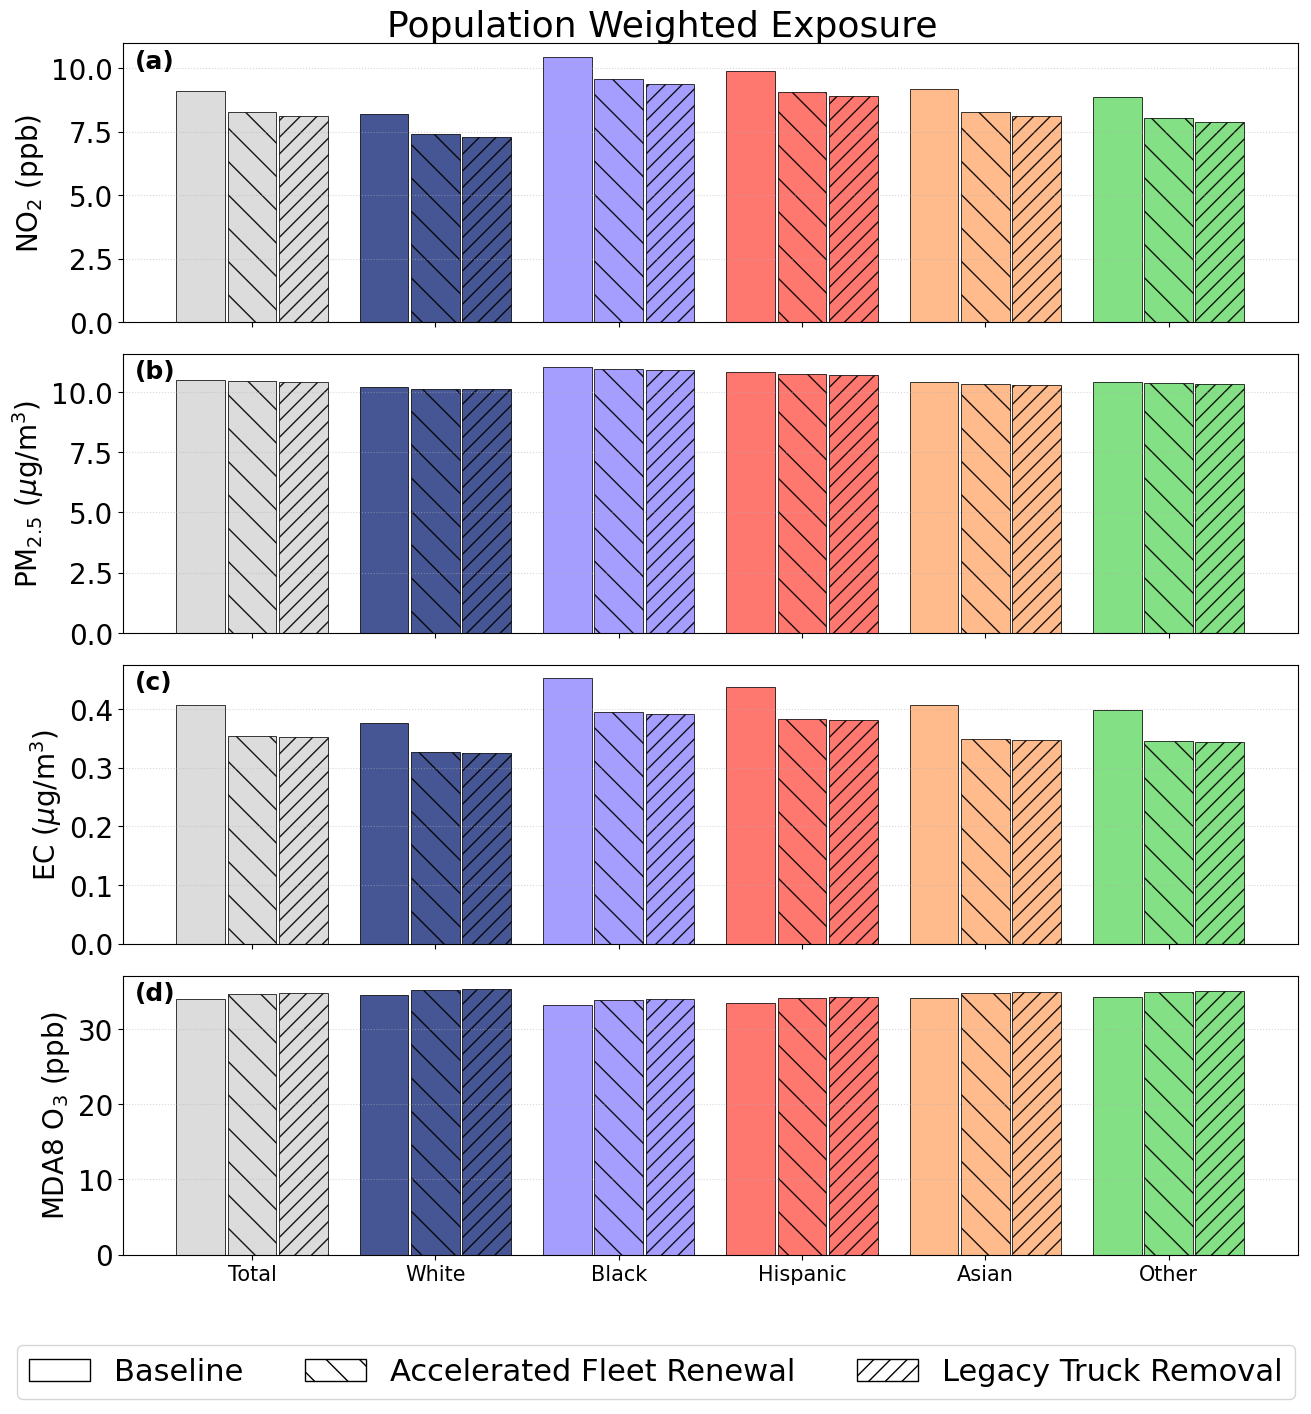

In [29]:
fig, axes = plt.subplots(4, 1, figsize=(13, 15), sharex=True)

labels = ["(a)", "(b)", "(c)", "(d)"]

x = np.arange(len(subgroups_for_plot))
cluster_w = 0.84
bar_w = cluster_w / len(scenario_keys)
offsets = (np.arange(len(scenario_keys)) - (len(scenario_keys) - 1) / 2) * bar_w

# --- NO2 ---
ax = axes[0]
for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups_for_plot):
        ax.bar(
            x[i] + offsets[s],
            no2_vals[s, i],
            width=bar_w * 0.95,
            color=colors_for_plot[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6,
            alpha=0.9
        )
#ax.set_title("Population-Weighted NO$_2$", fontsize=22)
ax.text(
    0.01, 0.98, labels[0],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.tick_params(axis='y', labelsize=20)

# --- PM25 total ---
ax = axes[1]
for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups_for_plot):
        ax.bar(
            x[i] + offsets[s],
            pm25tot_vals[s, i],
            width=bar_w * 0.95,
            color=colors_for_plot[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6,
            alpha=0.9
        )
#ax.set_title("Population-Weighted PM$_{2.5}$", fontsize=22)
ax.text(
    0.01, 0.98, labels[1],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.tick_params(axis='y', labelsize=20)

# --- PM25 EC ---
ax = axes[2]
for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups_for_plot):
        ax.bar(
            x[i] + offsets[s],
            pm25ec_vals[s, i],
            width=bar_w * 0.95,
            color=colors_for_plot[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6,
            alpha=0.9
        )
#ax.set_title("Population-Weighted EC", fontsize=22)
ax.text(
    0.01, 0.98, labels[2],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.grid(axis="y", linestyle=":", alpha=0.5)

ax.tick_params(axis='y', labelsize=20)

# --- O3 ---
ax = axes[3]
for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups_for_plot):
        ax.bar(
            x[i] + offsets[s],
            o3_vals[s, i],
            width=bar_w * 0.95,
            color=colors_for_plot[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6,
            alpha=0.9
        )
#ax.set_title("Population-Weighted MDA8 O$_3$", fontsize=22)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.tick_params(axis='y', labelsize=20)
ax.text(
    0.01, 0.98, labels[3],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
axes[3].set_xticks(x)
axes[3].set_xticklabels(subgroups_for_plot, fontsize=15)

# ------------------------------------------------------------
# legends
# ------------------------------------------------------------
race_patches = [
    mpatches.Patch(facecolor=colors_for_plot[g], edgecolor="black", label=g)
    for g in subgroups_for_plot
]

scenario_patches = [
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        hatch=hatches[k],
        label=scenario_labels[i]
    )
    for i, k in enumerate(scenario_keys)
]

axes[0].set_ylabel("NO$_2$ (ppb)", fontsize=20)
axes[1].set_ylabel("PM$_{2.5}$ ($\\mu$g/m$^3$)", fontsize=20)
axes[2].set_ylabel("EC ($\\mu$g/m$^3$)", fontsize=20)
axes[3].set_ylabel("MDA8 O$_3$ (ppb)", fontsize=20)

fig.suptitle(
    "Population Weighted Exposure",
    fontsize=26,
    y=0.94,
)
fig.legend(
    handles=scenario_patches,
    fontsize=22,
    loc="lower center",
    ncol=3,
    frameon=True
)
#plt.savefig('Annual_PWConcentrations_ZeroPre2010s.png')
plt.tight_layout(rect=[0, 0.08, 1, 0.96])
plt.show()

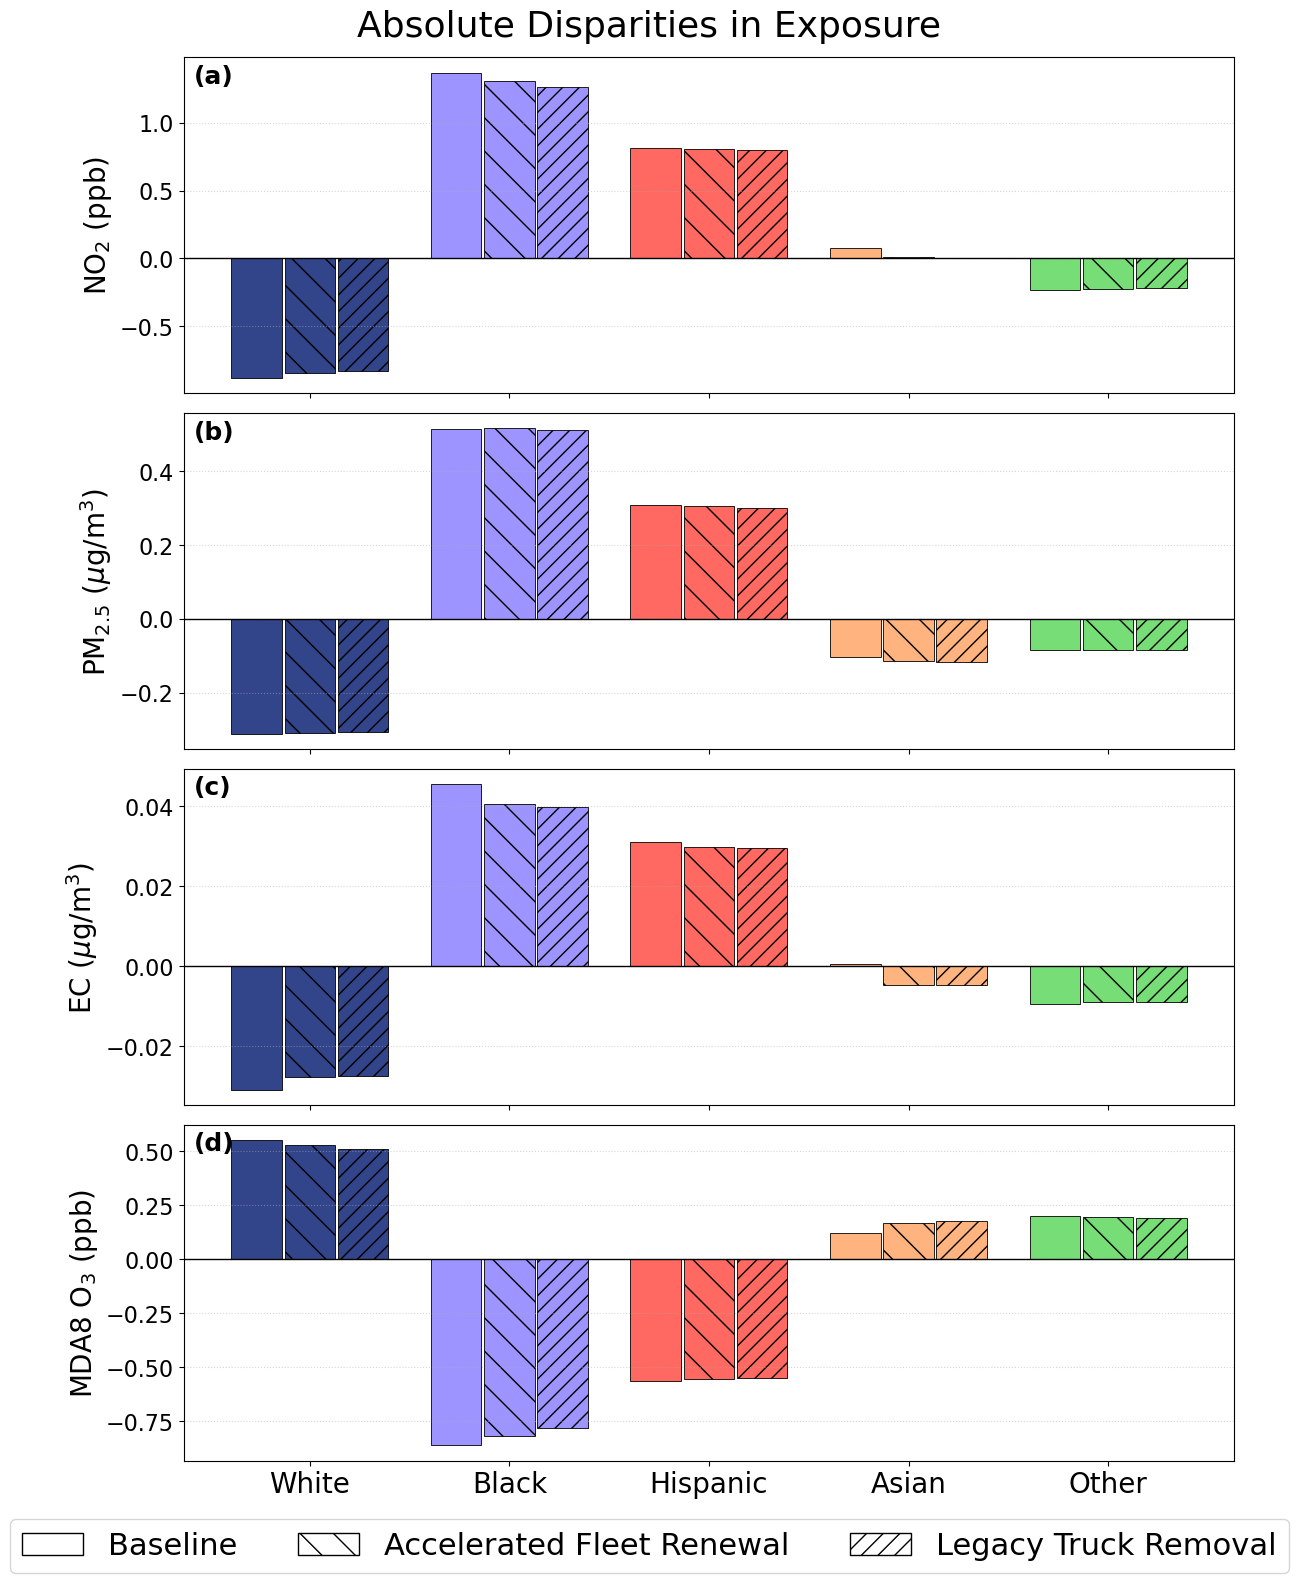

In [30]:
subgroups = ["White", "Black", "Hispanic", "Asian", "Other"]
scenario_keys = ["Base","Renewal", "zeropre2010s"]
scenario_labels = ["Baseline", "Accelerated Fleet Renewal","Legacy Truck Removal"]

hatches = {
    "Base": "",
    "Renewal": "\\",
    "zeropre2010s": "//",
}

colors = {
    "White": "#32448A",
    "Black": "#9d94ff",
    "Hispanic": "#ff6961",
    "Asian": "#ffb480",
    "Other": "#77dd77",
}

fig, axes = plt.subplots(4, 1, figsize=(12, 16), sharex=True)

x = np.arange(len(subgroups))
cluster_w = 0.8
bar_w = cluster_w / len(scenario_keys)
offsets = (np.arange(len(scenario_keys)) - (len(scenario_keys)-1)/2) * bar_w

# ------------------------------------------------------------
# NO2 absolute disparities
# ------------------------------------------------------------
ax = axes[0]

for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups):
        ax.bar(
            x[i] + offsets[s],
            no2_summary.loc[g, f"{key}_Absolute"],
            width=bar_w * 0.95,
            color=colors[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6
        )

ax.axhline(0, color="black", linewidth=1)
#ax.set_title("Absolute NO$_2$ Disparities", fontsize=22)
ax.text(
    0.01, 0.98, labels[0],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.set_ylabel("ppb", fontsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# ------------------------------------------------------------
# PM25_TOT absolute disparities
# ------------------------------------------------------------
ax = axes[1]

for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups):
        ax.bar(
            x[i] + offsets[s],
            pm25_tot_summary.loc[g, f"{key}_Absolute"],
            width=bar_w * 0.95,
            color=colors[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6
        )

ax.axhline(0, color="black", linewidth=1)
#ax.set_title("Absolute PM$_{2.5}$ Disparities", fontsize=22)
ax.set_ylabel(r"$\mu g \, m^{-3}$", fontsize=16)
ax.text(
    0.01, 0.98, labels[1],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.tick_params(axis='y', labelsize=16)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# ------------------------------------------------------------
# PM25_EC absolute disparities
# ------------------------------------------------------------
ax = axes[2]

for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups):
        ax.bar(
            x[i] + offsets[s],
            pm25_ec_summary.loc[g, f"{key}_Absolute"],
            width=bar_w * 0.95,
            color=colors[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6
        )

ax.axhline(0, color="black", linewidth=1)
#ax.set_title("Absolute EC Disparities", fontsize=22)
ax.text(
    0.01, 0.98, labels[2],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.set_ylabel(r"$\mu g \, m^{-3}$", fontsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# ------------------------------------------------------------
# O3 absolute disparities
# ------------------------------------------------------------
ax = axes[3]

for s, key in enumerate(scenario_keys):
    for i, g in enumerate(subgroups):
        ax.bar(
            x[i] + offsets[s],
            O3_summary.loc[g, f"{key}_Absolute"],
            width=bar_w * 0.95,
            color=colors[g],
            hatch=hatches[key],
            edgecolor="black",
            linewidth=0.6
        )

ax.axhline(0, color="black", linewidth=1)
#ax.set_title("Absolute MDA8 O$_3$ Disparities", fontsize=22)
ax.text(
    0.01, 0.98, labels[3],
    transform=ax.transAxes,
    fontsize=18,
    fontweight="bold",
    va="top",
    ha="left"
)
ax.set_ylabel("ppb", fontsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.grid(axis="y", linestyle=":", alpha=0.5)

axes[3].set_xticks(x)
axes[3].set_xticklabels(subgroups, fontsize=20)

scenario_patches = [
    mpatches.Patch(facecolor="white", edgecolor="black", hatch=hatches[k], label=scenario_labels[i])
    for i, k in enumerate(scenario_keys)
]
axes[0].set_ylabel("NO$_2$ (ppb)", fontsize=20)
axes[1].set_ylabel("PM$_{2.5}$ ($\\mu$g/m$^3$)", fontsize=20)
axes[2].set_ylabel("EC ($\\mu$g/m$^3$)", fontsize=20)
axes[3].set_ylabel("MDA8 O$_3$ (ppb)", fontsize=20)

fig.suptitle(
    "Absolute Disparities in Exposure",
    fontsize=26,
    y=0.99,
)
fig.legend(
    handles=scenario_patches,
    fontsize=22,
    loc="lower center",
    ncol=3,
    frameon=True
)
plt.tight_layout(rect=[0, 0.05, 1, 1])
#plt.savefig('AnnualizedEpaDefault_zeropre2010sConcentrationsAbsoluteDisparities.png')
plt.show()

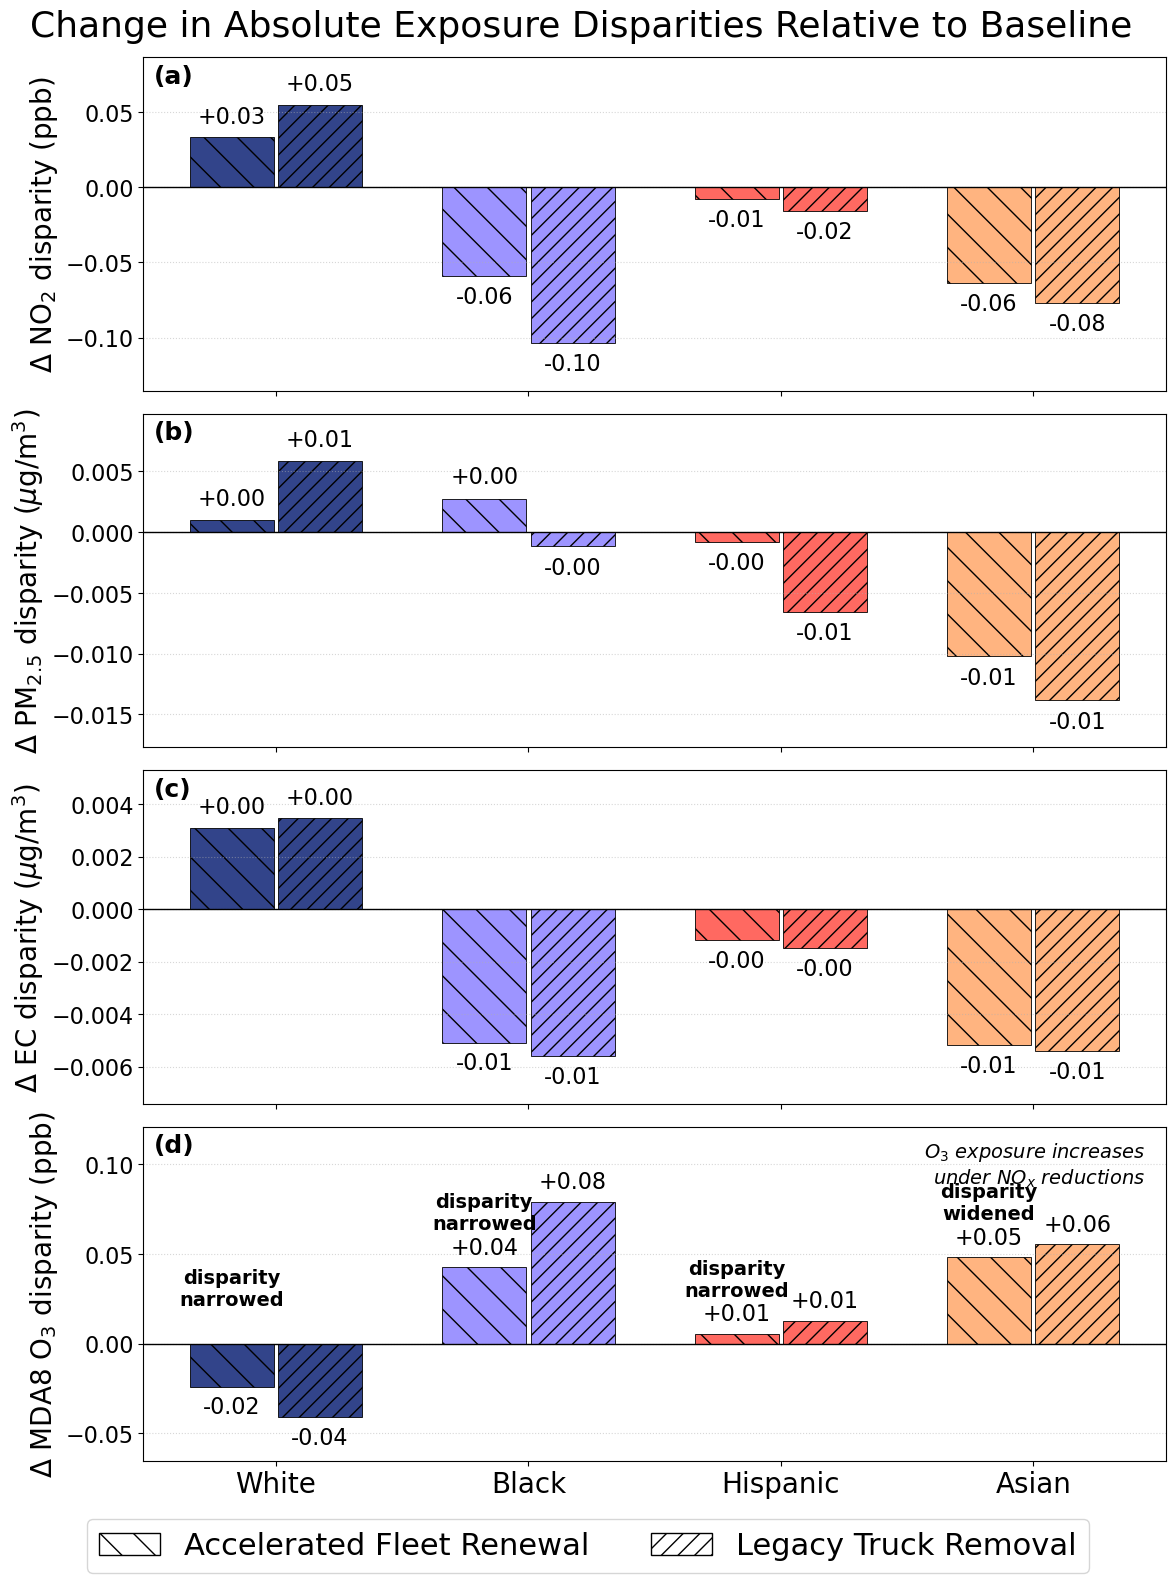

In [31]:
subgroups = ["White", "Black", "Hispanic", "Asian"]

scenario_keys = ["Renewal", "zeropre2010s"]
scenario_labels = ["Accelerated Fleet Renewal", "Legacy Truck Removal"]

hatches = {
    "Renewal": "\\",
    "zeropre2010s": "//"
}

colors = {
    "White": "#32448A",
    "Black": "#9d94ff",
    "Hispanic": "#ff6961",
    "Asian": "#ffb480"
}

fig, axes = plt.subplots(4, 1, figsize=(12, 16), sharex=True)

x = np.arange(len(subgroups))
cluster_w = 0.7
bar_w = cluster_w / len(scenario_keys)

offsets = (
    np.arange(len(scenario_keys))
    - (len(scenario_keys) - 1) / 2
) * bar_w


def plot_disparity_change_panel(
    ax,
    df,
    ylabel,
    panel,
    ozone=False
):

    # --------------------------------------------------------
    # Calculate changes relative to baseline
    # --------------------------------------------------------

    changes = []

    for key in scenario_keys:
        for g in subgroups:

            change = (
                df.loc[g, f"{key}_Absolute"]
                - df.loc[g, "Base_Absolute"]
            )

            changes.append(change)

    changes = np.array(changes)

    pad = np.nanmax(np.abs(changes)) * 0.06


    # --------------------------------------------------------
    # Bars
    # --------------------------------------------------------

    for s, key in enumerate(scenario_keys):

        for i, g in enumerate(subgroups):

            # Change in absolute disparity relative to baseline
            change = (
                df.loc[g, f"{key}_Absolute"]
                - df.loc[g, "Base_Absolute"]
            )

            ax.bar(
                x[i] + offsets[s],
                change,
                width=bar_w * 0.95,
                color=colors[g],
                hatch=hatches[key],
                edgecolor="black",
                linewidth=0.6
            )


            # ------------------------------------------------
            # Numeric bar labels
            # ------------------------------------------------

            ax.text(
                x[i] + offsets[s],
                change + pad if change >= 0 else change - pad,
                f"{change:+.2f}",
                ha="center",
                va="bottom" if change >= 0 else "top",
                fontsize=16
            )


    # --------------------------------------------------------
    # SPECIAL O3 INTERPRETATION
    # --------------------------------------------------------

    if ozone:

        for i, g in enumerate(subgroups):

            base_disp = df.loc[g, "Base_Absolute"]
            renewal_disp = df.loc[g, "Renewal_Absolute"]

            # Did the magnitude of the disparity increase?
            if abs(renewal_disp) > abs(base_disp):
                text = "disparity\nwidened"

            elif abs(renewal_disp) < abs(base_disp):
                text = "disparity\nnarrowed"

            else:
                text = "unchanged"

            # Place text near the Renewal bar
            renewal_change = (
                df.loc[g, "Renewal_Absolute"]
                - df.loc[g, "Base_Absolute"]
            )

            ypos = (
                renewal_change + pad * 4
                if renewal_change >= 0
                else pad * 4
            )

            ax.text(
                x[i] + offsets[0],
                ypos,
                text,
                ha="center",
                va="bottom",
                fontsize=14,
                fontweight="bold"
            )


        # Small explanatory note inside O3 panel
        ax.text(
            0.98,
            0.96,
            "O$_3$ exposure increases\nunder NO$_x$ reductions",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=14,
            fontstyle="italic"
        )


    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.axhline(
        0,
        color="black",
        linewidth=1
    )

    ax.set_ylabel(
        ylabel,
        fontsize=20
    )

    ax.tick_params(
        axis="y",
        labelsize=16
    )

    ax.grid(
        axis="y",
        linestyle=":",
        alpha=0.5
    )

    ax.text(
        0.01,
        0.98,
        panel,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="top",
        ha="left"
    )


    # --------------------------------------------------------
    # Y limits
    # --------------------------------------------------------

    ymin = np.nanmin(changes)
    ymax = np.nanmax(changes)

    yrange = ymax - ymin

    if yrange == 0:
        yrange = 1

    # More room for O3 interpretation labels
    upper_pad = 0.35 if ozone else 0.20

    ax.set_ylim(
        min(0, ymin) - 0.20 * yrange,
        max(0, ymax) + upper_pad * yrange
    )


# ============================================================
# Panels
# ============================================================

plot_disparity_change_panel(
    axes[0],
    no2_summary,
    r"$\Delta$ NO$_2$ disparity (ppb)",
    "(a)"
)

plot_disparity_change_panel(
    axes[1],
    pm25_tot_summary,
    r"$\Delta$ PM$_{2.5}$ disparity ($\mu$g/m$^3$)",
    "(b)"
)

plot_disparity_change_panel(
    axes[2],
    pm25_ec_summary,
    r"$\Delta$ EC disparity ($\mu$g/m$^3$)",
    "(c)"
)

plot_disparity_change_panel(
    axes[3],
    O3_summary,
    r"$\Delta$ MDA8 O$_3$ disparity (ppb)",
    "(d)",
    ozone=True
)


# ============================================================
# X axis
# ============================================================

axes[3].set_xticks(x)

axes[3].set_xticklabels(
    subgroups,
    fontsize=20
)


# ============================================================
# Scenario legend
# ============================================================

scenario_patches = [

    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        hatch=hatches[k],
        label=scenario_labels[i]
    )

    for i, k in enumerate(scenario_keys)
]


fig.suptitle(
    "Change in Absolute Exposure Disparities Relative to Baseline",
    fontsize=26,
    y=0.99
)

fig.legend(
    handles=scenario_patches,
    fontsize=22,
    loc="lower center",
    ncol=2,
    frameon=True
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)

plt.show()

In [32]:
# ============================================================
# CREATE RACE / ETHNICITY PERCENTAGE COLUMNS
# ============================================================

# Total population
total_pop = full_merged["ASOAE001"]

# Population counts
full_merged["Hispanic_pop"] = full_merged["ASOAE012"]
full_merged["Asian_pop"] = full_merged["ASOAE006"]
full_merged["Black_pop"] = full_merged["ASOAE004"]
full_merged["White_pop"] = full_merged["ASOAE003"]

# All remaining population groups
full_merged["Other_pop"] = (
    total_pop
    - full_merged["Hispanic_pop"]
    - full_merged["Asian_pop"]
    - full_merged["Black_pop"]
    - full_merged["White_pop"]
)

full_merged["Other_pop"] = full_merged["Other_pop"].clip(lower=0)


# Convert population counts to tract-level percentages
full_merged["Prc_Hispanic"] = (
    full_merged["Hispanic_pop"] / total_pop
) * 100

full_merged["Prc_Asian"] = (
    full_merged["Asian_pop"] / total_pop
) * 100

full_merged["Prc_Black"] = (
    full_merged["Black_pop"] / total_pop
) * 100

full_merged["Prc_White"] = (
    full_merged["White_pop"] / total_pop
) * 100

full_merged["Prc_Other"] = (
    full_merged["Other_pop"] / total_pop
) * 100


# Remove values from zero-population tracts
race_percent_columns = [
    "Prc_Hispanic",
    "Prc_Asian",
    "Prc_Black",
    "Prc_White",
    "Prc_Other"
]

full_merged[race_percent_columns] = (
    full_merged[race_percent_columns]
    .replace([np.inf, -np.inf], np.nan)
)

C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
C:\Users\x12la\anaconda3\lib\site-packages\geopandas\geodataframe.py:1443: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consid

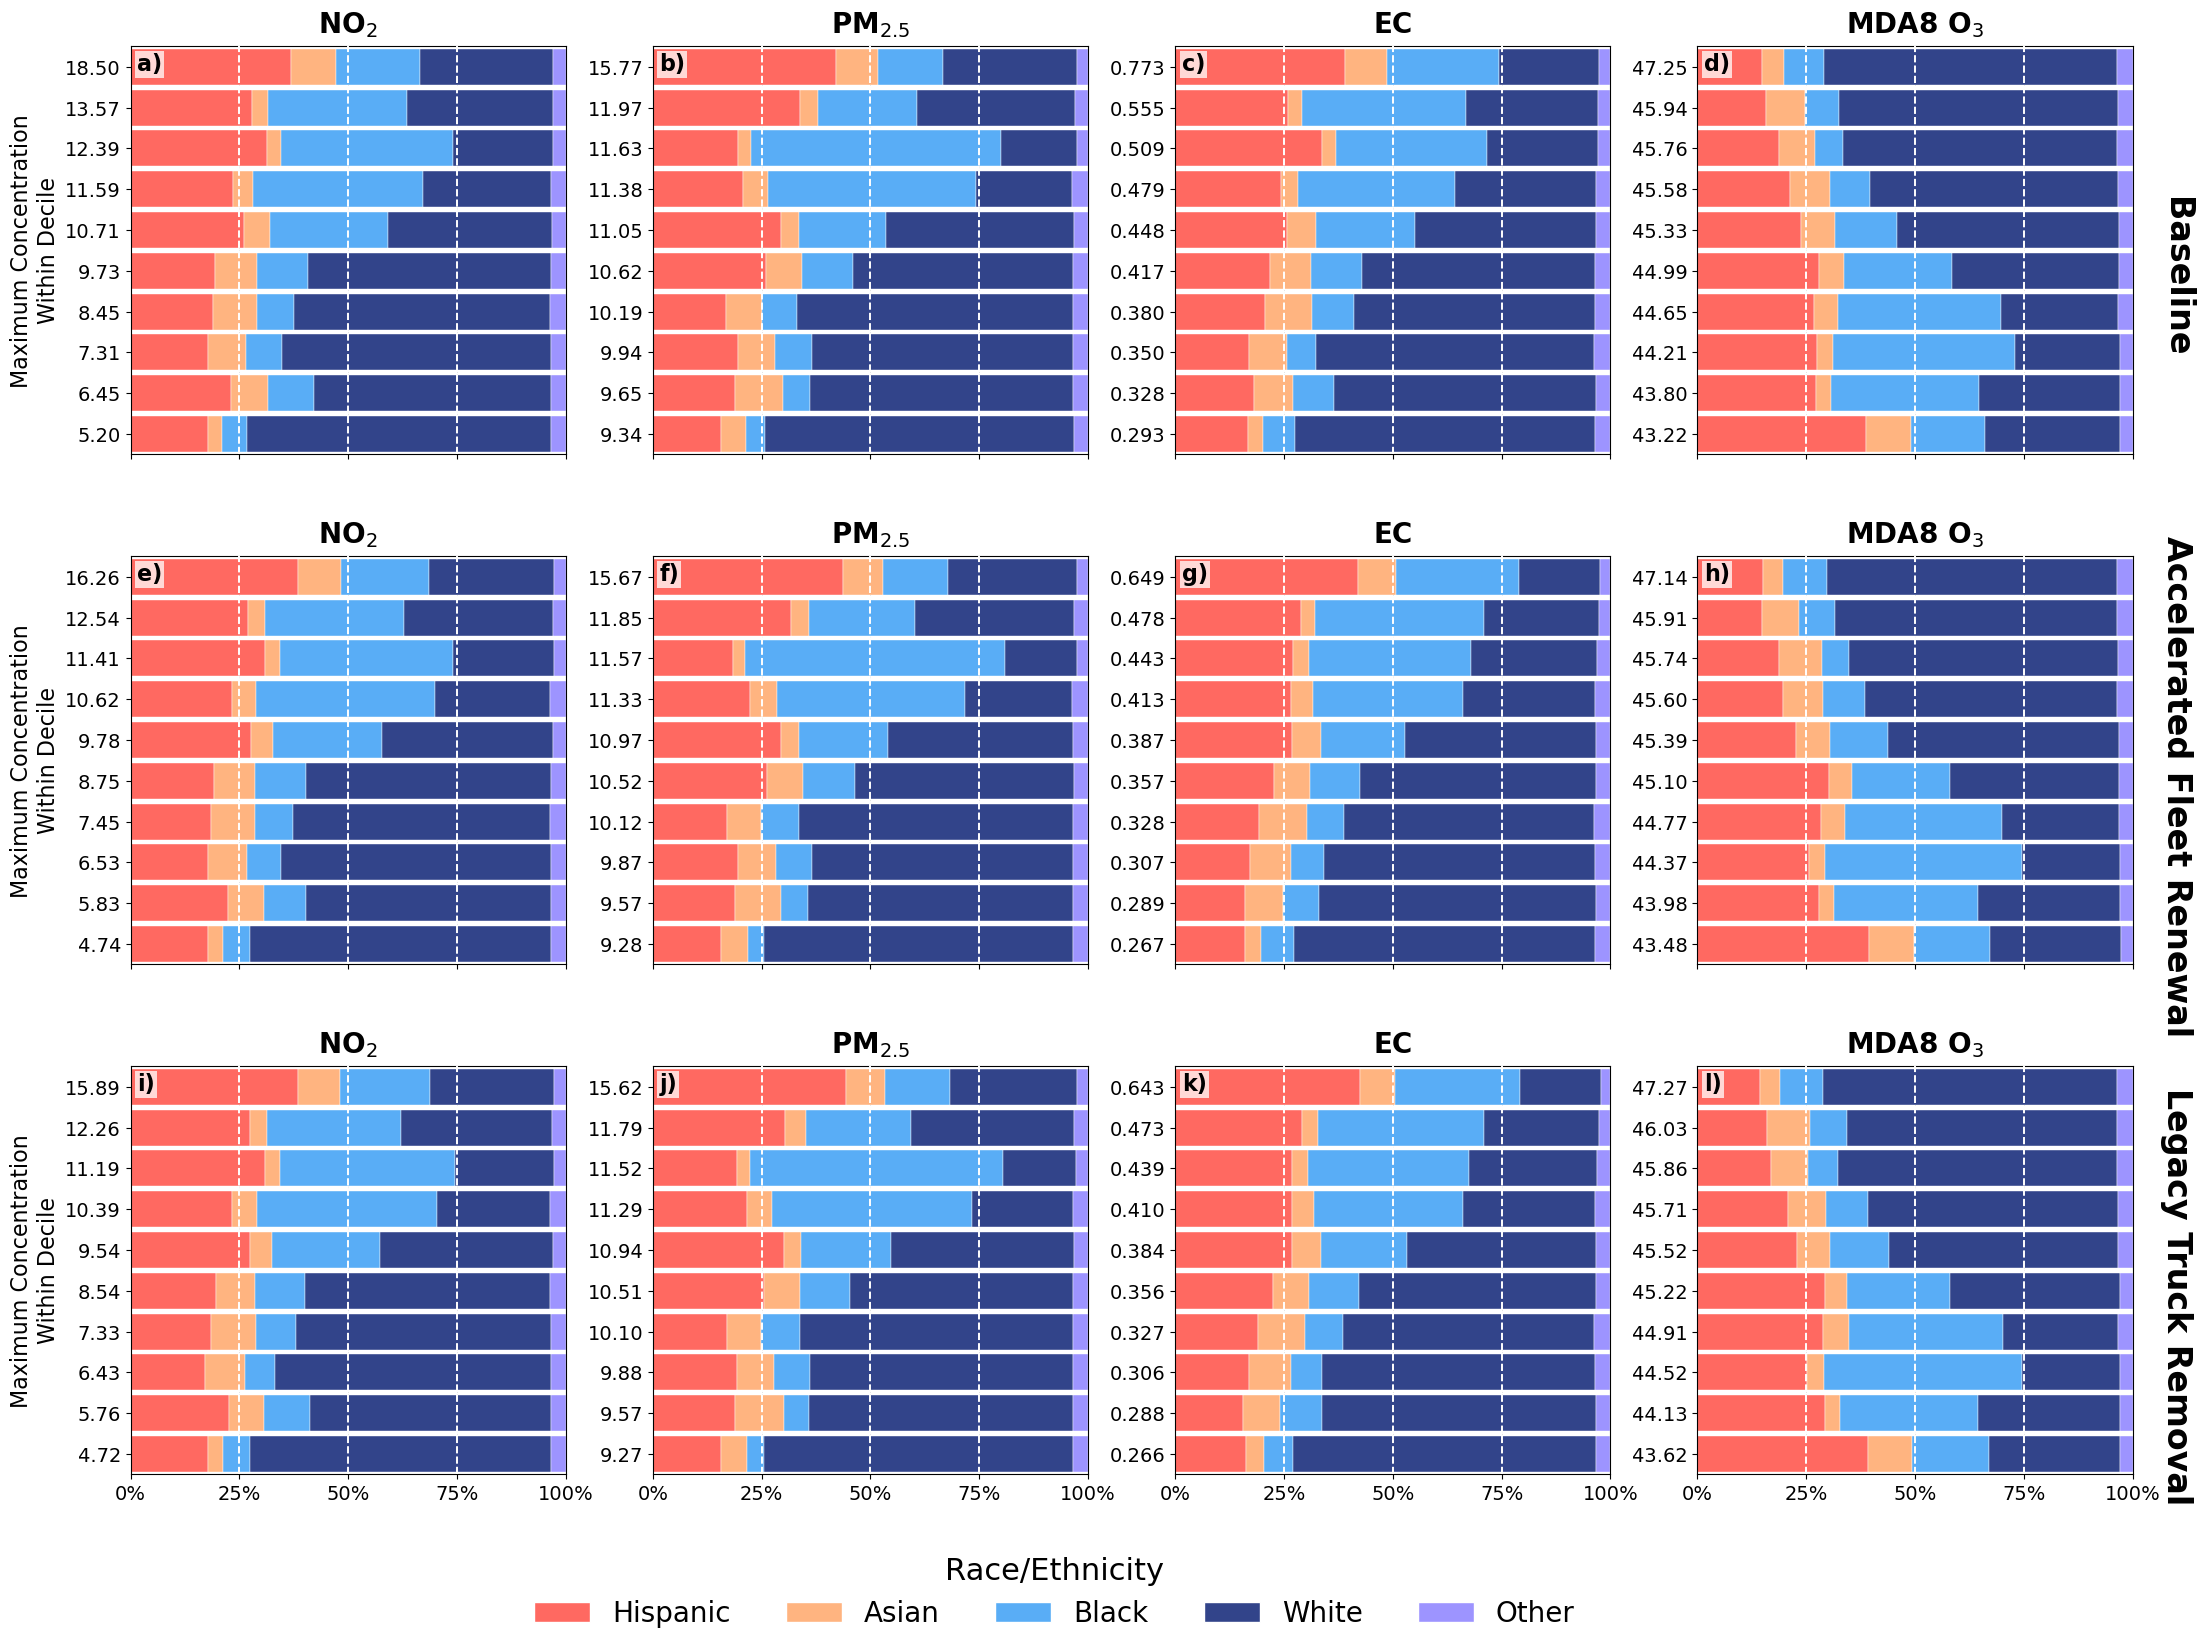

In [33]:
# ============================================================
# CREATE 3 × 4 MULTIPOLLUTANT EXPOSURE-DECILE FIGURE
# ============================================================

from matplotlib.patches import Patch

race_columns = [
    "Prc_Hispanic",
    "Prc_Asian",
    "Prc_Black",
    "Prc_White",
    "Prc_Other"
]

race_labels = [
    "Hispanic",
    "Asian",
    "Black",
    "White",
    "Other"
]

race_colors = [
    "#ff6961",
    "#ffb480",
    "#59adf6",
    "#32448A",
    "#9d94ff"
]

pollutants = [
    {
        "base_column": "base_NO2",
        "renewal_column": "renewal_NO2",
        "legacy_column": "zeropre2010s_NO2",
        "label": "NO$_2$",
        "units": "ppb",
        "decimals": 2
    },
    {
        "base_column": "base_PM25_TOT",
        "renewal_column": "renewal_PM25_TOT",
        "legacy_column": "zeropre2010s_PM25_TOT",
        "label": "PM$_{2.5}$",
        "units": r"$\mu$g m$^{-3}$",
        "decimals": 2
    },
    {
        "base_column": "base_PM25_EC",
        "renewal_column": "renewal_PM25_EC",
        "legacy_column": "zeropre2010s_PM25_EC",
        "label": "EC",
        "units": r"$\mu$g m$^{-3}$",
        "decimals": 3
    },
    {
        "base_column": "base_O3",
        "renewal_column": "renewal_O3",
        "legacy_column": "zeropre2010s_O3",
        "label": "MDA8 O$_3$",
        "units": "ppb",
        "decimals": 2
    }
]

def create_exposure_deciles(df, exposure_column):
    result = df.copy()

    valid_mask = (
        result[exposure_column].notna()
        & result["ASOAE001"].notna()
        & (result["ASOAE001"] > 0)
    )

    result["Exposure"] = np.nan
    result["Exposure_decile"] = np.nan

    result.loc[valid_mask, "Exposure"] = result.loc[valid_mask, exposure_column]

    result.loc[valid_mask, "Exposure_decile"] = (
        pd.qcut(
            result.loc[valid_mask, exposure_column],
            q=10,
            labels=False,
            duplicates="drop"
        ) + 1
    )

    return result

def calculate_race_distribution(df):
    return (
        df.groupby("Exposure_decile")[race_columns]
        .mean()
        .reindex(range(1, 11))
    )

def plot_decile_panel(ax, df, pollutant_label, units, decimals, show_y_label=False):
    plot_df = df[
        df["Exposure_decile"].notna()
        & df["Exposure"].notna()
        & df["ASOAE001"].notna()
        & (df["ASOAE001"] > 0)
    ].copy()

    plot_df["Exposure_decile"] = plot_df["Exposure_decile"].astype(int)

    race_distribution = calculate_race_distribution(plot_df)

    y_positions = np.arange(10)
    left_values = np.zeros(10)

    for race_column, race_color in zip(race_columns, race_colors):
        values = race_distribution[race_column].fillna(0).to_numpy()

        ax.barh(
            y_positions,
            values,
            left=left_values,
            height=0.88,
            color=race_color,
            edgecolor="white",
            linewidth=0.3
        )

        left_values += values

    max_values = (
        plot_df.groupby("Exposure_decile")["Exposure"]
        .max()
        .reindex(range(1, 11))
    )

    formatted_labels = [
        f"{value:.{decimals}f}" if pd.notna(value) else ""
        for value in max_values
    ]

    ax.set_yticks(y_positions)
    ax.set_yticklabels(formatted_labels, fontsize=14)

    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=14)

    for xv in [25, 50, 75]:
        ax.axvline(
            xv,
            color="white",
            linestyle="--",
            linewidth=1.4,
            zorder=5
        )

    ax.set_title(
        pollutant_label,
        fontsize=20,
        fontweight="bold",
        pad=10
    )

    if show_y_label:
        ax.set_ylabel(
            "Maximum Concentration\nWithin Decile",
            fontsize=16
        )
    else:
        ax.set_ylabel("")

    ax.set_ylim(-0.5, 9.5)
    ax.grid(axis="x", linestyle=":", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)


# ============================================================
# BUILD 3 × 4 FIGURE
# ============================================================

fig, axs = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(22, 17),
    sharex=True,
    sharey=False
)

for column_index, pollutant in enumerate(pollutants):

    base_df = create_exposure_deciles(
        full_merged,
        pollutant["base_column"]
    )

    renewal_df = create_exposure_deciles(
        full_merged,
        pollutant["renewal_column"]
    )

    legacy_df = create_exposure_deciles(
        full_merged,
        pollutant["legacy_column"]
    )

    plot_decile_panel(
        axs[0, column_index],
        base_df,
        pollutant["label"],
        pollutant["units"],
        pollutant["decimals"],
        show_y_label=(column_index == 0)
    )

    plot_decile_panel(
        axs[1, column_index],
        renewal_df,
        pollutant["label"],
        pollutant["units"],
        pollutant["decimals"],
        show_y_label=(column_index == 0)
    )

    plot_decile_panel(
        axs[2, column_index],
        legacy_df,
        pollutant["label"],
        pollutant["units"],
        pollutant["decimals"],
        show_y_label=(column_index == 0)
    )


# ============================================================
# ROW LABELS
# ============================================================

fig.text(
    1.01, 0.805,
    "Baseline",
    rotation=270,
    va="center",
    ha="center",
    fontsize=24,
    fontweight="bold"
)

fig.text(
    1.01, 0.505,
    "Accelerated Fleet Renewal",
    rotation=270,
    va="center",
    ha="center",
    fontsize=24,
    fontweight="bold"
)

fig.text(
    1.01, 0.205,
    "Legacy Truck Removal",
    rotation=270,
    va="center",
    ha="center",
    fontsize=24,
    fontweight="bold"
)


# ============================================================
# PANEL LABELS
# ============================================================

panel_labels = [
    "a)", "b)", "c)", "d)",
    "e)", "f)", "g)", "h)",
    "i)", "j)", "k)", "l)"
]

for ax, panel_label in zip(axs.flatten(), panel_labels):
    ax.text(
        0.015,
        0.985,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=16,
        fontweight="bold",
        color="black",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.75,
            pad=1.5
        )
    )


# ============================================================
# SHARED LEGEND
# ============================================================

legend_handles = [
    Patch(
        facecolor=color,
        edgecolor="white",
        label=label
    )
    for color, label in zip(race_colors, race_labels)
]

fig.legend(
    handles=legend_handles,
    labels=race_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.005),
    ncol=5,
    title="Race/Ethnicity",
    fontsize=20,
    title_fontsize=22,
    frameon=False
)


# ============================================================
# FINAL FORMATTING
# ============================================================

plt.subplots_adjust(
    left=0.08,
    right=0.99,
    top=0.94,
    bottom=0.10,
    wspace=0.20,
    hspace=0.25
)

plt.savefig(
    "Multipollutant_Exposure_Deciles_RaceEthnicity_3x4.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [93]:
groups = ["White", "Black", "Hispanic", "Asian", "Other"]

# Build legacy-attributable and renewal-remaining exposure

def get_legacy_exposure(summary_df):
    out = pd.DataFrame(index=groups)
    # Pollution attributable to legacy trucks
    out["Legacy attributable"] = (summary_df.loc[groups, "Base_PopWeighted"] - summary_df.loc[groups, "zeropre2010s_PopWeighted"]  )
    # Legacy-truck pollution remaining after renewal
    out["Remaining after renewal"] = (summary_df.loc[groups, "Renewal_PopWeighted"]  - summary_df.loc[groups, "zeropre2010s_PopWeighted"] )
    # Pollution removed by accelerated renewal
    out["Removed by renewal"] = (summary_df.loc[groups, "Base_PopWeighted"]  - summary_df.loc[groups, "Renewal_PopWeighted"] )
    # Fraction of legacy-attributable burden eliminated
    out["Fraction eliminated"] = (out["Removed by renewal"] / out["Legacy attributable"] * 100)
    return out

no2_legacy = get_legacy_exposure(no2_summary)
pm25_legacy = get_legacy_exposure(pm25_tot_summary)
ec_legacy = get_legacy_exposure(pm25_ec_summary)
o3_legacy = get_legacy_exposure(O3_summary)

In [94]:
print("NO2")
display(no2_legacy)

print("PM2.5")
display(pm25_legacy)

print("EC")
display(ec_legacy)

print("MDA8 O3")
display(o3_legacy)

NO2


,Legacy attributable,Remaining after renewal,Removed by renewal,Fraction eliminated
White,0.930758,0.134562,0.796196,85.542739
Black,1.089014,0.200923,0.888090,81.549969
Hispanic,1.001209,0.164144,0.837065,83.605434
Asian,1.062469,0.169673,0.892797,84.030338
Other,0.975926,0.152742,0.823184,84.348977


PM2.5


,Legacy attributable,Remaining after renewal,Removed by renewal,Fraction eliminated
White,0.087400,0.017717,0.069683,79.728647
Black,0.094378,0.026451,0.067926,71.972834
Hispanic,0.099752,0.028284,0.071468,71.645678
Asian,0.107019,0.026112,0.080907,75.600806
Other,0.092438,0.021725,0.070713,76.497580


EC


,Legacy attributable,Remaining after renewal,Removed by renewal,Fraction eliminated
White,0.051356,0.001356,0.050001,97.360307
Black,0.060435,0.002239,0.058197,96.295800
Hispanic,0.056321,0.002030,0.054292,96.396443
Asian,0.060234,0.001943,0.058291,96.774741
Other,0.054331,0.001651,0.052680,96.961212


MDA8 O3


,Legacy attributable,Remaining after renewal,Removed by renewal,Fraction eliminated
White,-0.751688,-0.109377,-0.642311,85.449113
Black,-0.871737,-0.162709,-0.709029,81.335126
Hispanic,-0.805500,-0.133744,-0.671756,83.396182
Asian,-0.848260,-0.133636,-0.714624,84.245831
Other,-0.786468,-0.123346,-0.663122,84.316419


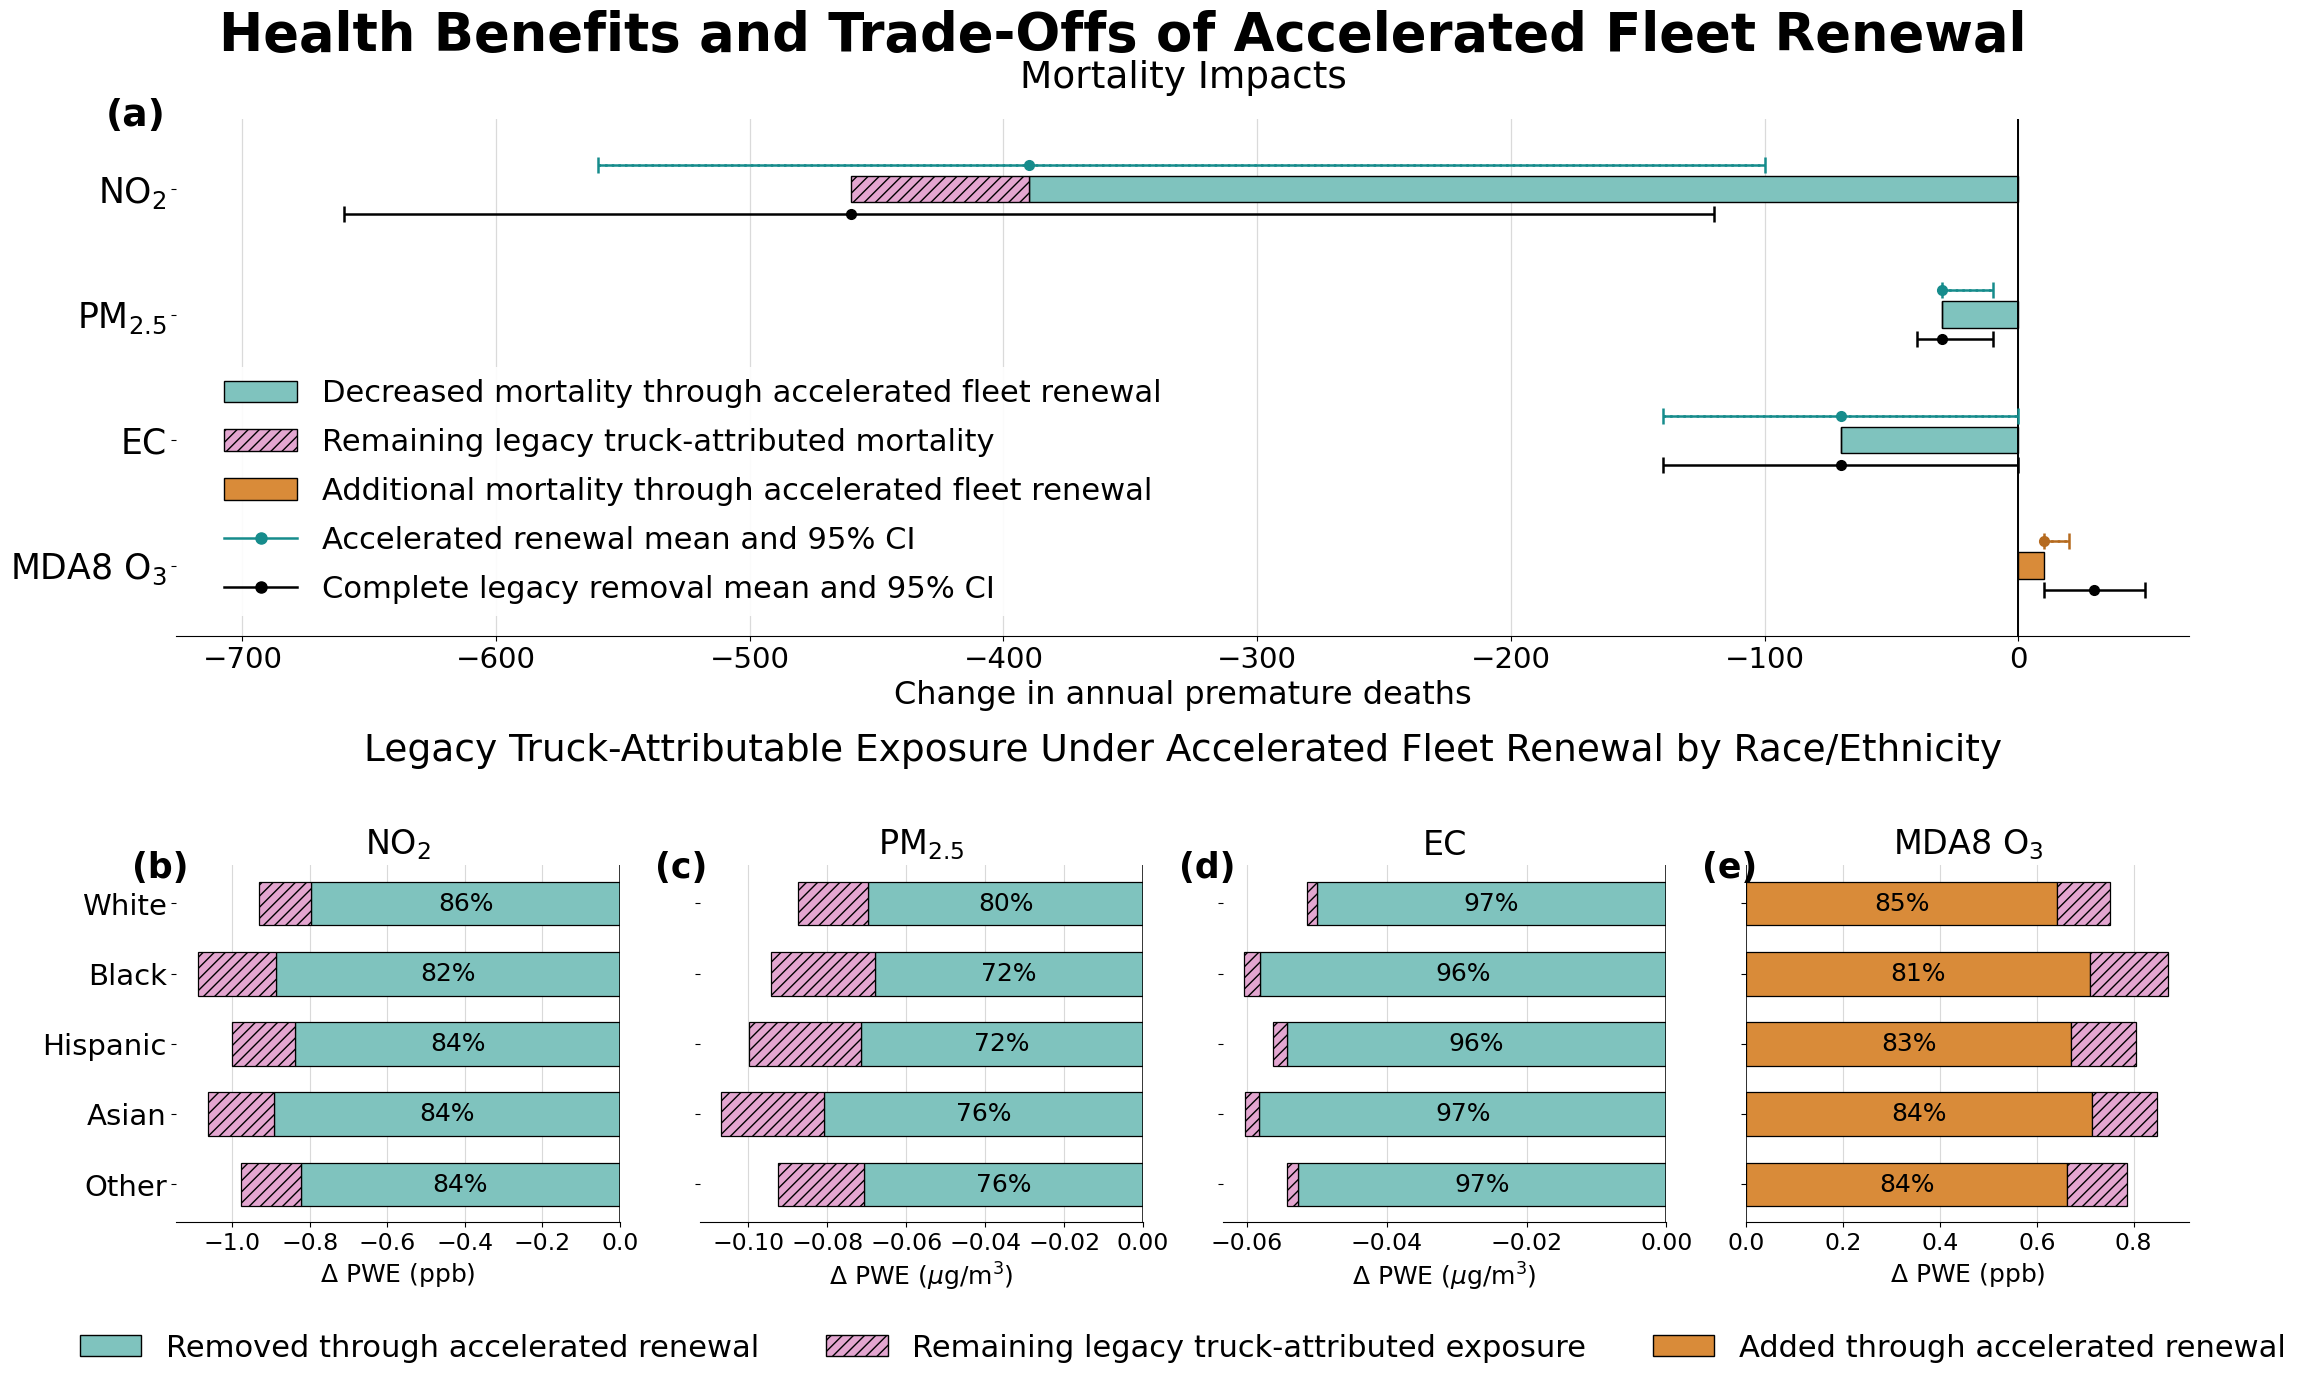

In [99]:
from matplotlib.lines import Line2D

# plotting colors
renewal_color = "#7FC3BE"
remaining_color = "#E3A6D0"
legacy_ci_color = "black"
renewal_ci_color = "#168C8C"
o3_color = "#D98B39"
o3_ci_color = "#B56A1F"

benefit_order = ["NO2", "PM25_TOT", "PM25_EC"]


# pull the mortality estimates and make decreases negative
def get_mortality_estimates(metric):
    df = mortality_summary[(mortality_summary["Metric"] == metric) & mortality_summary["Pollutant"].isin(benefit_order)].set_index("Pollutant").reindex(benefit_order)

    total = -df["Total"].abs().to_numpy()
    lower = np.minimum(-df["Lower"].abs(), -df["Upper"].abs()).to_numpy()
    upper = np.maximum(-df["Lower"].abs(), -df["Upper"].abs()).to_numpy()

    return total, lower, upper


legacy_total, legacy_lower, legacy_upper = get_mortality_estimates("zeropre2010s_minus_base")
renewal_total, renewal_lower, renewal_upper = get_mortality_estimates("renewal_minus_base")

health_plot = pd.DataFrame({
    "Pollutant": benefit_order,
    "Legacy attributable": legacy_total,
    "Legacy lower": legacy_lower,
    "Legacy upper": legacy_upper,
    "Avoided through renewal": renewal_total,
    "Avoided lower": renewal_lower,
    "Avoided upper": renewal_upper,
})

# round the mortality estimates and confidence intervals to the nearest 10
mortality_columns = health_plot.columns.drop("Pollutant")
health_plot[mortality_columns] = health_plot[mortality_columns].div(10).round().mul(10)

# calculate the legacy-attributable mortality remaining after renewal
health_plot["Remaining after renewal"] = health_plot["Legacy attributable"] - health_plot["Avoided through renewal"]


# pull and round the ozone mortality estimate and confidence interval
def get_o3_mortality(metric):
    row = mortality_summary[(mortality_summary["Metric"] == metric) & (mortality_summary["Pollutant"] == "O3_Turner2016")].iloc[0]

    total = round(abs(row["Total"]) / 10) * 10
    lower = round(min(abs(row["Lower"]), abs(row["Upper"])) / 10) * 10
    upper = round(max(abs(row["Lower"]), abs(row["Upper"])) / 10) * 10

    return total, lower, upper


o3_renewal = get_o3_mortality("renewal_minus_base")
o3_removal = get_o3_mortality("zeropre2010s_minus_base")
o3_legacy = get_legacy_exposure(O3_summary)

# define the exposure data and formatting for each pollutant panel
plot_data = [
    (no2_legacy, "NO$_2$", "$\\Delta$ PWE (ppb)", False),
    (pm25_legacy, "PM$_{2.5}$", "$\\Delta$ PWE ($\\mu$g/m$^3$)", False),
    (ec_legacy, "EC", "$\\Delta$ PWE ($\\mu$g/m$^3$)", False),
    (o3_legacy, "MDA8 O$_3$", "$\\Delta$ PWE (ppb)", True),
]

groups = ["White", "Black", "Hispanic", "Asian", "Other"]

# create the figure layout
fig = plt.figure(figsize=(22, 14.5))
fig.suptitle("Health Benefits and Trade-Offs of Accelerated Fleet Renewal", fontsize=38, fontweight="bold", y=0.995)

gs = fig.add_gridspec(4, 4, height_ratios=[1.45, 0.12, 1.0, 0.18], hspace=0.38, wspace=0.18)

ax_health = fig.add_subplot(gs[0, :])
ax_exposure_heading = fig.add_subplot(gs[1, :])
axs_exp = [fig.add_subplot(gs[2, column]) for column in range(4)]
ax_exposure_legend = fig.add_subplot(gs[3, :])

ax_exposure_heading.axis("off")
ax_exposure_legend.axis("off")

# plot the mortality results
health_labels = ["NO$_2$", "PM$_{2.5}$", "EC", "MDA8 O$_3$"]

y = np.arange(4) * 1.28
y_benefit = y[:3]
o3_y = y[3]

bar_height = 0.27
renewal_ci_offset = -0.25
legacy_ci_offset = 0.25

# avoided mortality through renewal
ax_health.barh(y_benefit, health_plot["Avoided through renewal"], height=bar_height, color=renewal_color, edgecolor="black", linewidth=1)

# legacy-attributable mortality remaining after renewal
ax_health.barh(y_benefit, health_plot["Remaining after renewal"], left=health_plot["Avoided through renewal"], height=bar_height, color=remaining_color, edgecolor="black", linewidth=1, hatch="///")

# additional ozone mortality through renewal
ax_health.barh(o3_y, o3_renewal[0], height=bar_height, color=o3_color, edgecolor="black", linewidth=1)
ax_health.axvline(0, color="black", linewidth=1.4, zorder=3)


# add the mortality estimate and confidence interval
def add_confidence_interval(ax, estimate, lower, upper, y_position, color, dotted=False):
    estimate = np.asarray(estimate)
    lower = np.asarray(lower)
    upper = np.asarray(upper)

    ax.errorbar(estimate, y_position, xerr=np.vstack([estimate - lower, upper - estimate]), fmt="o", color=color, ecolor=color, elinewidth=1.8, capsize=6, capthick=1.8, markersize=7, linestyle="none", zorder=7)

    # use a dotted line for the accelerated-renewal confidence interval
    if dotted:
        for y_value, low, high in zip(np.atleast_1d(y_position), lower, upper):
            ax.hlines(y_value, low, high, color=color, linewidth=1.8, linestyle=":")


# add the accelerated-renewal and complete-removal confidence intervals
add_confidence_interval(ax_health, health_plot["Avoided through renewal"], health_plot["Avoided lower"], health_plot["Avoided upper"], y_benefit + renewal_ci_offset, renewal_ci_color, dotted=True)
add_confidence_interval(ax_health, health_plot["Legacy attributable"], health_plot["Legacy lower"], health_plot["Legacy upper"], y_benefit + legacy_ci_offset, legacy_ci_color)

# add the ozone confidence intervals
add_confidence_interval(ax_health, [o3_renewal[0]], [o3_renewal[1]], [o3_renewal[2]], [o3_y + renewal_ci_offset], o3_ci_color, dotted=True)
add_confidence_interval(ax_health, [o3_removal[0]], [o3_removal[1]], [o3_removal[2]], [o3_y + legacy_ci_offset], legacy_ci_color)

# format the mortality panel
health_xmin = min(health_plot["Legacy lower"].min(), health_plot["Avoided lower"].min()) * 1.10
health_xmax = max(50, o3_renewal[2] * 1.35, o3_removal[2] * 1.35)

ax_health.set_yticks(y)
ax_health.set_yticklabels(health_labels, fontsize=25)
ax_health.set_ylim(y[-1] + 0.72, y[0] - 0.72)
ax_health.set_xlim(health_xmin, health_xmax)
ax_health.set_xlabel("Change in annual premature deaths", fontsize=23)
ax_health.set_title("Mortality Impacts", fontsize=27, pad=22)
ax_health.tick_params(axis="x", labelsize=21)
ax_health.grid(axis="x", alpha=0.46, linewidth=0.9)
ax_health.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax_health.spines[spine].set_visible(False)

ax_health.text(-0.035, 1.04, "(a)", transform=ax_health.transAxes, ha="left", va="top", fontsize=27, fontweight="bold")

# add the mortality legend inside the lower-left corner of panel a
health_legend = [
    Patch(facecolor=renewal_color, edgecolor="black", label="Decreased mortality through accelerated fleet renewal"),
    Patch(facecolor=remaining_color, edgecolor="black", hatch="///", label="Remaining legacy truck-attributed mortality"),
    Patch(facecolor=o3_color, edgecolor="black", label="Additional mortality through accelerated fleet renewal"),
    Line2D([0], [0], color=renewal_ci_color, marker="o", markersize=8, linewidth=1.8, label="Accelerated renewal mean and 95% CI"),
    Line2D([0], [0], color=legacy_ci_color, marker="o", markersize=8, linewidth=1.8, label="Complete legacy removal mean and 95% CI"),
]

ax_health.legend(handles=health_legend, loc="lower left", bbox_to_anchor=(0.01, 0.01), ncol=1, fontsize=22, handlelength=2.4, labelspacing=0.65, frameon=True, facecolor="white", edgecolor="none", framealpha=0.90)

# plot exposure changes by race/ethnicity
y_exp = np.arange(len(groups))
exposure_bar_height = 0.62

for i, (ax, (df, title, xlabel, is_o3)) in enumerate(zip(axs_exp, plot_data)):
    # exposure reductions are negative, while ozone increases are positive
    direction = 1 if is_o3 else -1

    removed = direction * df["Removed by renewal"].abs().to_numpy()
    remaining = direction * df["Remaining after renewal"].abs().to_numpy()
    eliminated = df["Fraction eliminated"].to_numpy()
    bar_color = o3_color if is_o3 else renewal_color

    ax.barh(y_exp, removed, height=exposure_bar_height, color=bar_color, edgecolor="black", linewidth=0.9)
    ax.barh(y_exp, remaining, left=removed, height=exposure_bar_height, color=remaining_color, edgecolor="black", linewidth=0.9, hatch="///")

    # label the fraction of the legacy contribution removed through renewal
    for row, (value, percentage) in enumerate(zip(removed, eliminated)):
        ax.text(value * 0.50, row, f"{percentage:.0f}%", ha="center", va="center", fontsize=18, color="black")

    ax.set_title(title, fontsize=24, pad=8)
    ax.set_xlabel(xlabel, fontsize=18)
    ax.set_yticks(y_exp)
    ax.set_yticklabels(groups if i == 0 else [], fontsize=21)
    ax.invert_yaxis()
    ax.axvline(0, color="black", linewidth=1.1)
    ax.tick_params(axis="x", labelsize=17)
    ax.grid(axis="x", alpha=0.48, linewidth=0.8)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.text(-0.10, 1.04, f"({chr(98 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=25, fontweight="bold")

# add the exposure heading
ax_exposure_heading.text(0.5, 0.5, "Legacy Truck-Attributable Exposure Under Accelerated Fleet Renewal by Race/Ethnicity", ha="center", va="center", fontsize=27)

# keep the exposure legend centered below the bottom panels
exposure_legend = [
    Patch(facecolor=renewal_color, edgecolor="black", label="Removed through accelerated renewal"),
    Patch(facecolor=remaining_color, edgecolor="black", hatch="///", label="Remaining legacy truck-attributed exposure"),
    Patch(facecolor=o3_color, edgecolor="black", label="Added through accelerated renewal"),]

ax_exposure_legend.legend(handles=exposure_legend, loc="center", ncol=3, frameon=False, fontsize=22, handlelength=2, columnspacing=2.2)

# save the figure
plt.subplots_adjust(left=0.07, right=0.985, top=0.92, bottom=0.05)
plt.savefig("Fig3_AcceleratedFleetRenewal_HealthBenefits_Tradeoffs.png", dpi=600, bbox_inches="tight")
plt.savefig("Fig3_AcceleratedFleetRenewal_HealthBenefits_Tradeoffs.pdf", dpi=300, bbox_inches="tight")
plt.show()